# КИВО: графики

**Это блокнот с графиками** для статьи и приложения. Расчёты здесь не повторяются: данные берутся из `data_clean.pkl` (после `cleaning.ipynb`); результаты моделей — в `analysis.ipynb`.

**Порядок запуска:** `cleaning.ipynb` → `figures.ipynb`. Все рисунки сохраняются в папку `figures/` (PNG, 300 dpi).

**Правила оформления**
- Доли показаны с 95% доверительными интервалами по Уилсону; у групп подписано n.
- Шкалы 1–4 показаны распределением ответов, а не средними.
- Волны — на отдельных панелях.
- У каждого формата занятости один цвет на всех рисунках.
- Частично заполненные анкеты 4-й волны (профили A/B) в графиках образования не показываются.

**Содержание**
1. Библиотеки, данные и стиль
2. Рисунок 1. Структура занятости и переходы между волнами
3. Рисунок 2. Рабочие часы по формату
4. Рисунок 3. Причины мыслей об отчислении по формату
5. Рисунок 4. Польза и трудности работы по соответствию специальности
6. Рисунок 5. Подтвердившиеся связи в долях
7. Рисунок 6. Планируемое распределение времени
8. Приложение: шкалы 1–4 и сферы работы
9. Рисунки по гипотезам (ИВ1–ИВ7)
10. Распределения всех аналитических переменных

## 1. Библиотеки, данные и стиль

`share_ci()` считает долю и 95% ДИ по Уилсону; `save()` сохраняет рисунок в `figures/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from statsmodels.stats.proportion import proportion_confint

full = pd.read_pickle('data_clean.pkl')
d = full[full['in_study']].copy()

FIG_DIR = Path('figures')
FIG_DIR.mkdir(exist_ok=True)

sns.set_theme(style='whitegrid', context='notebook', font_scale=1.0)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
                     'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.spines.top': False,
                     'axes.spines.right': False})

FORMATS = ['нет работы', 'подработки', 'неполный день', 'полный день']
FORMAT_COLORS = dict(zip(FORMATS, ['#bdbdbd', '#9ecae1', '#4292c6', '#08519c']))
WAVES = {'3': '3-я волна (3-й курс)', '4': '4-я волна (4-й курс)'}
percent = PercentFormatter(1.0, decimals=0)


def share_ci(series, value=1):
    '''Доля value, нижняя и верхняя граница 95% ДИ Уилсона, n.'''
    s = series.dropna()
    k, n = int((s == value).sum()), len(s)
    lo, hi = proportion_confint(k, n, method='wilson') if n else (np.nan, np.nan)
    return pd.Series({'доля': k / n if n else np.nan, 'от': lo, 'до': hi, 'n': n})


def save(fig, name):
    fig.savefig(FIG_DIR / f'{name}.png')
    print(f'Сохранено: figures/{name}.png')


print(f'Рабочий массив: {len(d)}')

Рабочий массив: 2022


## 2. Рисунок 1. Структура занятости и переходы между волнами

**Задачи:** З1.1, З7.1. Слева — доли форматов среди ответивших о работе в каждой волне. Справа — у ответивших в обеих волнах: куда пришли к 4-й волне студенты каждого формата 3-й волны.

Сохранено: figures/fig1_employment_structure.png


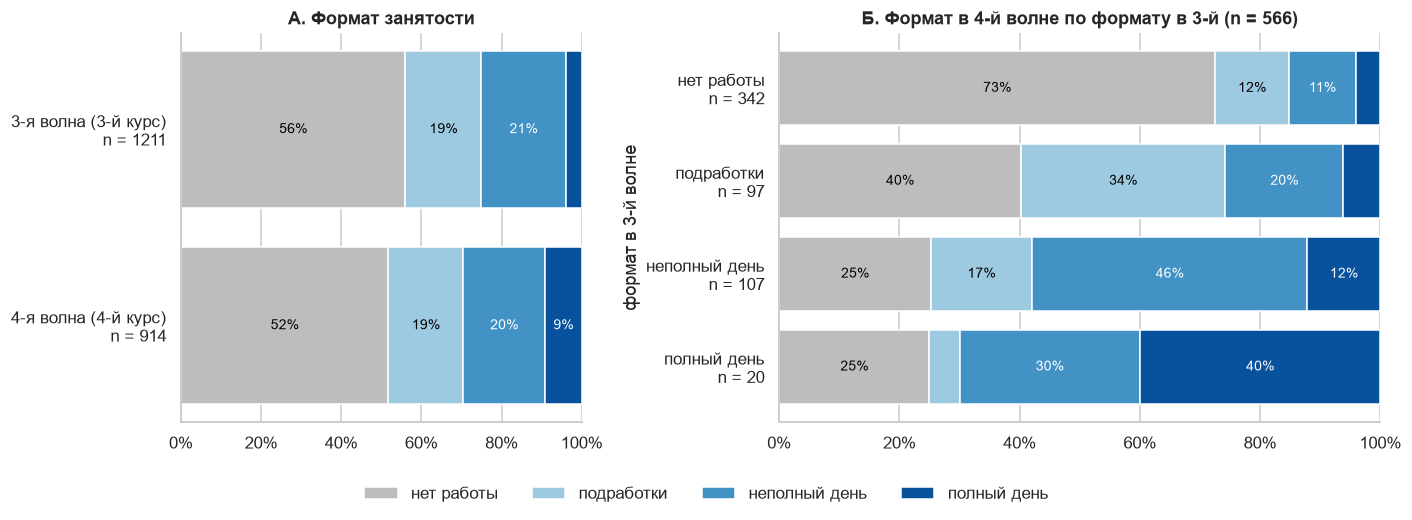

In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [1, 1.5]})

shares = pd.DataFrame({WAVES[w]: d.loc[d[f'fmt_{w}'].notna(), f'fmt_{w}'].astype(str).value_counts(normalize=True)
                       for w in ['3', '4']}).reindex(FORMATS).T
n_wave = {WAVES[w]: int(d[f'fmt_{w}'].notna().sum()) for w in ['3', '4']}
left = np.zeros(len(shares))
for fmt in FORMATS:
    ax1.barh(shares.index, shares[fmt], left=left, color=FORMAT_COLORS[fmt], label=fmt, edgecolor='white')
    for i, (l, v) in enumerate(zip(left, shares[fmt])):
        if v > 0.05:
            ax1.text(l + v / 2, i, f'{v:.0%}', ha='center', va='center', fontsize=9,
                     color='white' if fmt in ('неполный день', 'полный день') else 'black')
    left += shares[fmt].to_numpy()
ax1.set_yticks(range(len(shares)), [f'{w}\nn = {n_wave[w]}' for w in shares.index])
ax1.xaxis.set_major_formatter(percent)
ax1.set(xlim=(0, 1), title='А. Формат занятости')
ax1.invert_yaxis()

panel = d[d['trans4'].notna()]
trans = pd.crosstab(panel['fmt_3'].astype(str), panel['fmt_4'].astype(str), normalize='index').reindex(index=FORMATS,
                                                                                                    columns=FORMATS)
n_from = panel['fmt_3'].astype(str).value_counts().reindex(FORMATS)
left = np.zeros(len(trans))
for fmt in FORMATS:
    ax2.barh(range(len(trans)), trans[fmt], left=left, color=FORMAT_COLORS[fmt], edgecolor='white')
    for i, (l, v) in enumerate(zip(left, trans[fmt])):
        if v > 0.07:
            ax2.text(l + v / 2, i, f'{v:.0%}', ha='center', va='center', fontsize=9,
                     color='white' if fmt in ('неполный день', 'полный день') else 'black')
    left += trans[fmt].to_numpy()
ax2.set_yticks(range(len(trans)), [f'{f}\nn = {n}' for f, n in n_from.items()])
ax2.xaxis.set_major_formatter(percent)
ax2.set(xlim=(0, 1), title=f'Б. Формат в 4-й волне по формату в 3-й (n = {len(panel)})',
        ylabel='формат в 3-й волне')
ax2.invert_yaxis()
fig.legend(*ax1.get_legend_handles_labels(), loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(rect=(0, 0.05, 1, 1))
save(fig, 'fig1_employment_structure')
plt.show()

Около половины студентов не имели оплачиваемой работы: 56% на третьем курсе и 52% на четвёртом. Подработки и работа неполный день встречались с одинаковой частотой (около 20%). Доля работающих полный день к четвёртому курсу выросла с 4% до 9%. Занятость оказалась неустойчивой: из подрабатывавших на третьем курсе 40% к четвёртому не работали, а из работавших полный день сохранили этот формат лишь 40% (8 из 20). Из 342 студентов, не работавших на третьем курсе, 73% не начали работать и к четвёртому. Оценки для группы полного дня третьей волны опираются на 20 наблюдений и неточны.

## 3. Рисунок 2. Рабочие часы по формату

**Задача:** З1.1. Часы за прошлую неделю среди работающих; точки — отдельные ответы. Ось ограничена 100 часами; число значений выше подписано отдельно.

Сохранено: figures/fig2_hours_by_format.png


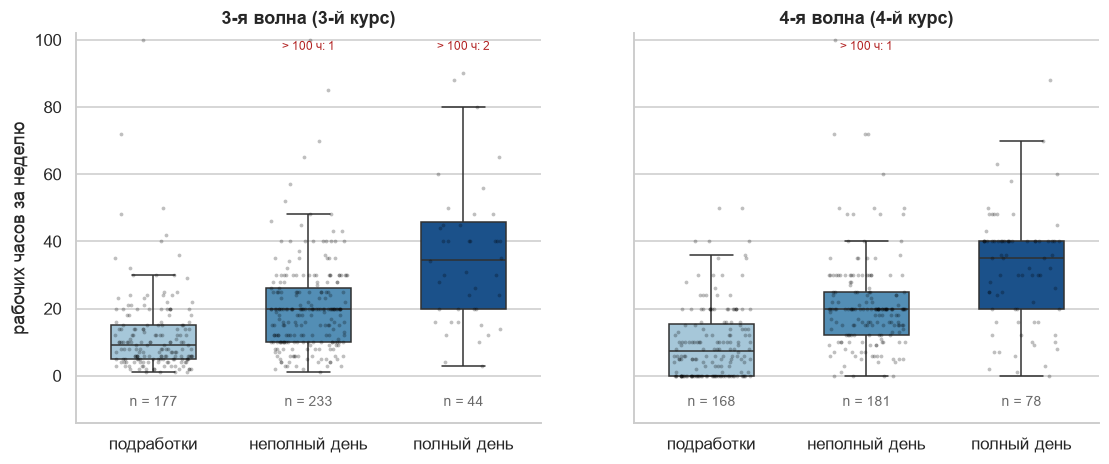

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, w in zip(axes, ['3', '4']):
    workers = d[d[f'emp_{w}'].eq(1) & d[f'hours_{w}'].notna()].assign(fmt=lambda f: f[f'fmt_{w}'].astype(str))
    order = FORMATS[1:]
    sns.boxplot(data=workers, x='fmt', y=f'hours_{w}', order=order, hue='fmt', palette=FORMAT_COLORS,
                showfliers=False, width=0.55, ax=ax, legend=False)
    sns.stripplot(data=workers, x='fmt', y=f'hours_{w}', order=order, color='black', alpha=0.25, size=2.5,
                  jitter=0.25, ax=ax)
    above = workers[workers[f'hours_{w}'] > 100].groupby('fmt').size().reindex(order, fill_value=0)
    for i, fmt in enumerate(order):
        n = (workers['fmt'] == fmt).sum()
        ax.text(i, -9, f'n = {n}', ha='center', fontsize=9, color='dimgray')
        if above[fmt]:
            ax.text(i, 97, f'> 100 ч: {above[fmt]}', ha='center', fontsize=8, color='firebrick')
    ax.set(ylim=(-14, 102), xlabel='', ylabel='рабочих часов за неделю', title=WAVES[w])
save(fig, 'fig2_hours_by_format')
plt.show()

Медиана рабочих часов последовательно растёт от подработок (8–9 часов в неделю) к неполному (20) и полному рабочему дню (35). Распределения форматов при этом существенно перекрываются: часть студентов на подработках работает 30–50 часов, а часть работающих полный день — менее 20 часов. Формат и интенсивность занятости, таким образом, представляют разные характеристики, и в анализе используются обе. В четвёртой волне 51 работающий указал нулевые часы за прошлую неделю; эти значения отмечены как сомнительные.

## 4. Рисунок 3. Причины мыслей об отчислении по формату

**Задачи:** З2.6, Г2.4. Доля называющих каждую причину среди задумывавшихся об отчислении и отметивших хотя бы одну причину, с 95% ДИ.

Сохранено: figures/fig3_dropout_reasons.png


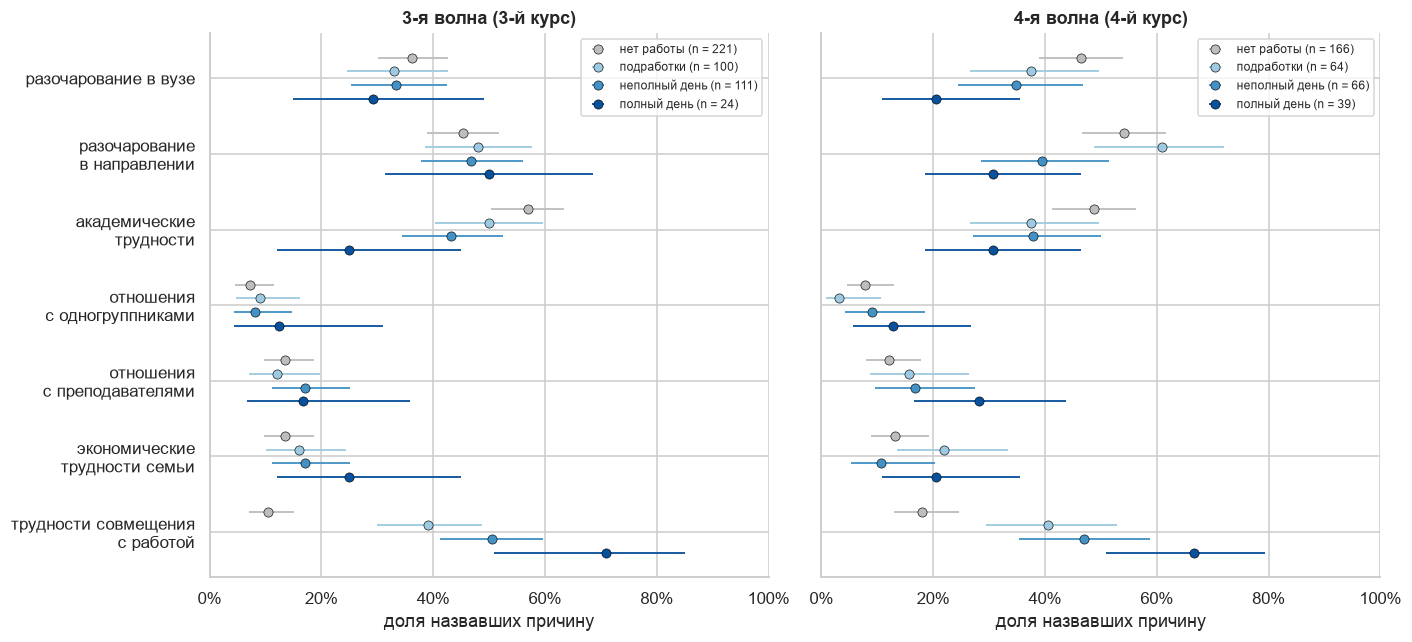

In [4]:
REASONS = {1: 'разочарование в вузе', 2: 'разочарование\nв направлении', 3: 'академические\nтрудности',
           4: 'отношения\nс одногруппниками', 5: 'отношения\nс преподавателями', 6: 'экономические\nтрудности семьи',
           7: 'трудности совмещения\nс работой'}
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
offsets = dict(zip(FORMATS, np.linspace(-0.27, 0.27, 4)))
for ax, w in zip(axes, ['3', '4']):
    base = d[d[f'reasons_cmp_{w}'] & d[f'fmt_{w}'].notna()]
    for fmt in FORMATS:
        group = base[base[f'fmt_{w}'].astype(str) == fmt]
        stats_ = pd.DataFrame([share_ci(group[f'reason{i}_{w}']) for i in REASONS])
        y = np.arange(len(REASONS)) + offsets[fmt]
        ax.errorbar(stats_['доля'], y, xerr=[stats_['доля'] - stats_['от'], stats_['до'] - stats_['доля']],
                    fmt='o', color=FORMAT_COLORS[fmt], ecolor=FORMAT_COLORS[fmt], elinewidth=1.2, capsize=0,
                    markersize=6, markeredgecolor='black', markeredgewidth=0.4, label=f'{fmt} (n = {len(group)})')
    ax.set_yticks(range(len(REASONS)), list(REASONS.values()))
    ax.xaxis.set_major_formatter(percent)
    ax.set(xlim=(0, 1), title=WAVES[w], xlabel='доля назвавших причину')
    ax.legend(loc='upper right', fontsize=8, frameon=True)
axes[0].invert_yaxis()  # оси общие: разворачиваем один раз
plt.tight_layout()
save(fig, 'fig3_dropout_reasons')
plt.show()

Структура причин мыслей об отчислении различается по формату занятости прежде всего в части трудностей совмещения учёбы и работы. Эту причину называют около 70% работающих полный день, около 50% работающих неполный день, около 40% подрабатывающих и 10–18% неработающих; последние, по-видимому, работали ранее, поскольку вопрос охватывает весь период обучения. Учебные причины — академические трудности и разочарование в направлении и вузе — у работающих полный день, напротив, встречаются реже, чем у неработающих. Это позволяет предположить, что у работающих студентов трудности совмещения частично замещают учебные основания мыслей об отчислении. Оценки для группы полного дня опираются на 24 и 39 наблюдений.

## 5. Рисунок 4. Польза и трудности работы по соответствию специальности

**Задачи:** З3.6, Г3.1. Работающие 4-й волны. «Польза» и «трудности» — ответы «скорее» или «полностью согласен» на утверждения о пользе работы для усвоения учебного материала и о трудностях совмещения.

Сохранено: figures/fig4_benefit_difficulty_by_fit.png


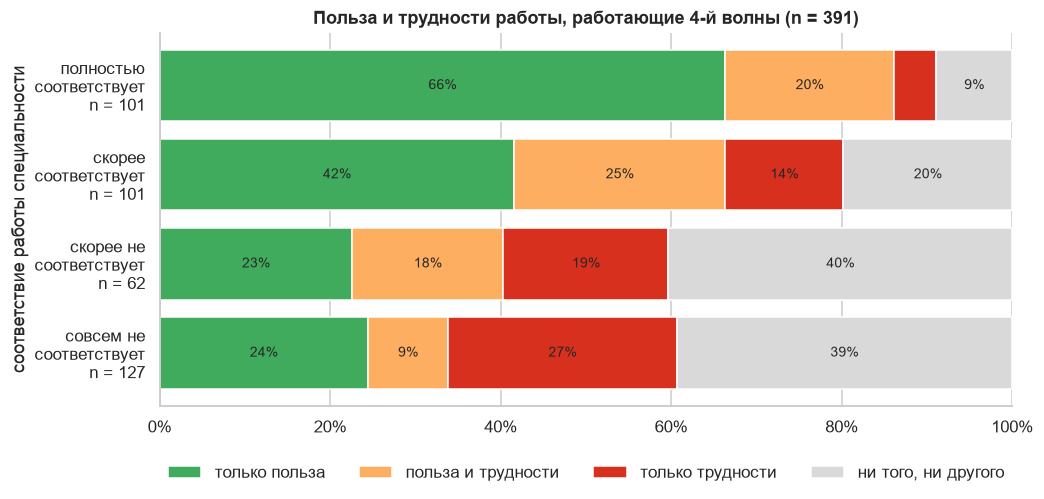

In [5]:
COMBOS = ['только польза', 'польза и трудности', 'только трудности', 'ни того, ни другого']
COMBO_COLORS = dict(zip(COMBOS, ['#41ab5d', '#fdae61', '#d7301f', '#d9d9d9']))
FIT = {1: 'совсем не\nсоответствует', 2: 'скорее не\nсоответствует', 3: 'скорее\nсоответствует', 4: 'полностью\nсоответствует'}
wk = d[d['emp_4'].eq(1) & d['benefit_difficulty_4'].notna() & d['fit_4'].notna()]
table = pd.crosstab(wk['fit_4'], wk['benefit_difficulty_4'], normalize='index').reindex(columns=COMBOS)
n_fit = wk['fit_4'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 4.4))
left = np.zeros(len(table))
for combo in COMBOS:
    ax.barh(range(len(table)), table[combo], left=left, color=COMBO_COLORS[combo], edgecolor='white', label=combo)
    for i, (l, v) in enumerate(zip(left, table[combo])):
        if v > 0.06:
            ax.text(l + v / 2, i, f'{v:.0%}', ha='center', va='center', fontsize=9)
    left += table[combo].to_numpy()
ax.set_yticks(range(len(table)), [f'{FIT[int(k)]}\nn = {n_fit[k]}' for k in table.index])
ax.xaxis.set_major_formatter(percent)
ax.set(xlim=(0, 1), ylabel='соответствие работы специальности',
       title=f'Польза и трудности работы, работающие 4-й волны (n = {len(wk)})')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
save(fig, 'fig4_benefit_difficulty_by_fit')
plt.show()

Сочетание воспринимаемой пользы работы для учёбы и трудностей совмещения закономерно связано с соответствием работы специальности (Г3.1). Доля студентов, отмечающих только пользу, возрастает с 24% среди тех, чья работа совсем не соответствует специальности, до 66% при полном соответствии. Доля отмечающих только трудности за тот же переход снижается с 27% до 5%. Одновременное указание пользы и трудностей встречается на всех уровнях соответствия (9–25%): эти оценки не исключают друг друга. Почти треть работающих (32%) оценила свою работу как совсем не соответствующую специальности.

## 6. Рисунок 5. Подтвердившиеся связи в долях

**Гипотезы Г6.2, Г6.3, Г3.5.** Наблюдаемые доли с 95% ДИ — без поправок, чтобы показать масштаб различий. Сами проверки с поправками — в `analysis.ipynb`.

Сохранено: figures/fig5_confirmed_shares.png


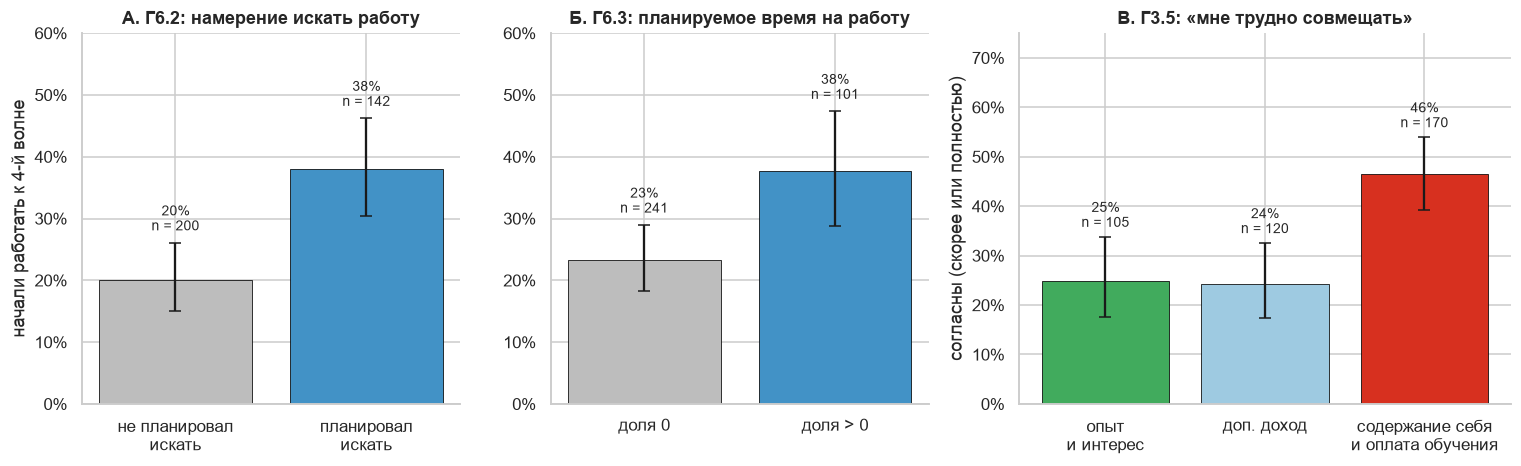

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), gridspec_kw={'width_ratios': [1, 1, 1.3]})
nw = d[d['start_work'].notna()]
panels = [(axes[0], 'intent_3', {0: 'не планировал\nискать', 1: 'планировал\nискать'}, 'А. Г6.2: намерение искать работу'),
          (axes[1], 'plan_work_pos_3', {0: 'доля 0', 1: 'доля > 0'}, 'Б. Г6.3: планируемое время на работу')]
for ax, var, labels, title in panels:
    st = pd.DataFrame({k: share_ci(nw.loc[nw[var].eq(k), 'start_work']) for k in labels}).T
    ax.bar(range(2), st['доля'], color=['#bdbdbd', '#4292c6'], yerr=[st['доля'] - st['от'], st['до'] - st['доля']],
           capsize=4, edgecolor='black', linewidth=0.5)
    for i, r in enumerate(st.itertuples()):
        ax.text(i, r.до + 0.02, f'{r.доля:.0%}\nn = {int(r.n)}', ha='center', fontsize=9)
    ax.set_xticks(range(2), list(labels.values()))
    ax.yaxis.set_major_formatter(percent)
    ax.set(ylim=(0, 0.6), title=title, ylabel='начали работать к 4-й волне' if ax is axes[0] else '')

MOTIVES = ['опыт и интерес', 'доп. доход', 'содержание себя и оплата обучения']
wk = d[d['emp_4'].eq(1) & d['difficulty_4'].notna() & d['motive_g35_4'].notna()]
st = pd.DataFrame({m: share_ci(wk.loc[wk['motive_g35_4'].eq(m), 'difficulty_4'].ge(3).astype(int)) for m in MOTIVES}).T
axes[2].bar(range(3), st['доля'], color=['#41ab5d', '#9ecae1', '#d7301f'], yerr=[st['доля'] - st['от'], st['до'] - st['доля']],
            capsize=4, edgecolor='black', linewidth=0.5)
for i, r in enumerate(st.itertuples()):
    axes[2].text(i, r.до + 0.02, f'{r.доля:.0%}\nn = {int(r.n)}', ha='center', fontsize=9)
axes[2].set_xticks(range(3), ['опыт\nи интерес', 'доп. доход', 'содержание себя\nи оплата обучения'])
axes[2].yaxis.set_major_formatter(percent)
axes[2].set(ylim=(0, 0.75), title='В. Г3.5: «мне трудно совмещать»', ylabel='согласны (скорее или полностью)')
plt.tight_layout()
save(fig, 'fig5_confirmed_shares')
plt.show()

Две подтвердившиеся гипотезы о планах и одна о мотивах трудоустройства:
- среди не работавших на третьем курсе намеревавшиеся искать работу к четвёртому курсу работали почти вдвое чаще (38% против 20%, Г6.2);
- планировавшие уделять время оплачиваемой работе работали чаще указавших нулевую долю (38% против 23%, Г6.3);
- работающие ради содержания себя и оплаты обучения почти вдвое чаще соглашались с тем, что совмещать учёбу и работу трудно (46% против 24–25%, Г3.5).

Приведены наблюдаемые доли; оценки моделей с поправкой на социальные характеристики (`analysis.ipynb`) согласуются с ними по направлению и величине.

## 7. Рисунок 6. Планируемое распределение времени

**Задача:** З6.1, 3-я волна. Слева — доля указавших ноль; справа — распределение положительных долей. Средние доли не показываются: из-за нулей они вводят в заблуждение.

Сохранено: figures/fig6_time_allocation.png


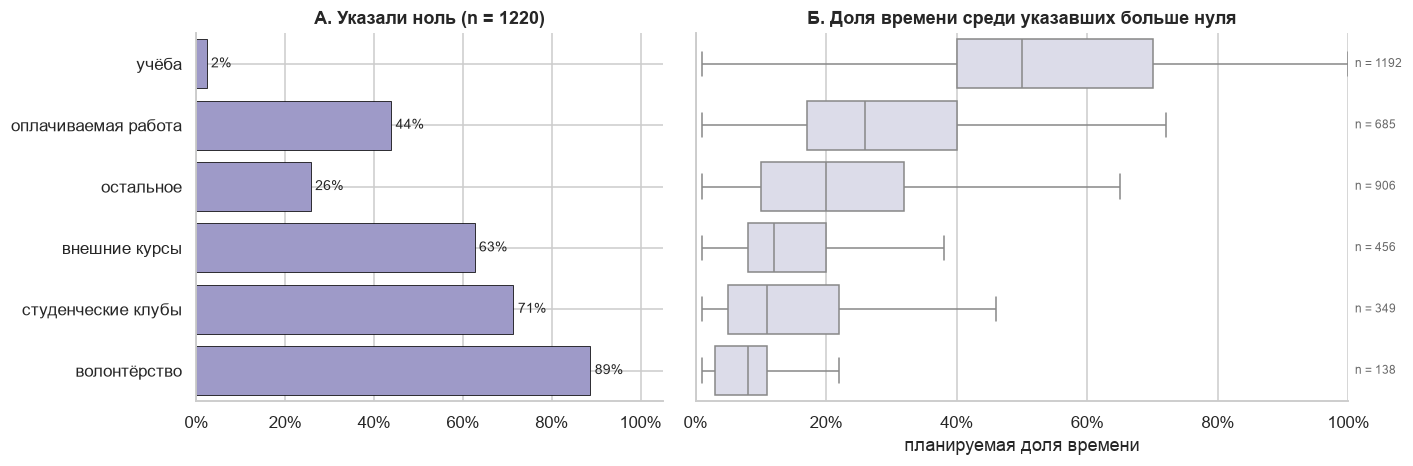

In [7]:
ALLOC = {'alloc_учёба_3': 'учёба', 'alloc_работа_3': 'оплачиваемая работа', 'alloc_остальное_3': 'остальное',
         'alloc_курсы_3': 'внешние курсы', 'alloc_клубы_3': 'студенческие клубы', 'alloc_волонтёрство_3': 'волонтёрство'}
alloc = d.loc[d['hours_3w_1_st'].eq('VALID'), list(ALLOC)].rename(columns=ALLOC)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True, gridspec_kw={'width_ratios': [1, 1.4]})
zeros = (alloc == 0).mean()
ax1.barh(range(len(zeros)), zeros, color='#9e9ac8', edgecolor='black', linewidth=0.5)
for i, v in enumerate(zeros):
    ax1.text(v + 0.01, i, f'{v:.0%}', va='center', fontsize=9)
ax1.set_yticks(range(len(zeros)), zeros.index)
ax1.invert_yaxis()
ax1.xaxis.set_major_formatter(percent)
ax1.set(xlim=(0, 1.05), title=f'А. Указали ноль (n = {len(alloc)})')
positive = alloc.melt(var_name='занятие', value_name='доля').query('доля > 0')
sns.boxplot(data=positive, y='занятие', x='доля', order=list(ALLOC.values()), color='#dadaeb', showfliers=False, ax=ax2)
counts = positive['занятие'].value_counts().reindex(list(ALLOC.values()))
for i, n in enumerate(counts):
    ax2.text(1.01, i, f'n = {n}', va='center', ha='left', fontsize=8, color='dimgray', transform=ax2.get_yaxis_transform())
ax2.xaxis.set_major_formatter(percent)
ax2.set(xlim=(0, 1), ylabel='', xlabel='планируемая доля времени', title='Б. Доля времени среди указавших больше нуля')
plt.tight_layout()
save(fig, 'fig6_time_allocation')
plt.show()

Учебные занятия присутствуют в планах практически всех студентов (нулевую долю указали 2%); в среднем им отводится половина времени. Оплачиваемую работу не планировали 44% студентов, а среди планировавших медианная доля составила около четверти времени. Волонтёрство, студенческие организации и внешние курсы большинство студентов не планировали вовсе (63–89% нулевых долей), а при наличии этих занятий им отводилось около десятой части времени. Из-за большого числа нулевых долей в проверке Г6.3 использован признак наличия положительной доли времени на работу, а не её величина.

## 8. Приложение

### Рисунок П1. Распределения шкал 1–4

Удовлетворённость обучением (обе волны) и оценки работы (работающие 4-й волны). Профили A/B исключены из показателей 4-й волны.

Сохранено: figures/figA1_scales.png


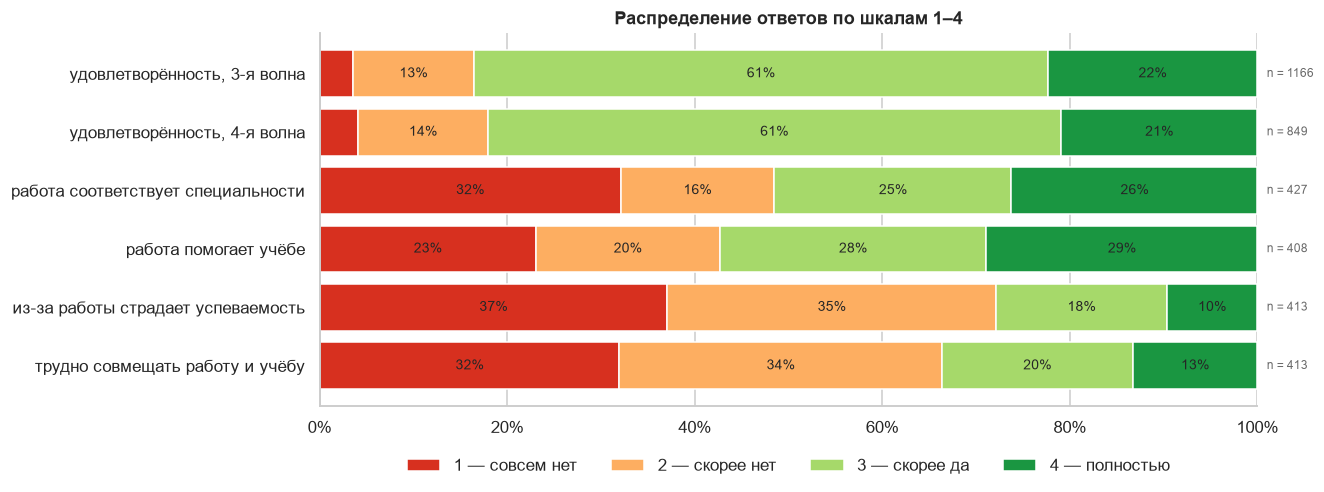

In [8]:
SCALES = {'sat_3': 'удовлетворённость, 3-я волна', 'sat_4': 'удовлетворённость, 4-я волна',
          'fit_4': 'работа соответствует специальности', 'benefit_4': 'работа помогает учёбе',
          'harm_4': 'из-за работы страдает успеваемость', 'difficulty_4': 'трудно совмещать работу и учёбу'}
LEVELS = ['1 — совсем нет', '2 — скорее нет', '3 — скорее да', '4 — полностью']
LEVEL_COLORS = ['#d7301f', '#fdae61', '#a6d96a', '#1a9641']
fig, ax = plt.subplots(figsize=(11, 4.4))
for i, (var, label) in enumerate(SCALES.items()):
    values = d.loc[~d['tech_4w'] if var.endswith('_4') else d.index, var].dropna()
    shares = values.value_counts(normalize=True).reindex([1, 2, 3, 4], fill_value=0)
    left = 0
    for level, color, v in zip(LEVELS, LEVEL_COLORS, shares):
        ax.barh(i, v, left=left, color=color, edgecolor='white', label=level if i == 0 else None)
        if v > 0.06:
            ax.text(left + v / 2, i, f'{v:.0%}', ha='center', va='center', fontsize=9)
        left += v
    ax.text(1.01, i, f'n = {len(values)}', va='center', fontsize=8, color='dimgray', transform=ax.get_yaxis_transform())
ax.set_yticks(range(len(SCALES)), list(SCALES.values()))
ax.invert_yaxis()
ax.xaxis.set_major_formatter(percent)
ax.set(xlim=(0, 1), title='Распределение ответов по шкалам 1–4')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=4, frameon=False)
save(fig, 'figA1_scales')
plt.show()

Удовлетворённость обучением высока и устойчива между волнами: скорее или полностью удовлетворены 84% студентов на третьем курсе и 82% на четвёртом. Соответствие работы специальности распределено поляризованно: 32% работающих выбрали вариант «совсем не соответствует», 26% — «полностью соответствует». Большинство работающих не считает, что работа вредит успеваемости (скорее или полностью согласны 28%) или что её трудно совмещать с учёбой (33%).

### Рисунок П2. Сферы работы: формат и соответствие специальности (4-я волна)

Сферы с числом ответов не меньше 10, по убыванию численности.

Сохранено: figures/figA2_spheres.png


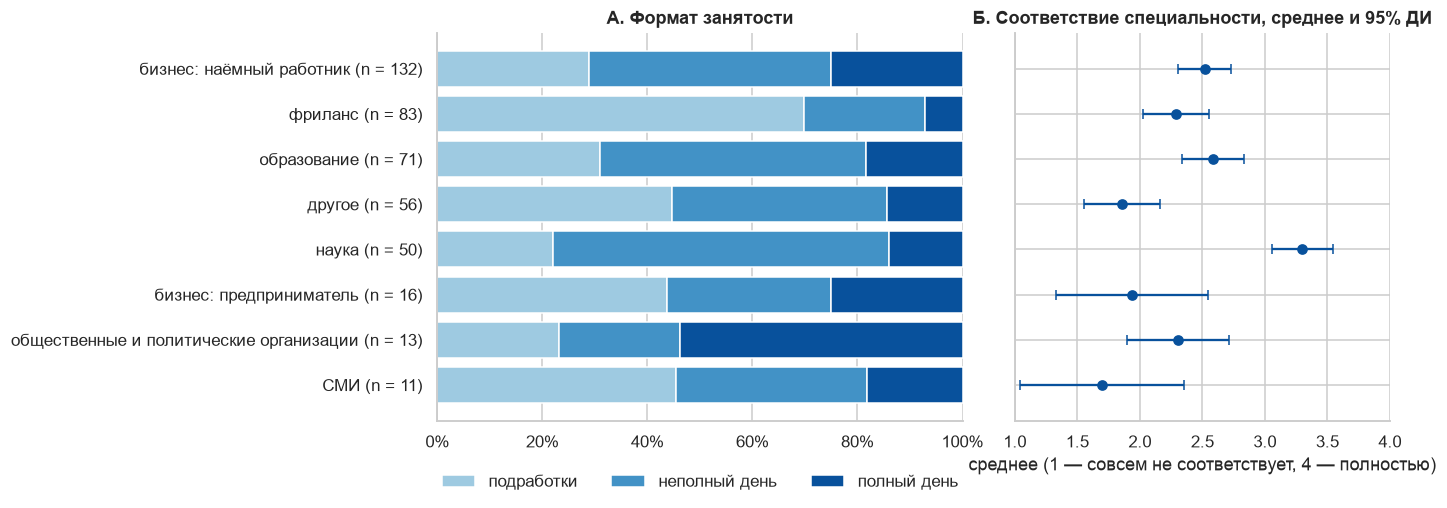

In [9]:
wk = d[d['emp_4'].eq(1) & d['sphere_4'].notna()].assign(sphere=lambda f: f['sphere_4'].astype(str), fmt=lambda f: f['fmt_4'].astype(str))
order = wk['sphere'].value_counts()
order = order[order >= 10].index.tolist()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True, gridspec_kw={'width_ratios': [1.4, 1]})
table = pd.crosstab(wk['sphere'], wk['fmt'], normalize='index').reindex(index=order, columns=FORMATS[1:])
left = np.zeros(len(order))
for fmt in FORMATS[1:]:
    ax1.barh(range(len(order)), table[fmt], left=left, color=FORMAT_COLORS[fmt], edgecolor='white', label=fmt)
    left += table[fmt].to_numpy()
ax1.set_yticks(range(len(order)), [f'{s} (n = {(wk["sphere"] == s).sum()})' for s in order])
ax1.invert_yaxis()
ax1.xaxis.set_major_formatter(percent)
ax1.set(xlim=(0, 1), title='А. Формат занятости')
ax1.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
fit = wk.groupby('sphere')['fit_4'].agg(['mean', 'sem']).reindex(order)
ax2.errorbar(fit['mean'], range(len(order)), xerr=1.96 * fit['sem'], fmt='o', color='#08519c', capsize=3)
ax2.set(xlim=(1, 4), xlabel='среднее (1 — совсем не соответствует, 4 — полностью)',
        title='Б. Соответствие специальности, среднее и 95% ДИ')
plt.tight_layout()
save(fig, 'figA2_spheres')
plt.show()

Сферы занятости различаются по формату работы и соответствию специальности. Во фрилансе преобладают подработки (70%), в науке и образовании — неполный рабочий день. Соответствие работы специальности наиболее высоко в науке (3,3 балла из 4) и наиболее низко в СМИ, предпринимательстве и сферах, отнесённых студентами к «другому» (1,7–1,9). Для сфер с числом наблюдений менее 20 доверительные интервалы широки, и их сравнение носит ориентировочный характер.

In [10]:
HOURS_LABELS = ['до 10 ч', '11–20 ч', '21–30 ч', 'больше 30 ч']
SCALE4 = {1: '1 — совсем нет', 2: '2 — скорее нет', 3: '3 — скорее да', 4: '4 — полностью'}
MARKS = {1: 'в основном «3»', 2: 'в основном «4»', 3: '«4» и «5»', 4: 'только «5»'}
SAT = {1: 'совсем не удовлетворён', 2: 'скорее не удовлетворён', 3: 'скорее удовлетворён', 4: 'полностью удовлетворён'}
PE_FREQ = {1: 'раз в месяц или реже', 2: 'несколько раз в месяц', 3: '1–2 раза в неделю', 4: '3–4 раза в неделю',
           5: 'каждый день'}
EDU3 = ['тот же вуз, та же специальность', 'тот же вуз, другая специальность', 'другой вуз, та же специальность',
        'другой вуз, другая специальность', 'не поступал бы']
RED_GREEN = {4: ['#d7301f', '#fdae61', '#a6d96a', '#1a9641'], 5: ['#d7301f', '#fdae61', '#ffffbf', '#a6d96a', '#1a9641']}
EDU_COLORS = ['#1a9641', '#a6d96a', '#fdae61', '#d7301f', '#7f0000']
AGREE = ['#eff3ff', '#bdd7e7', '#6baed6', '#2171b5']  # шкалы согласия 1–4: светлее — меньше согласие
SES = {'1–3': '1–3: не хватало\nна повседневное', '4': '4', '5': '5', '6': '6: могли позволить\nдорогое'}
FUNDING = ['бюджет', 'платное', 'целевое']
MOTIVES = ['содержать себя', 'доп. доход', 'опыт', 'интерес', 'оплата обучения', 'другое']
MOTIVE_G35 = ['опыт и интерес', 'доп. доход', 'содержание себя и оплата обучения']
GREY_BLUE = ['#bdbdbd', '#4292c6']


def hours_bin(s):
    return pd.cut(s, [-0.1, 10, 20, 30, 200], labels=HOURS_LABELS)


def bars(ax, frame, group, outcome, groups, colors=None, value=1, title='', ylabel='', ymax=None):
    """Доли outcome == value по группам: столбцы с 95% ДИ, подписи — доля и n."""
    groups = groups if isinstance(groups, dict) else {g: g for g in groups}
    st = pd.DataFrame({label: share_ci(frame.loc[frame[group] == g, outcome], value) for g, label in groups.items()}).T
    colors = colors or ['#4292c6'] * len(st)
    ax.bar(range(len(st)), st['доля'], color=colors, edgecolor='black', linewidth=0.5,
           yerr=[st['доля'] - st['от'], st['до'] - st['доля']], capsize=3)
    for i, r in enumerate(st.itertuples()):
        if r.n:
            ax.text(i, r.до + 0.015, f'{r.доля:.0%}\nn = {int(r.n)}', ha='center', va='bottom', fontsize=8)
    ax.set_xticks(range(len(st)), st.index)
    ax.yaxis.set_major_formatter(percent)
    ax.set(ylim=(0, ymax or min(1, st['до'].max() + 0.2)), title=title, ylabel=ylabel)
    return st[['доля', 'от', 'до', 'n']]


def stacked(ax, frame, group, outcome, groups, levels, colors, title='', legend=True):
    """Распределение outcome внутри каждой группы: горизонтальные столбцы 100%."""
    groups = groups if isinstance(groups, dict) else {g: g for g in groups}
    levels = levels if isinstance(levels, dict) else {l: l for l in levels}
    rows, ns = {}, {}
    for g, label in groups.items():
        values = frame.loc[frame[group] == g, outcome].dropna()
        rows[label] = values.value_counts(normalize=True).reindex(list(levels), fill_value=0)
        ns[label] = len(values)
    table = pd.DataFrame(rows).T
    y = -np.arange(len(table))  # первая группа сверху (без invert_yaxis: оси бывают общими)
    left = np.zeros(len(table))
    for (level, level_label), color in zip(levels.items(), colors):
        ax.barh(y, table[level], left=left, color=color, edgecolor='white', label=level_label)
        for yi, l, v in zip(y, left, table[level]):
            if v >= 0.07:
                dark = color in ('#2171b5', '#08519c', '#7f0000', '#737373')
                ax.text(l + v / 2, yi, f'{v:.0%}', ha='center', va='center', fontsize=8, color='white' if dark else 'black')
        left += table[level].to_numpy()
    ax.set_yticks(y, [f'{g}\n(n = {ns[g]})' for g in table.index])
    ax.xaxis.set_major_formatter(percent)
    ax.set(xlim=(0, 1), title=title)
    if legend:
        ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=min(len(levels), 5), frameon=False, fontsize=8)
    table.columns = list(levels.values())
    return table.assign(n=pd.Series(ns)).round(3)


def boxes(ax, frame, group, value, groups, title='', ylabel='', color='#9ecae1'):
    """Распределение value по группам: «ящики» без выбросов и точки ответов."""
    groups = groups if isinstance(groups, dict) else {g: g for g in groups}
    data = [frame.loc[frame[group] == g, value].dropna() for g in groups]
    ax.boxplot(data, tick_labels=[f'{label}\nn = {len(s)}' for label, s in zip(groups.values(), data)], showfliers=False,
               widths=0.5, patch_artist=True, boxprops={'facecolor': color}, medianprops={'color': 'black'})
    for i, s in enumerate(data, start=1):
        ax.scatter(i + rng.uniform(-0.18, 0.18, len(s)), s, s=4, color='black', alpha=0.2)
    ax.set(title=title, ylabel=ylabel)
    return pd.DataFrame({label: s.describe()[['count', '25%', '50%', '75%']] for label, s in zip(groups.values(), data)}).T.round(2)


def two_waves(plot, figsize=(13, 4.4), sharey=True, **kwargs):
    """Один и тот же рисунок для 3-й и 4-й волны; plot(ax, w) возвращает таблицу."""
    fig, axes = plt.subplots(1, 2, figsize=figsize, sharey=sharey)
    tables = {}
    for ax, w in zip(axes, ['3', '4']):
        tables[WAVES[w]] = plot(ax, w)
        ax.set_title(f'{WAVES[w]}' + (f': {ax.get_title()}' if ax.get_title() else ''))
    plt.tight_layout()
    return fig, pd.concat(tables)


def wave_values(var, w):
    """Значения переменной волны w; профили A/B исключаются только из показателей 4-й волны."""
    rows = ~d['tech_4w'] if w == '4' else d['in_w3']
    return d.loc[rows, f'{var}_{w}']


def show_tables(tables):
    """Таблицы под рисунком: каждая группа отдельно (у групп разные столбцы)."""
    groups = {}
    for key, table in tables.items():
        name, sub = key if isinstance(key, tuple) else (key, None)
        groups.setdefault(name, {})[sub] = table
    for name, parts in groups.items():
        print(name)
        display(parts[None] if None in parts else pd.concat(parts))


rng = np.random.default_rng(2026)
workers = {w: d[d[f'emp_{w}'].eq(1)].assign(hbin=lambda f, w=w: hours_bin(f[f'hours_{w}'])) for w in ['3', '4']}
in_wave = {w: d[d[f'in_w{w}']] for w in ['3', '4']}

## 9. Рисунки по гипотезам

К каждой гипотезе и задаче — наблюдаемые данные без поправок: то, что стоит за моделью в `analysis.ipynb`. Решение по гипотезе указано перед рисунком. Под рисунком — таблица показанных чисел.

### ИВ1. Структура и социальные различия занятости

#### З1.1. Мотивы и сферы работы

Доли среди работающих (структура форматов и часы — рисунки 1 и 2).

Сохранено: figures/H_Z1.1_motives_spheres.png


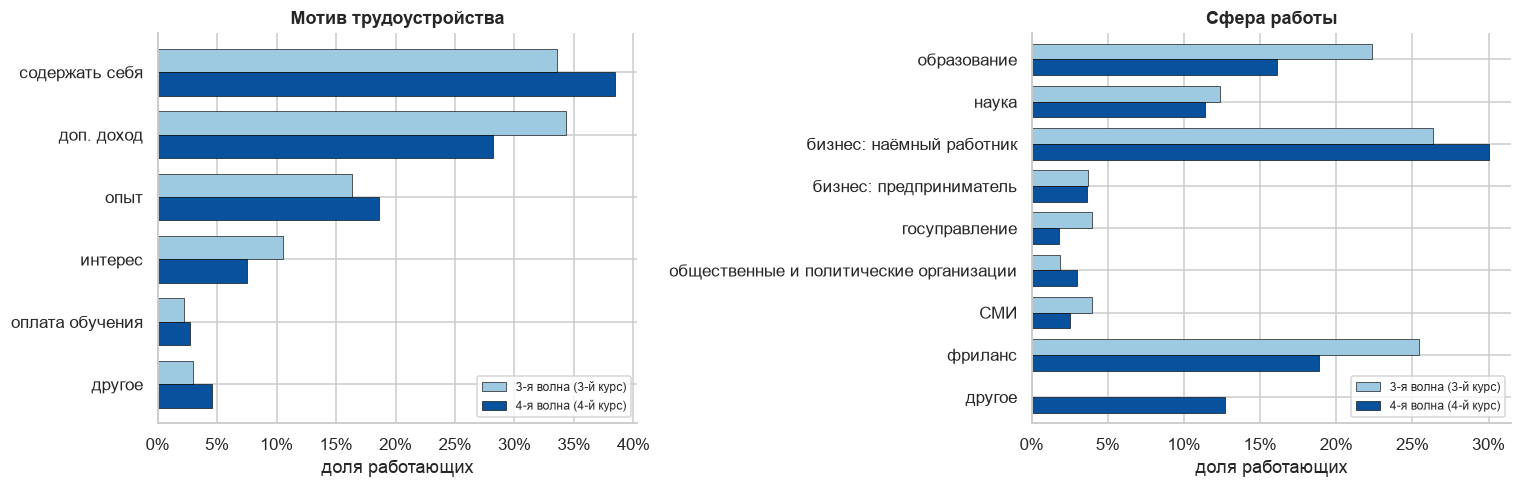

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, var, cats, title in [(axes[0], 'motive_raw', MOTIVES, 'Мотив трудоустройства'),
                             (axes[1], 'sphere', list(d['sphere_4'].cat.categories), 'Сфера работы')]:
    table = pd.DataFrame({WAVES[w]: workers[w][f'{var}_{w}'].astype(object).value_counts(normalize=True).reindex(cats, fill_value=0)
                          for w in ['3', '4']})
    table.plot.barh(ax=ax, color=['#9ecae1', '#08519c'], edgecolor='black', linewidth=0.4, width=0.75)
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(percent)
    ax.set(title=title, xlabel='доля работающих')
    ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
save(fig, 'H_Z1.1_motives_spheres')
plt.show()

Ведущими мотивами трудоустройства в обеих волнах были содержание себя (34% и 38% работающих) и дополнительный доход (34% и 28%); к четвёртому курсу несколько возросли доли работающих ради содержания себя и ради опыта. Оплату обучения в качестве мотива назвали 2–3% работающих. Наиболее распространёнными сферами занятости были наёмная работа в бизнесе, фриланс и образование. Категория «другое» в вопросе о сфере появляется только в четвёртой волне (13%), где анкета предусматривала открытый вариант ответа.

#### Г1.2. Платное обучение и наличие работы

*Не подтверждается:* OR = 1,00 и 0,93.

Сохранено: figures/H_G1.2_work_by_funding.png


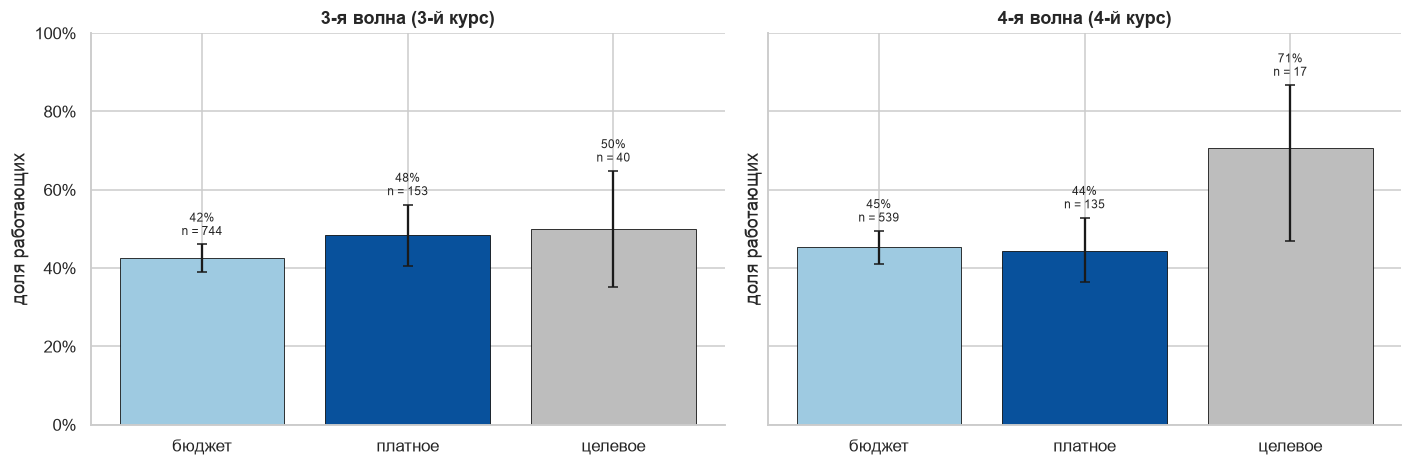

доля        от        до      n
3-я волна (3-й курс) бюджет   0.424731  0.389689  0.460547  744.0
                     платное  0.483660  0.405851  0.562270  153.0
                     целевое  0.500000  0.351995  0.648005   40.0
4-я волна (4-й курс) бюджет   0.452690  0.411151  0.494899  539.0
                     платное  0.444444  0.363314  0.528649  135.0
                     целевое  0.705882  0.468669  0.867200   17.0

In [12]:
fig, table = two_waves(lambda ax, w: bars(ax, in_wave[w], 'funding_c', f'emp_{w}', FUNDING,
                                         colors=['#9ecae1', '#08519c', '#bdbdbd'], ylabel='доля работающих', ymax=1))
save(fig, 'H_G1.2_work_by_funding')
plt.show()
table

Доли работающих среди студентов бюджетной и платной форм обучения практически совпадают: 42% и 48% на третьем курсе, 45% и 44% на четвёртом; доверительные интервалы перекрываются. Это согласуется с результатом модели, не подтвердившей Г1.2. Среди обучающихся по целевой квоте доля работающих выше (50% и 71%), однако оценки опираются на 40 и 17 наблюдений и не допускают содержательной интерпретации.

#### Г1.3. Материальное положение семьи и наличие работы

*Не подтверждается:* OR = 0,99 и 1,07 на ступень шкалы.

Сохранено: figures/H_G1.3_work_by_ses.png


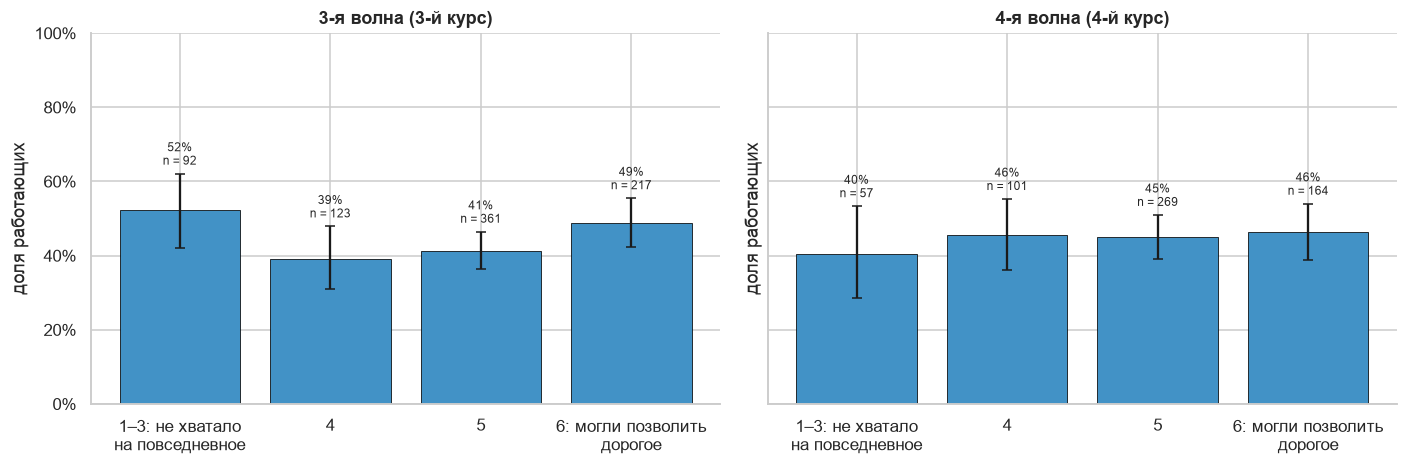

доля        от  \
3-я волна (3-й курс) 1–3: не хватало\nна повседневное  0.521739  0.420857   
                     4                                 0.390244  0.308611   
                     5                                 0.412742  0.363134   
                     6: могли позволить\nдорогое       0.488479  0.422752   
4-я волна (4-й курс) 1–3: не хватало\nна повседневное  0.403509  0.286175   
                     4                                 0.455446  0.361736   
                     5                                 0.449814  0.391488   
                     6: могли позволить\nдорогое       0.463415  0.388807   

                                                             до      n  
3-я волна (3-й курс) 1–3: не хватало\nна повседневное  0.620879   92.0  
                     4                                 0.478524  123.0  
                     5                                 0.464188  361.0  
                     6: могли позволить\nдорогое       0.554607  217.0  
4-я волна (4-й курс) 1–3: не хватало\nна повседневное  0.533027   57.0  
                     4                                 0.552420  101.0  
                     5                                 0.509554  269.0  
                     6: могли позволить\nдорогое       0.539697  164.0

In [13]:
fig, table = two_waves(lambda ax, w: bars(ax, in_wave[w], 'ses4', f'emp_{w}', SES, ylabel='доля работающих', ymax=1))
save(fig, 'H_G1.3_work_by_ses')
plt.show()
table

Последовательной связи между материальным положением семьи и наличием работы не обнаружено: доля работающих колеблется в диапазоне 39–52% без монотонного направления. В наименее обеспеченной группе доля работающих на третьем курсе выше средней (52%), на четвёртом — ниже (40%); эта группа малочисленна (92 и 57 наблюдений). Г1.3 не подтверждается.

#### Г1.4. Материальное положение и мотив трудоустройства

*Не подтверждается:* OR = 0,89 и 0,92.

Сохранено: figures/H_G1.4_motive_by_ses.png


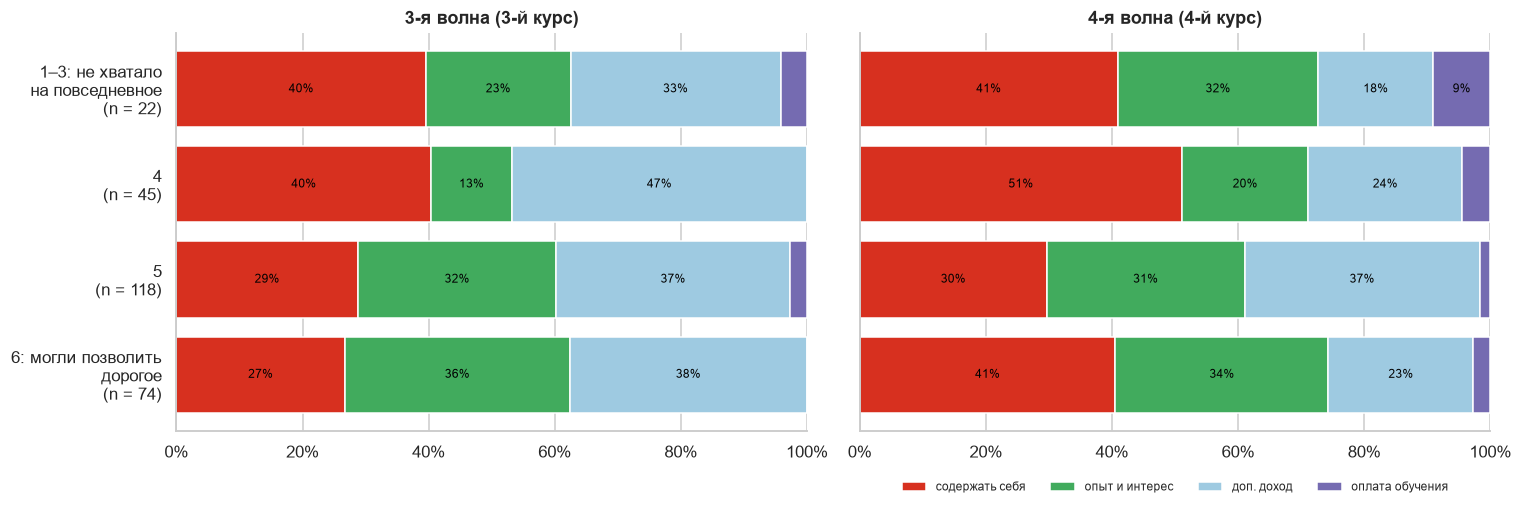

содержать себя  \
3-я волна (3-й курс) 1–3: не хватало\nна повседневное           0.396   
                     4                                          0.404   
                     5                                          0.288   
                     6: могли позволить\nдорогое                0.267   
4-я волна (4-й курс) 1–3: не хватало\nна повседневное           0.409   
                     4                                          0.511   
                     5                                          0.297   
                     6: могли позволить\nдорогое                0.405   

                                                       опыт и интерес  \
3-я волна (3-й курс) 1–3: не хватало\nна повседневное           0.229   
                     4                                          0.128   
                     5                                          0.315   
                     6: могли позволить\nдорогое                0.356   
4-я волна (4-й курс) 1–3: не хватало\nна повседневное           0.318   
                     4                                          0.200   
                     5                                          0.314   
                     6: могли позволить\nдорогое                0.338   

                                                       доп. доход  \
3-я волна (3-й курс) 1–3: не хватало\nна повседневное       0.333   
                     4                                      0.468   
                     5                                      0.370   
                     6: могли позволить\nдорогое            0.376   
4-я волна (4-й курс) 1–3: не хватало\nна повседневное       0.182   
                     4                                      0.244   
                     5                                      0.373   
                     6: могли позволить\nдорогое            0.230   

                                                       оплата обучения    n  
3-я волна (3-й курс) 1–3: не хватало\nна повседневное            0.042   48  
                     4                                           0.000   47  
                     5                                           0.027  146  
                     6: могли позволить\nдорогое                 0.000  101  
4-я волна (4-й курс) 1–3: не хватало\nна повседневное            0.091   22  
                     4                                           0.044   45  
                     5                                           0.017  118  
                     6: могли позволить\nдорогое                 0.027   74

In [14]:
G14 = ['содержать себя', 'опыт и интерес', 'доп. доход', 'оплата обучения']
fig, table = two_waves(lambda ax, w: stacked(ax, workers[w], 'ses4', f'motive_g14_{w}', SES, G14,
                                            ['#d7301f', '#41ab5d', '#9ecae1', '#756bb1'], legend=(w == '4')),
                       figsize=(14, 4.8))
save(fig, 'H_G1.4_motive_by_ses')
plt.show()
table

На третьем курсе студенты из менее обеспеченных семей несколько чаще называли мотивом содержание себя: 40% в группах 1–3 и 4 против 27–29% в группах 5–6. На четвёртом курсе этот градиент не воспроизводится (41%, 51%, 30% и 41% соответственно). Отсутствие согласованной картины между волнами объясняет незначимость эффекта в модели (Г1.4 не подтверждается).

#### З1.5. Мотив «оплата обучения» и финансирование

Сохранено: figures/H_Z1.5_tuition_by_funding.png


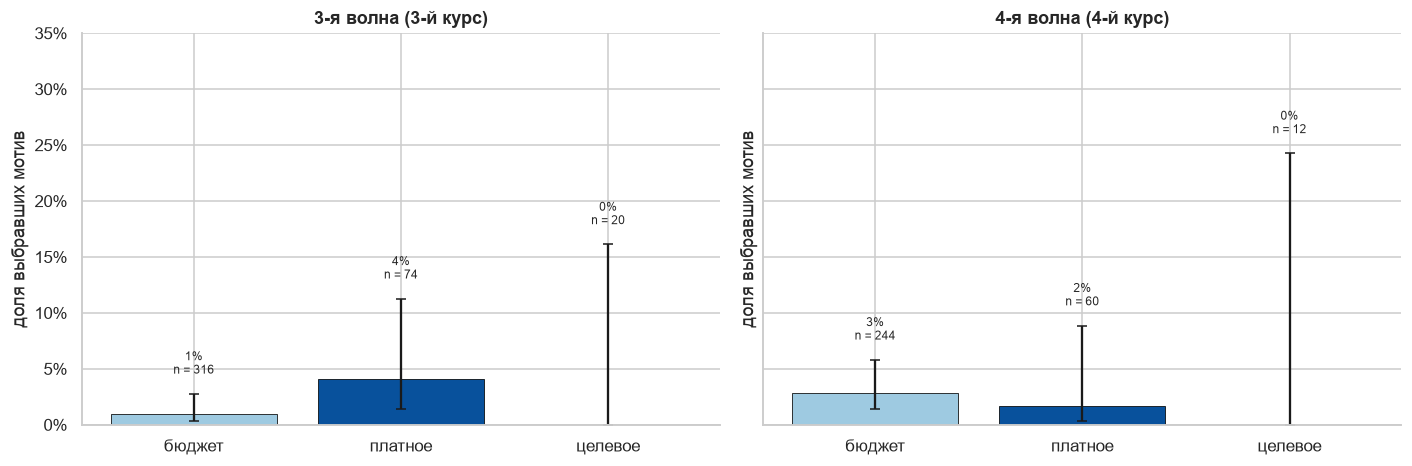

доля        от        до      n
3-я волна (3-й курс) бюджет   0.009494  0.003234  0.027536  316.0
                     платное  0.040541  0.013882  0.112547   74.0
                     целевое  0.000000  0.000000  0.161125   20.0
4-я волна (4-й курс) бюджет   0.028689  0.013965  0.058023  244.0
                     платное  0.016667  0.002948  0.088551   60.0
                     целевое  0.000000  0.000000  0.242494   12.0

In [15]:
fig, table = two_waves(lambda ax, w: bars(ax, workers[w], 'funding_c', f'pay_tuition_{w}', FUNDING,
                                         colors=['#9ecae1', '#08519c', '#bdbdbd'], ylabel='доля выбравших мотив', ymax=0.35))
save(fig, 'H_Z1.5_tuition_by_funding')
plt.show()
table

Мотив оплаты обучения встречается редко во всех группах финансирования (1–4% работающих). Даже среди студентов платной формы его указали 4% на третьем курсе (3 человека) и 2% на четвёртом (1 человек). Работа студентов платной формы, таким образом, лишь в единичных случаях направлена на оплату обучения; статистическое сравнение групп при такой частоте неинформативно.

#### З1.6. Сферы работы: формат и часы (3-я и 4-я волна)

Сферы с числом ответов не меньше 10. Соответствие специальности (4-я волна) — рисунок П2.

Сохранено: figures/H_Z1.6_hours_by_sphere.png


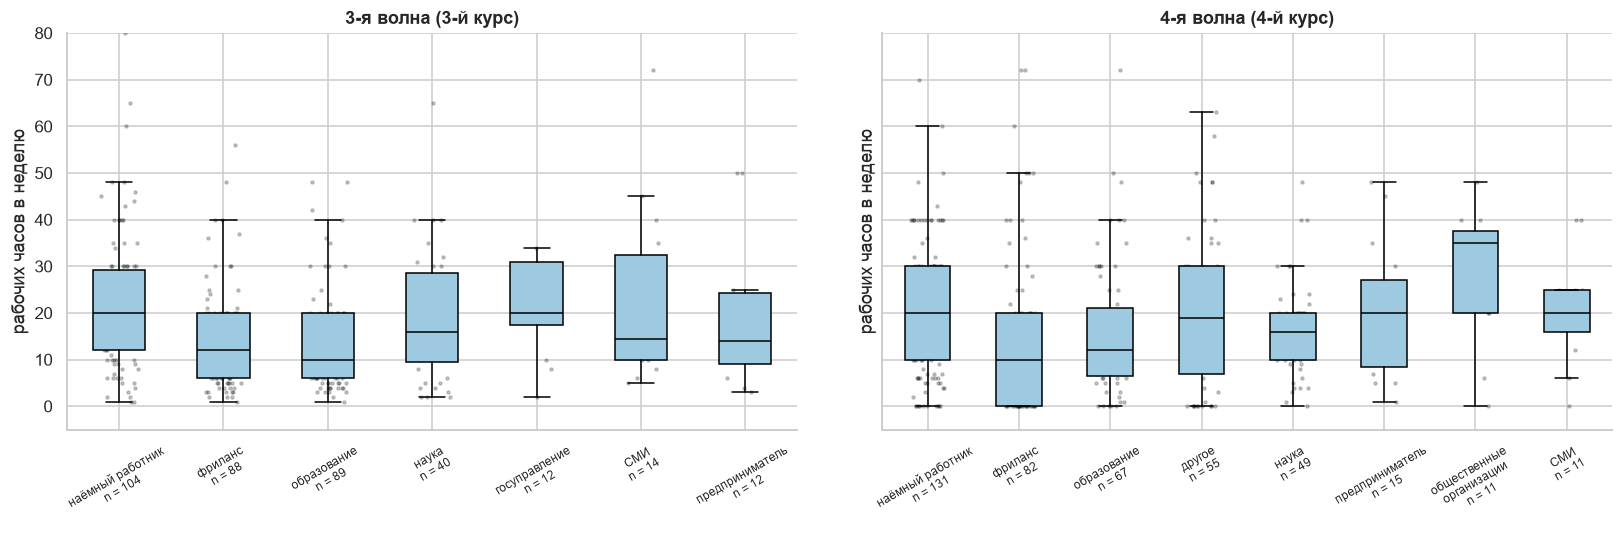

count   25%   50%    75%
3-я волна (3-й курс) наёмный работник           104.0  12.0  20.0  29.25
                     фриланс                     88.0   6.0  12.0  20.00
                     образование                 89.0   6.0  10.0  20.00
                     наука                       40.0   9.5  16.0  28.50
                     госуправление               12.0  17.5  20.0  31.00
                     СМИ                         14.0  10.0  14.5  32.50
                     предприниматель             12.0   9.0  14.0  24.25
4-я волна (4-й курс) наёмный работник           131.0  10.0  20.0  30.00
                     фриланс                     82.0   0.0  10.0  20.00
                     образование                 67.0   6.5  12.0  21.00
                     другое                      55.0   7.0  19.0  30.00
                     наука                       49.0  10.0  16.0  20.00
                     предприниматель             15.0   8.5  20.0  27.00
                     общественные\nорганизации   11.0  20.0  35.0  37.50
                     СМИ                         11.0  16.0  20.0  25.00

In [16]:
def sphere_plot(ax, w):
    wk = workers[w].assign(s=lambda f: f[f'sphere_{w}'].astype(object))
    order = wk['s'].value_counts()
    order = order[order >= 10].index.tolist()
    return boxes(ax, wk, 's', f'hours_{w}', {s: s.replace('бизнес: ', '').replace(' и политические организации', '\nорганизации') for s in order},
                 ylabel='рабочих часов в неделю')

fig, table = two_waves(sphere_plot, figsize=(15, 4.8))
for ax in fig.axes:
    ax.set_ylim(-5, 80)
    ax.tick_params(axis='x', labelrotation=30, labelsize=8)
save(fig, 'H_Z1.6_hours_by_sphere')
plt.show()
table

Сферы различаются по интенсивности занятости. Наибольшая медианная нагрузка отмечается у наёмных работников в бизнесе (20 часов) и в общественных организациях (35 часов в четвёртой волне), наименьшая — во фрилансе и образовании (10–12 часов). Во фрилансе четвёртой волны четверть работающих указала нулевые часы за прошлую неделю, что отражает нерегулярность этого вида занятости.

### ИВ2. Занятость и обучение

#### Г2.1. Рабочие часы и категория оценок

*Не подтверждается:* OR = 1,05 и 0,97 на 10 часов.

Сохранено: figures/H_G2.1_marks_by_hours.png


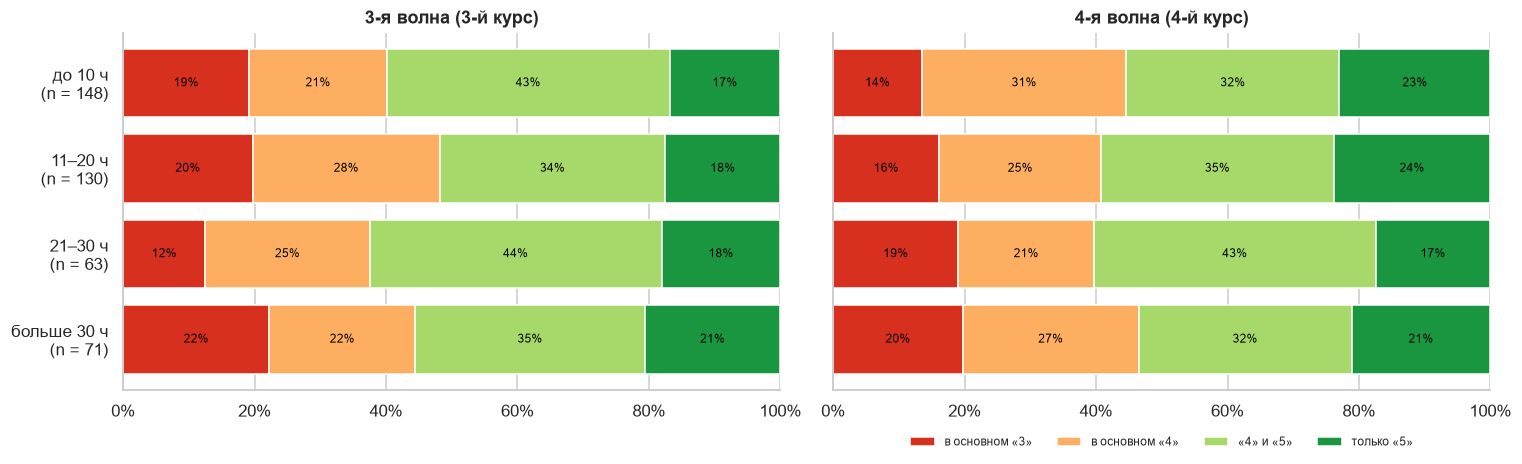

в основном «3»  в основном «4»  «4» и «5»  \
3-я волна (3-й курс) до 10 ч               0.192           0.209      0.430   
                     11–20 ч               0.197           0.285      0.343   
                     21–30 ч               0.125           0.250      0.444   
                     больше 30 ч           0.222           0.222      0.349   
4-я волна (4-й курс) до 10 ч               0.135           0.311      0.324   
                     11–20 ч               0.162           0.246      0.354   
                     21–30 ч               0.190           0.206      0.429   
                     больше 30 ч           0.197           0.268      0.324   

                                  только «5»    n  
3-я волна (3-й курс) до 10 ч           0.169  172  
                     11–20 ч           0.175  137  
                     21–30 ч           0.181   72  
                     больше 30 ч       0.206   63  
4-я волна (4-й курс) до 10 ч           0.230  148  
                     11–20 ч           0.238  130  
                     21–30 ч           0.175   63  
                     больше 30 ч       0.211   71

In [17]:
fig, table = two_waves(lambda ax, w: stacked(ax, workers[w], 'hbin', f'mark_{w}', HOURS_LABELS, MARKS, RED_GREEN[4],
                                            legend=(w == '4')), figsize=(14, 4.4))
save(fig, 'H_G2.1_marks_by_hours')
plt.show()
table

Распределение категорий оценок практически одинаково во всех группах по рабочим часам: доля получающих в основном удовлетворительные оценки составляет 12–22%, только отличные — 17–24%. Монотонного снижения успеваемости с ростом нагрузки не наблюдается, что согласуется с отрицательным результатом проверки Г2.1.

#### Г2.2. Рабочие часы и удовлетворённость обучением

*Не подтверждается:* OR = 0,93 и 0,98.

Сохранено: figures/H_G2.2_satisfaction_by_hours.png


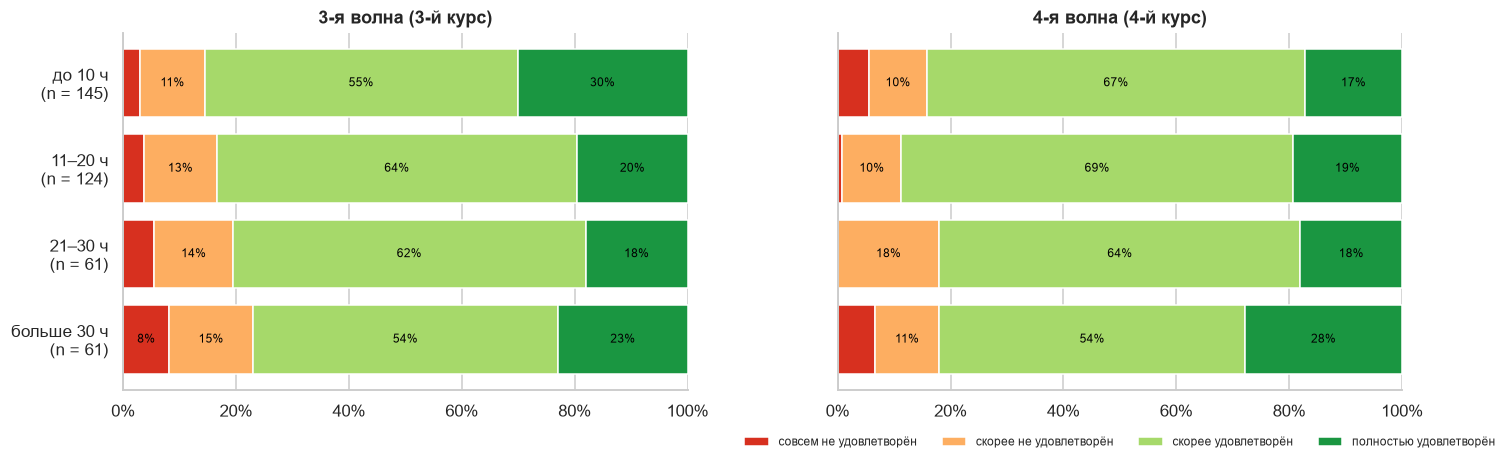

совсем не удовлетворён  \
3-я волна (3-й курс) до 10 ч                       0.030   
                     11–20 ч                       0.038   
                     21–30 ч                       0.056   
                     больше 30 ч                   0.082   
4-я волна (4-й курс) до 10 ч                       0.055   
                     11–20 ч                       0.008   
                     21–30 ч                       0.000   
                     больше 30 ч                   0.066   

                                  скорее не удовлетворён  скорее удовлетворён  \
3-я волна (3-й курс) до 10 ч                       0.114                0.554   
                     11–20 ч                       0.128                0.639   
                     21–30 ч                       0.139                0.625   
                     больше 30 ч                   0.148                0.541   
4-я волна (4-й курс) до 10 ч                       0.103                0.669   
                     11–20 ч                       0.105                0.694   
                     21–30 ч                       0.180                0.639   
                     больше 30 ч                   0.115                0.541   

                                  полностью удовлетворён    n  
3-я волна (3-й курс) до 10 ч                       0.301  166  
                     11–20 ч                       0.195  133  
                     21–30 ч                       0.181   72  
                     больше 30 ч                   0.230   61  
4-я волна (4-й курс) до 10 ч                       0.172  145  
                     11–20 ч                       0.194  124  
                     21–30 ч                       0.180   61  
                     больше 30 ч                   0.279   61

In [18]:
fig, table = two_waves(lambda ax, w: stacked(ax, workers[w], 'hbin', f'sat_{w}', HOURS_LABELS, SAT, RED_GREEN[4],
                                            legend=(w == '4')), figsize=(14, 4.4))
save(fig, 'H_G2.2_satisfaction_by_hours')
plt.show()
table

На третьем курсе доля неудовлетворённых обучением несколько выше при большой нагрузке: 14% среди работающих до 10 часов и 23% среди работающих более 30 часов. На четвёртом курсе эта тенденция отсутствует. Модель с поправкой на социальные характеристики связи не подтверждает (Г2.2).

#### Г2.3. Формат занятости и мысли об отчислении

*Не подтверждается по правилу решения:* OR(полный день) = 1,81 и 1,77, p по Холму 0,22 и 0,10; направление ожидаемое.

Сохранено: figures/H_G2.3_dropout_by_format.png


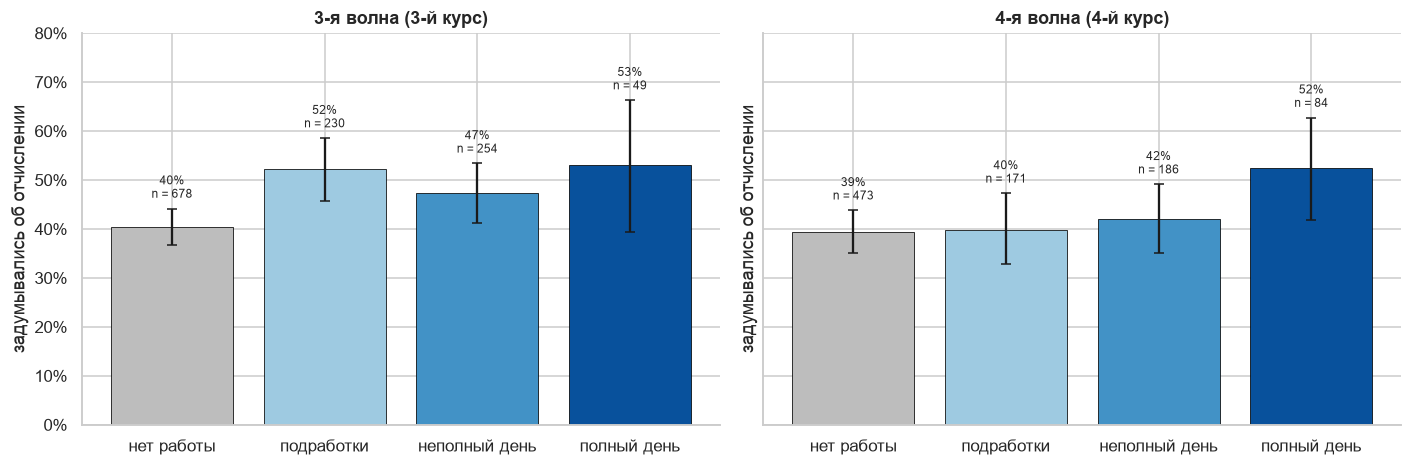

доля        от        до      n
3-я волна (3-й курс) нет работы     0.404130  0.367832  0.441507  678.0
                     подработки     0.521739  0.457356  0.585408  230.0
                     неполный день  0.472441  0.411913  0.533790  254.0
                     полный день    0.530612  0.393809  0.662965   49.0
4-я волна (4-й курс) нет работы     0.393235  0.350244  0.437946  473.0
                     подработки     0.397661  0.327330  0.472488  171.0
                     неполный день  0.419355  0.350774  0.491199  186.0
                     полный день    0.523810  0.418321  0.627216   84.0

In [19]:
fig, table = two_waves(lambda ax, w: bars(ax, in_wave[w], f'fmt_{w}', f'drop_any_{w}', FORMATS,
                                         colors=[FORMAT_COLORS[f] for f in FORMATS], ylabel='задумывались об отчислении',
                                         ymax=0.8))
save(fig, 'H_G2.3_dropout_by_format')
plt.show()
table

Работающие полный день чаще других сообщали о мыслях об отчислении: 53% и 52% против 40% и 39% среди неработающих. Направление различия соответствует Г2.3, однако малочисленность группы полного дня (49 и 84 человека) обусловливает широкие доверительные интервалы, и после поправки на множественность различие не достигает значимости. На третьем курсе подрабатывающие студенты задумывались об отчислении так же часто, как работающие полный день (52%), на четвёртом — нет (40%).

#### Г2.4. Рабочие часы и причина «трудности совмещения»

*Не подтверждается по правилу решения:* OR = 1,18 и 1,24 на 10 часов, p по Холму 0,077; без сомнительных значений часов — значимо.

Сохранено: figures/H_G2.4_reason7_by_hours.png


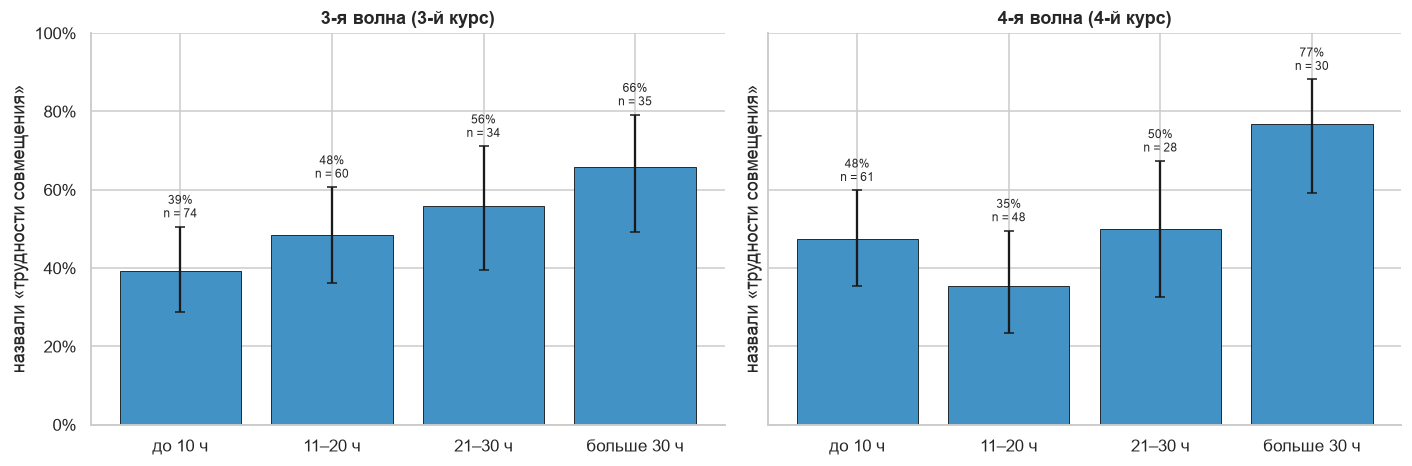

доля        от        до     n
3-я волна (3-й курс) до 10 ч      0.391892  0.288649  0.505805  74.0
                     11–20 ч      0.483333  0.361750  0.606922  60.0
                     21–30 ч      0.558824  0.394539  0.711165  34.0
                     больше 30 ч  0.657143  0.491519  0.791683  35.0
4-я волна (4-й курс) до 10 ч      0.475410  0.355305  0.598428  61.0
                     11–20 ч      0.354167  0.234336  0.495609  48.0
                     21–30 ч      0.500000  0.326331  0.673669  28.0
                     больше 30 ч  0.766667  0.590717  0.882076  30.0

In [20]:
fig, table = two_waves(lambda ax, w: bars(ax, workers[w][workers[w][f'drop_any_{w}'].eq(1) & workers[w][f'reasons_cmp_{w}']],
                                         'hbin', f'reason7_{w}', HOURS_LABELS, ylabel='назвали «трудности совмещения»', ymax=1))
save(fig, 'H_G2.4_reason7_by_hours')
plt.show()
table

Доля студентов, называющих трудности совмещения учёбы и работы причиной мыслей об отчислении, возрастает с нагрузкой: на третьем курсе — с 39% среди работающих до 10 часов до 66% среди работающих более 30 часов, на четвёртом — с 48% до 77%. На четвёртом курсе связь не монотонна (минимум 35% в группе 11–20 часов), а численность групп составляет 28–74 человека. Наблюдаемая тенденция согласуется с Г2.4, однако после поправки Холма эффект не достигает значимости; его следует рассматривать как предварительный.

#### З2.5. Формат занятости и повторный выбор образования

Профили A/B не входят: у них нет ответа о работе.

Сохранено: figures/H_Z2.5_edu3_by_format.png


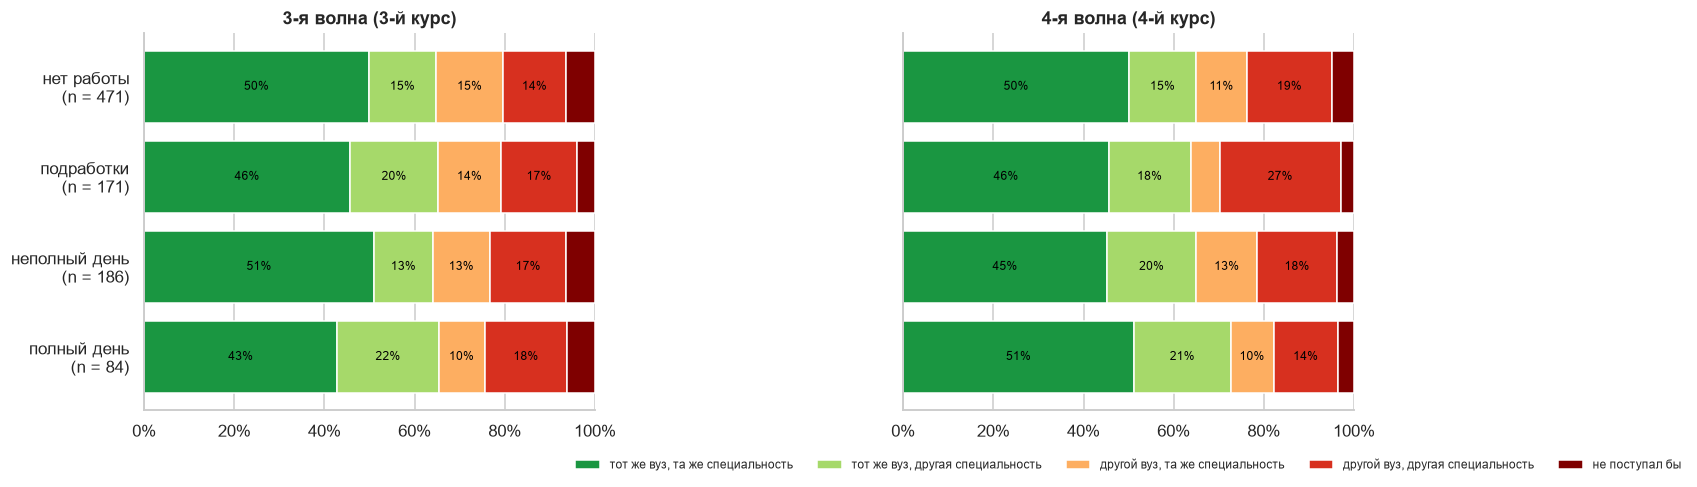

тот же вуз, та же специальность  \
3-я волна (3-й курс) нет работы                               0.499   
                     подработки                               0.457   
                     неполный день                            0.510   
                     полный день                              0.429   
4-я волна (4-й курс) нет работы                               0.501   
                     подработки                               0.456   
                     неполный день                            0.452   
                     полный день                              0.512   

                                    тот же вуз, другая специальность  \
3-я волна (3-й курс) нет работы                                0.149   
                     подработки                                0.196   
                     неполный день                             0.130   
                     полный день                               0.224   
4-я волна (4-й курс) нет работы                                0.149   
                     подработки                                0.181   
                     неполный день                             0.199   
                     полный день                               0.214   

                                    другой вуз, та же специальность  \
3-я волна (3-й курс) нет работы                               0.149   
                     подработки                               0.139   
                     неполный день                            0.126   
                     полный день                              0.102   
4-я волна (4-й курс) нет работы                               0.113   
                     подработки                               0.064   
                     неполный день                            0.134   
                     полный день                              0.095   

                                    другой вуз, другая специальность  \
3-я волна (3-й курс) нет работы                                0.139   
                     подработки                                0.170   
                     неполный день                             0.170   
                     полный день                               0.184   
4-я волна (4-й курс) нет работы                                0.189   
                     подработки                                0.269   
                     неполный день                             0.177   
                     полный день                               0.143   

                                    не поступал бы    n  
3-я волна (3-й курс) нет работы              0.065  678  
                     подработки              0.039  230  
                     неполный день           0.063  253  
                     полный день             0.061   49  
4-я волна (4-й курс) нет работы              0.049  471  
                     подработки              0.029  171  
                     неполный день           0.038  186  
                     полный день             0.036   84

In [21]:
fig, table = two_waves(lambda ax, w: stacked(ax, in_wave[w], f'fmt_{w}', f'edu3_{w}', FORMATS, EDU3, EDU_COLORS,
                                            legend=(w == '4')), figsize=(15, 4.6))
save(fig, 'H_Z2.5_edu3_by_format')
plt.show()
table

Повторный выбор образовательной траектории мало зависит от формата занятости: тот же вуз и ту же специальность выбрали бы 43–51% студентов в каждой группе. Единственное заметное отличие — более частый выбор другого вуза и другой специальности подрабатывающими студентами четвёртого курса (27% против 14–19% в остальных группах).

Сохранено: figures/H_Z2.5_edu3_by_fit.png


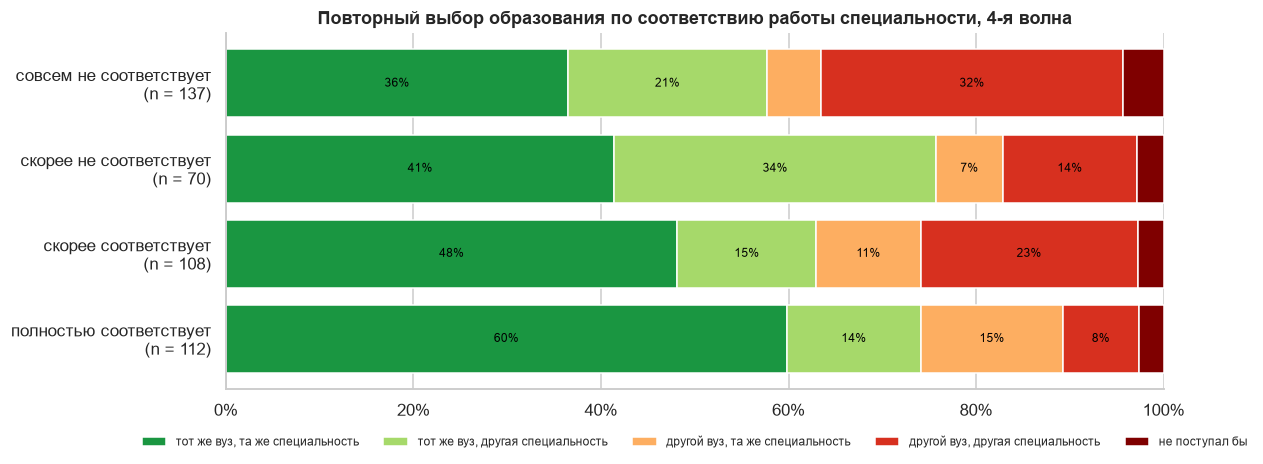

,"тот же вуз, та же специальность","тот же вуз, другая специальность","другой вуз, та же специальность","другой вуз, другая специальность",не поступал бы,n
совсем не соответствует,0.365,0.212,0.058,0.321,0.044,137
скорее не соответствует,0.414,0.343,0.071,0.143,0.029,70
скорее соответствует,0.481,0.148,0.111,0.231,0.028,108
полностью соответствует,0.598,0.143,0.152,0.080,0.027,112


In [22]:
# Повторный выбор и соответствие работы специальности (работающие 4-й волны)
FIT = {1: 'совсем не соответствует', 2: 'скорее не соответствует', 3: 'скорее соответствует', 4: 'полностью соответствует'}
fig, ax = plt.subplots(figsize=(11, 4.2))
table = stacked(ax, workers['4'], 'fit_4', 'edu3_4', FIT, EDU3, EDU_COLORS, title='Повторный выбор образования по соответствию работы специальности, 4-я волна')
save(fig, 'H_Z2.5_edu3_by_fit')
plt.show()
table

Повторный выбор образования тесно связан с соответствием работы специальности. Тот же вуз и ту же специальность выбрали бы 37% студентов, чья работа совсем не соответствует специальности, и 60% при полном соответствии; доля выбирающих другой вуз и другую специальность снижается с 32% до 8%. Работа по специальности, таким образом, сопряжена с большей удовлетворённостью сделанным образовательным выбором; направление этой связи по имеющимся данным установить нельзя.

### ИВ3. Польза и трудности работы (работающие 4-й волны)

#### Г3.1–Г3.2. Соответствие специальности, польза и ущерб успеваемости

*Г3.1 подтверждается* (OR = 2,28); *Г3.2 не подтверждается* (OR = 0,94).

Сохранено: figures/H_G3.1-3.2_benefit_harm_by_fit.png


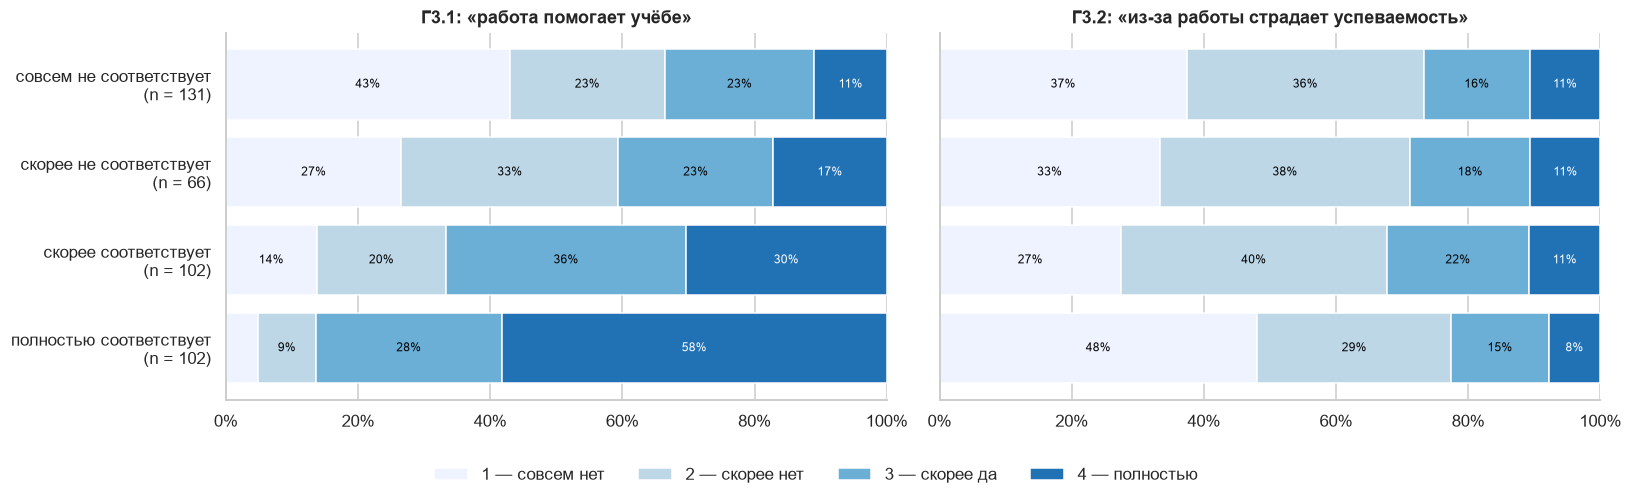

1 — совсем нет  2 — скорее нет  3 — скорее да  \
польза совсем не соответствует           0.430           0.234          0.227   
       скорее не соответствует           0.266           0.328          0.234   
       скорее соответствует              0.137           0.196          0.363   
       полностью соответствует           0.049           0.087          0.282   
ущерб  совсем не соответствует           0.374           0.359          0.160   
       скорее не соответствует           0.333           0.379          0.182   
       скорее соответствует              0.275           0.402          0.216   
       полностью соответствует           0.480           0.294          0.147   

                                4 — полностью    n  
польза совсем не соответствует          0.109  128  
       скорее не соответствует          0.172   64  
       скорее соответствует             0.304  102  
       полностью соответствует          0.583  103  
ущерб  совсем не соответствует          0.107  131  
       скорее не соответствует          0.106   66  
       скорее соответствует             0.108  102  
       полностью соответствует          0.078  102

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4), sharey=True)
t1 = stacked(axes[0], workers['4'], 'fit_4', 'benefit_4', FIT, SCALE4, AGREE, title='Г3.1: «работа помогает учёбе»', legend=False)
t2 = stacked(axes[1], workers['4'], 'fit_4', 'harm_4', FIT, SCALE4, AGREE, title='Г3.2: «из-за работы страдает успеваемость»', legend=False)
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.05))
plt.tight_layout(rect=(0, 0.05, 1, 1))
save(fig, 'H_G3.1-3.2_benefit_harm_by_fit')
plt.show()
pd.concat({'польза': t1, 'ущерб': t2})

Согласие с тем, что работа помогает усваивать учебный материал (ответы «скорее» и «полностью»), возрастает с 34% среди студентов, чья работа совсем не соответствует специальности, до 87% при полном соответствии (Г3.1 подтверждается). Оценка ущерба успеваемости от соответствия специальности практически не зависит: с утверждением о страдающей успеваемости согласны 27–32% на первых трёх уровнях соответствия и 23% при полном соответствии (Г3.2 не подтверждается).

#### Г3.3. Рабочие часы и трудности совмещения

*Подтверждается:* OR = 1,20 на 10 часов.

Сохранено: figures/H_G3.3_difficulty_by_hours.png


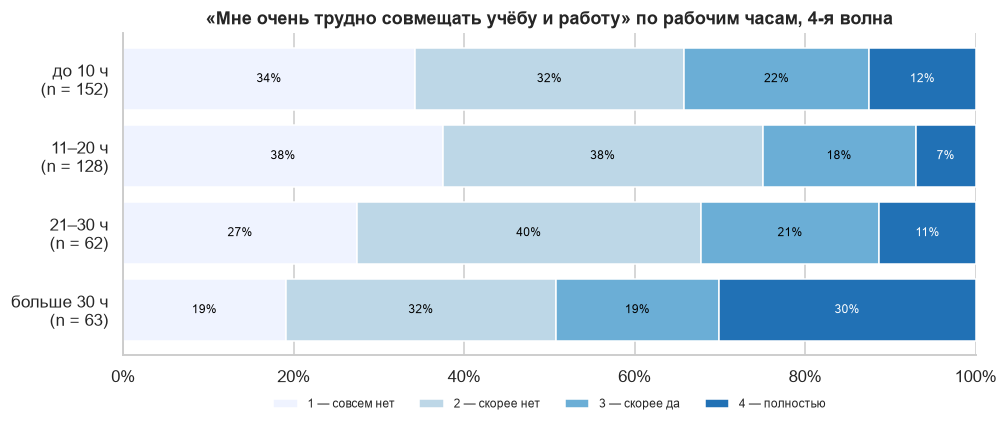

,1 — совсем нет,2 — скорее нет,3 — скорее да,4 — полностью,n
до 10 ч,0.342,0.316,0.217,0.125,152
11–20 ч,0.375,0.375,0.180,0.070,128
21–30 ч,0.274,0.403,0.210,0.113,62
больше 30 ч,0.190,0.317,0.190,0.302,63


In [24]:
fig, ax = plt.subplots(figsize=(10, 3.8))
table = stacked(ax, workers['4'], 'hbin', 'difficulty_4', HOURS_LABELS, SCALE4, AGREE,
                title='«Мне очень трудно совмещать учёбу и работу» по рабочим часам, 4-я волна')
save(fig, 'H_G3.3_difficulty_by_hours')
plt.show()
table

Доля полностью согласных с тем, что совмещать учёбу и работу очень трудно, составляет 7–13% среди работающих до 30 часов в неделю и возрастает до 30% среди работающих более 30 часов. Рост трудностей совмещения сосредоточен в группе с наибольшей нагрузкой (Г3.3 подтверждается).

#### Г3.4–Г3.5. Мотив, польза и трудности

*Г3.4 не подтверждается* (OR = 1,58, p по Холму 0,14); *Г3.5 подтверждается* (OR = 2,52).

Сохранено: figures/H_G3.4-3.5_by_motive.png


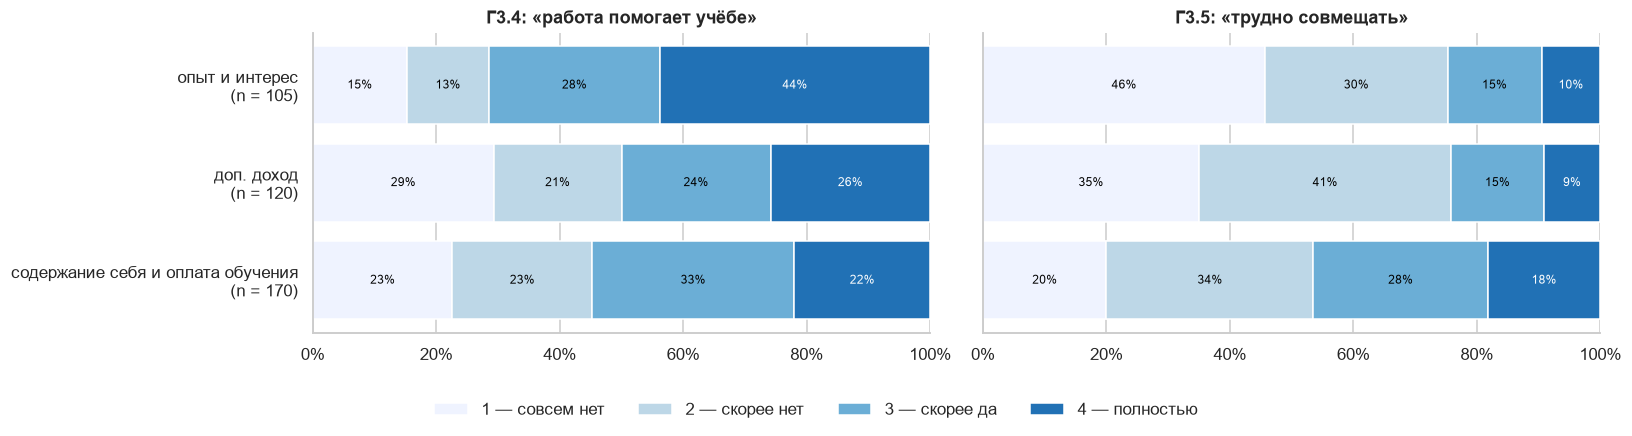

1 — совсем нет  2 — скорее нет  \
польза    опыт и интерес                              0.152           0.133   
          доп. доход                                  0.293           0.207   
          содержание себя и оплата обучения           0.226           0.226   
трудности опыт и интерес                              0.457           0.295   
          доп. доход                                  0.350           0.408   
          содержание себя и оплата обучения           0.200           0.335   

                                             3 — скорее да  4 — полностью    n  
польза    опыт и интерес                             0.276          0.438  105  
          доп. доход                                 0.241          0.259  116  
          содержание себя и оплата обучения          0.327          0.220  168  
трудности опыт и интерес                             0.152          0.095  105  
          доп. доход                                 0.150          0.092  120  
          содержание себя и оплата обучения          0.282          0.182  170

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), sharey=True)
t1 = stacked(axes[0], workers['4'], 'motive_g35_4', 'benefit_4', MOTIVE_G35, SCALE4, AGREE, title='Г3.4: «работа помогает учёбе»', legend=False)
t2 = stacked(axes[1], workers['4'], 'motive_g35_4', 'difficulty_4', MOTIVE_G35, SCALE4, AGREE, title='Г3.5: «трудно совмещать»', legend=False)
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout(rect=(0, 0.06, 1, 1))
save(fig, 'H_G3.4-3.5_by_motive')
plt.show()
pd.concat({'польза': t1, 'трудности': t2})

Работающие ради опыта и интереса к сфере чаще полностью соглашались с тем, что работа помогает учёбе (44% против 22–26% в остальных группах), однако с учётом соответствия работы специальности это различие незначимо (Г3.4 не подтверждается). Работающие ради содержания себя и оплаты обучения почти вдвое чаще отмечали трудности совмещения (46% согласных против 24–25%); различие сохраняется при равных часах и соответствии специальности (Г3.5 подтверждается).

#### З3.7. Мотив работы, оценки и удовлетворённость

Мотивы с числом ответов не меньше 20.

Сохранено: figures/H_Z3.7_marks_sat_by_motive.png


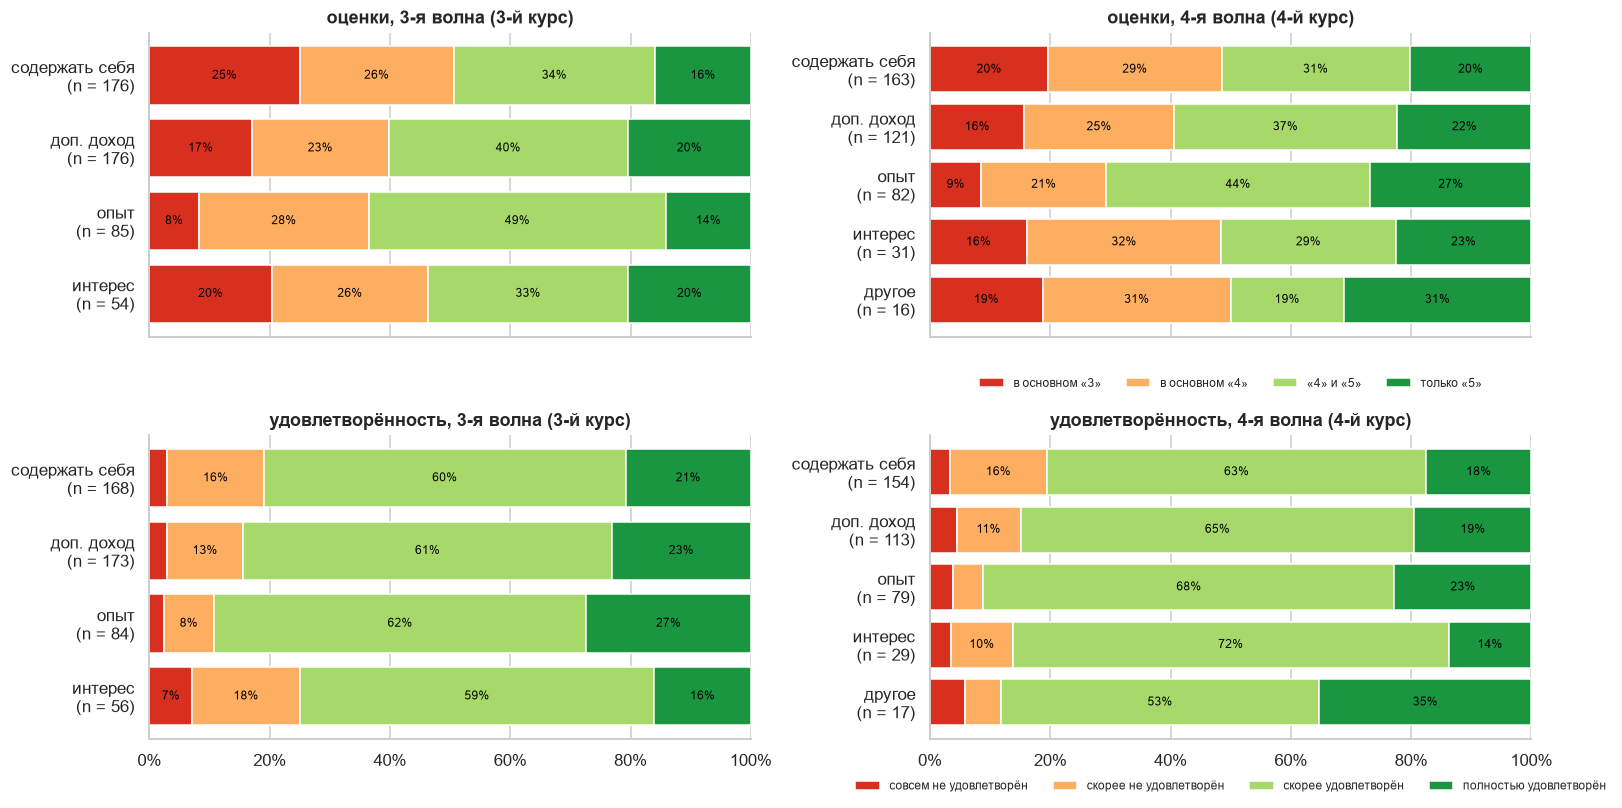

оценки


в основном «3»  в основном «4»  \
3-я волна (3-й курс) содержать себя           0.250           0.256   
                     доп. доход               0.170           0.227   
                     опыт                     0.082           0.282   
                     интерес                  0.204           0.259   
4-я волна (4-й курс) содержать себя           0.196           0.288   
                     доп. доход               0.157           0.248   
                     опыт                     0.085           0.207   
                     интерес                  0.161           0.323   
                     другое                   0.188           0.312   

                                     «4» и «5»  только «5»    n  
3-я волна (3-й курс) содержать себя      0.335       0.159  176  
                     доп. доход          0.398       0.205  176  
                     опыт                0.494       0.141   85  
                     интерес             0.333       0.204   54  
4-я волна (4-й курс) содержать себя      0.313       0.202  163  
                     доп. доход          0.372       0.223  121  
                     опыт                0.439       0.268   82  
                     интерес             0.290       0.226   31  
                     другое              0.188       0.312   16

удовлетворённость


совсем не удовлетворён  \
3-я волна (3-й курс) содержать себя                   0.030   
                     доп. доход                       0.029   
                     опыт                             0.024   
                     интерес                          0.071   
4-я волна (4-й курс) содержать себя                   0.032   
                     доп. доход                       0.044   
                     опыт                             0.038   
                     интерес                          0.034   
                     другое                           0.059   

                                     скорее не удовлетворён  \
3-я волна (3-й курс) содержать себя                   0.161   
                     доп. доход                       0.127   
                     опыт                             0.083   
                     интерес                          0.179   
4-я волна (4-й курс) содержать себя                   0.162   
                     доп. доход                       0.106   
                     опыт                             0.051   
                     интерес                          0.103   
                     другое                           0.059   

                                     скорее удовлетворён  \
3-я волна (3-й курс) содержать себя                0.601   
                     доп. доход                    0.613   
                     опыт                          0.619   
                     интерес                       0.589   
4-я волна (4-й курс) содержать себя                0.630   
                     доп. доход                    0.655   
                     опыт                          0.684   
                     интерес                       0.724   
                     другое                        0.529   

                                     полностью удовлетворён    n  
3-я волна (3-й курс) содержать себя                   0.208  168  
                     доп. доход                       0.231  173  
                     опыт                             0.274   84  
                     интерес                          0.161   56  
4-я волна (4-й курс) содержать себя                   0.175  154  
                     доп. доход                       0.195  113  
                     опыт                             0.228   79  
                     интерес                          0.138   29  
                     другое                           0.353   17

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(15, 7.5), sharex=True)
tables = {}
for row, (var, levels, label) in enumerate([('mark', MARKS, 'оценки'), ('sat', SAT, 'удовлетворённость')]):
    for col, w in enumerate(['3', '4']):
        motives = [m for m in MOTIVES if (workers[w][f'motive_raw_{w}'] == m).sum() >= 20]
        tables[(label, WAVES[w])] = stacked(axes[row, col], workers[w], f'motive_raw_{w}', f'{var}_{w}', motives, levels,
                                            RED_GREEN[4], title=f'{label}, {WAVES[w]}', legend=(col == 1))
plt.tight_layout()
save(fig, 'H_Z3.7_marks_sat_by_motive')
plt.show()
show_tables(tables)

Среди работающих ради опыта доля получающих в основном удовлетворительные оценки наименьшая (8–9% против 16–25% при других мотивах). Наибольшая она среди работающих ради содержания себя (25% и 20%). Удовлетворённость обучением по мотивам различается мало: скорее или полностью удовлетворены 75–91% студентов во всех группах.

#### З3.8. Субъективный ущерб успеваемости и оценки

Сохранено: figures/H_Z3.8_marks_by_harm.png


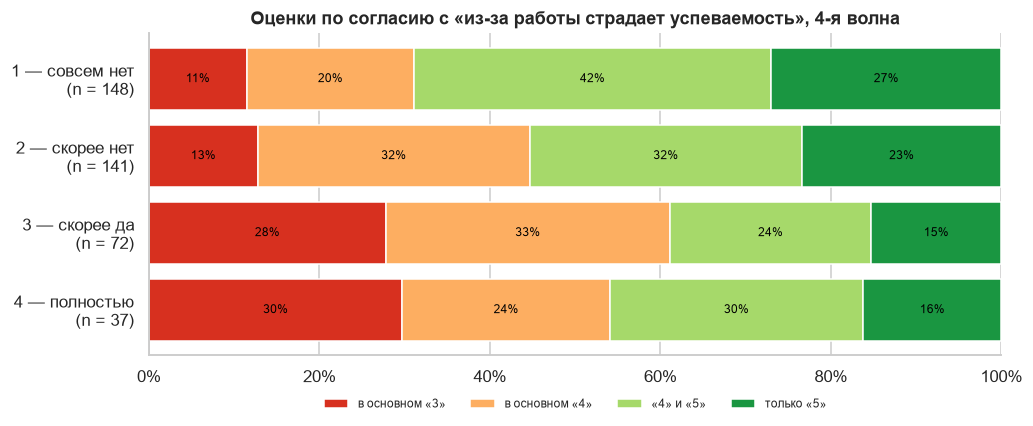

,в основном «3»,в основном «4»,«4» и «5»,только «5»,n
1 — совсем нет,0.115,0.196,0.419,0.270,148
2 — скорее нет,0.128,0.319,0.319,0.234,141
3 — скорее да,0.278,0.333,0.236,0.153,72
4 — полностью,0.297,0.243,0.297,0.162,37


In [27]:
fig, ax = plt.subplots(figsize=(10, 3.8))
table = stacked(ax, workers['4'], 'harm_4', 'mark_4', SCALE4, MARKS, RED_GREEN[4],
                title='Оценки по согласию с «из-за работы страдает успеваемость», 4-я волна')
save(fig, 'H_Z3.8_marks_by_harm')
plt.show()
table

Субъективная оценка ущерба от работы согласуется с самоотчётной успеваемостью. Среди не согласных с тем, что из-за работы страдает успеваемость, в основном удовлетворительные оценки получают 12–13% студентов, среди согласных — 28–30%. Доля получающих только отличные оценки снижается с 23–27% до 15–16%. Это свидетельствует о том, что студенты в целом адекватно оценивают последствия работы для учёбы.

### ИВ4. Опыт стажировок

#### З4.1. Кто проходил стажировку

Сохранено: figures/H_Z4.1_internship_by_group.png


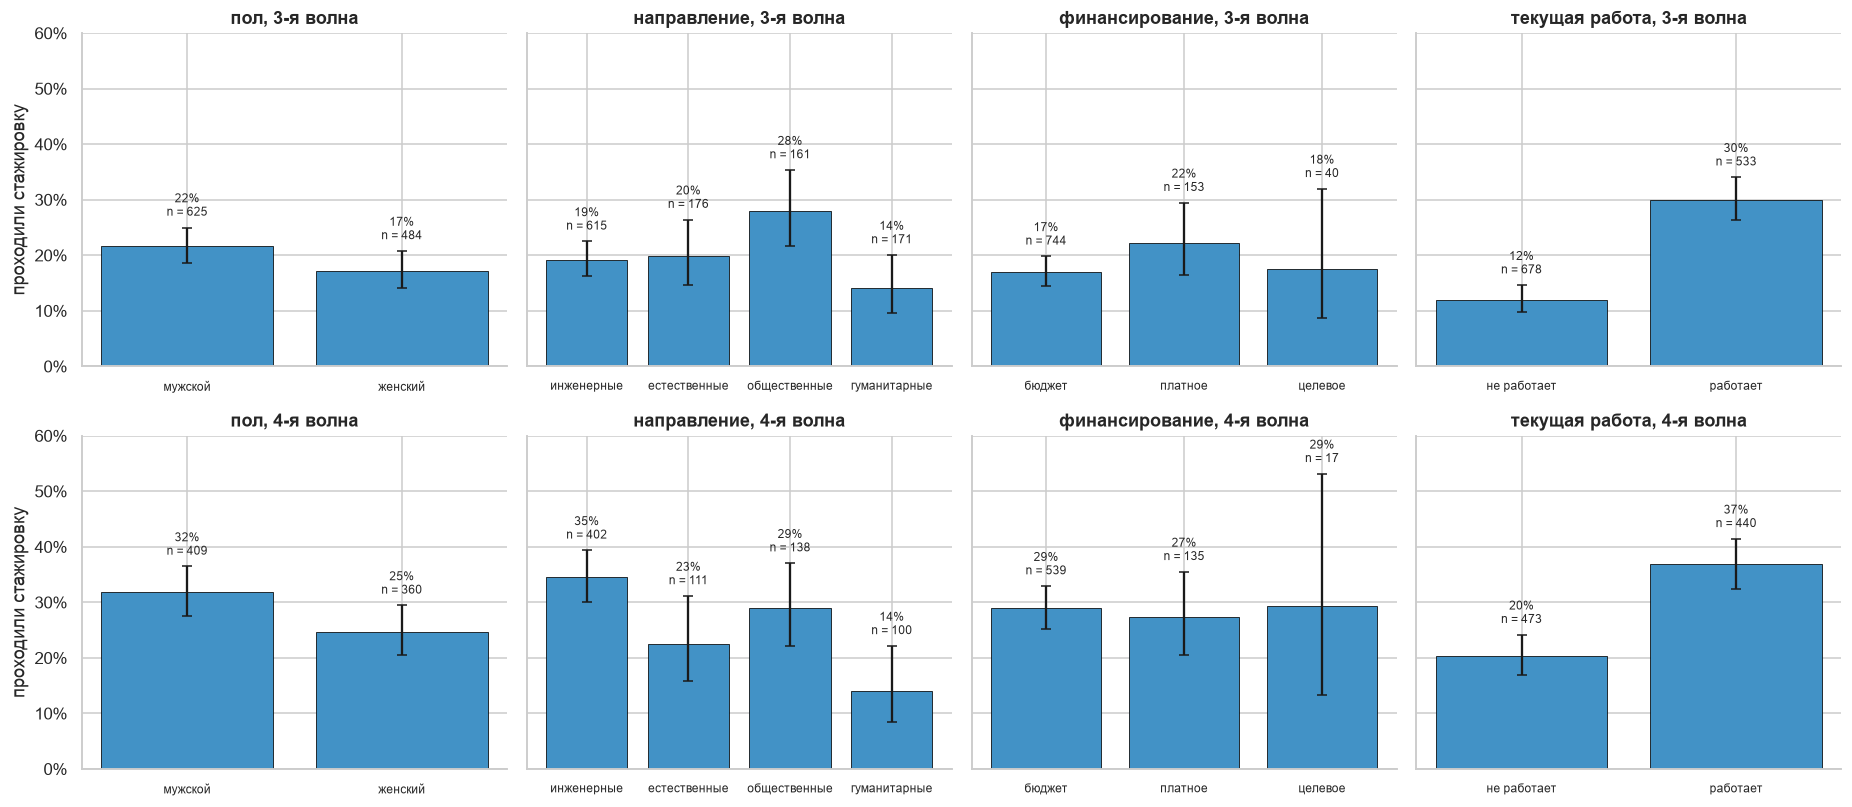

доля        от  \
3-я волна (3-й курс) пол            мужской       0.216000  0.185525   
                                    женский       0.171488  0.140526   
                     направление    инженерные    0.191870  0.162699   
                                    естественные  0.198864  0.146607   
                                    общественные  0.279503  0.215944   
                                    гуманитарные  0.140351  0.096163   
                     финансирование бюджет        0.169355  0.144118   
                                    платное       0.222222  0.163607   
                                    целевое       0.175000  0.087454   
                     текущая работа не работает   0.119469  0.097174   
                                    работает      0.300188  0.262820   
4-я волна (4-й курс) пол            мужской       0.317848  0.274595   
                                    женский       0.247222  0.205484   
                     направление    инженерные    0.345771  0.300935   
                                    естественные  0.225225  0.157465   
                                    общественные  0.289855  0.220666   
                                    гуманитарные  0.140000  0.085263   
                     финансирование бюджет        0.289425  0.252737   
                                    платное       0.274074  0.205868   
                                    целевое       0.294118  0.132800   
                     текущая работа не работает   0.202960  0.169174   
                                    работает      0.368182  0.324438   

                                                        до      n  
3-я волна (3-й курс) пол            мужской       0.249945  625.0  
                                    женский       0.207623  484.0  
                     направление    инженерные    0.224866  615.0  
                                    естественные  0.263985  176.0  
                                    общественные  0.353339  161.0  
                                    гуманитарные  0.200342  171.0  
                     финансирование бюджет        0.197988  744.0  
                                    платное       0.294444  153.0  
                                    целевое       0.319500   40.0  
                     текущая работа не работает   0.146052  678.0  
                                    работает      0.340415  533.0  
4-я волна (4-й курс) пол            мужской       0.364492  409.0  
                                    женский       0.294298  360.0  
                     направление    инженерные    0.393527  402.0  
                                    естественные  0.311368  111.0  
                                    общественные  0.370427  138.0  
                                    гуманитарные  0.221372  100.0  
                     финансирование бюджет        0.329093  539.0  
                                    платное       0.354782  135.0  
                                    целевое       0.531331   17.0  
                     текущая работа не работает   0.241532  473.0  
                                    работает      0.414208  440.0

In [28]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5), sharey=True)
tables = {}
for row, w in enumerate(['3', '4']):
    for col, (group, groups, label) in enumerate([('sex_c', ['мужской', 'женский'], 'пол'),
                                                  ('major_c', ['инженерные', 'естественные', 'общественные', 'гуманитарные'], 'направление'),
                                                  ('funding_c', FUNDING, 'финансирование'),
                                                  (f'emp_{w}', {0: 'не работает', 1: 'работает'}, 'текущая работа')]):
        tables[(WAVES[w], label)] = bars(axes[row, col], in_wave[w], group, f'intern_{w}', groups, ymax=0.6,
                                         title=f'{label}, {w}-я волна', ylabel='проходили стажировку' if col == 0 else '')
        axes[row, col].tick_params(axis='x', labelsize=8)
plt.tight_layout()
save(fig, 'H_Z4.1_internship_by_group')
plt.show()
pd.concat(tables)

Опыт стажировки чаще встречается у работающих студентов (30% против 12% на третьем курсе, 37% против 20% на четвёртом), у мужчин (22% против 17% и 32% против 25%), а также на инженерных и общественных направлениях (до 35%); реже всего — у студентов гуманитарных направлений (14%). Различий по форме финансирования не выявлено. Стажировки и оплачиваемая работа, таким образом, концентрируются у одной и той же группы студентов.

Сохранено: figures/H_Z4.1_course_motive.png


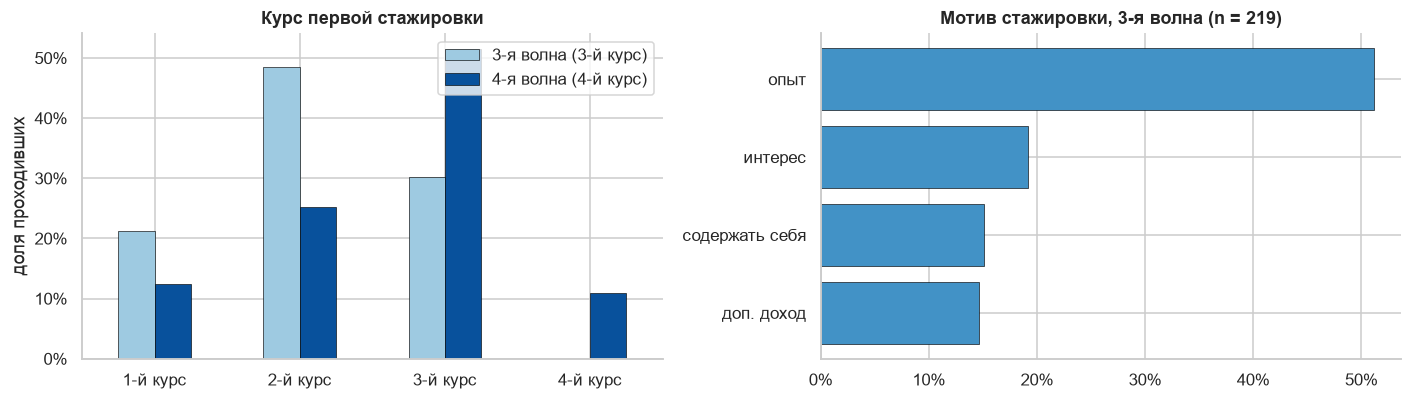

3-я волна (3-й курс)  4-я волна (4-й курс)  3-я волна
курс  1-й курс                    0.211618              0.124031        NaN
      2-й курс                    0.485477              0.251938        NaN
      3-й курс                    0.302905              0.515504        NaN
      4-й курс                    0.000000              0.108527        NaN
мотив опыт                             NaN                   NaN   0.511416
      интерес                          NaN                   NaN   0.191781
      содержать себя                   NaN                   NaN   0.150685
      доп. доход                       NaN                   NaN   0.146119

In [29]:
# Курс первой стажировки и мотив (3-я волна)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
course = pd.DataFrame({WAVES[w]: d[f'intern_course_{w}'].value_counts(normalize=True).reindex([1, 2, 3, 4], fill_value=0)
                       for w in ['3', '4']})
course.index = ['1-й курс', '2-й курс', '3-й курс', '4-й курс']
course.plot.bar(ax=ax1, color=['#9ecae1', '#08519c'], edgecolor='black', linewidth=0.4, rot=0)
ax1.yaxis.set_major_formatter(percent)
ax1.set(title='Курс первой стажировки', ylabel='доля проходивших')
motive = d['intern_motive_raw_3'].astype(object).value_counts(normalize=True).reindex(['опыт', 'интерес', 'содержать себя', 'доп. доход'])
ax2.barh(range(4), motive, color='#4292c6', edgecolor='black', linewidth=0.4)
ax2.set_yticks(range(4), motive.index)
ax2.invert_yaxis()
ax2.xaxis.set_major_formatter(percent)
ax2.set(title=f"Мотив стажировки, 3-я волна (n = {d['intern_motive_raw_3'].notna().sum()})")
plt.tight_layout()
save(fig, 'H_Z4.1_course_motive')
plt.show()
pd.concat({'курс': course, 'мотив': motive.to_frame('3-я волна')})

Первая стажировка обычно приходится на второй–третий курс. По данным третьей волны чаще назывался второй курс (49%), по данным четвёртой — третий (52%): к четвёртому курсу опыт стажировки приобрели и те, кто стажировался позднее. Основной мотив прохождения стажировки — получение опыта (51%).

#### Г4.2–Г4.3. Соответствие стажировки направлению, польза и ущерб (3-я волна)

*Обе подтверждаются:* OR = 2,94 и 0,58.

Сохранено: figures/H_G4.2-4.3_internship_fit.png


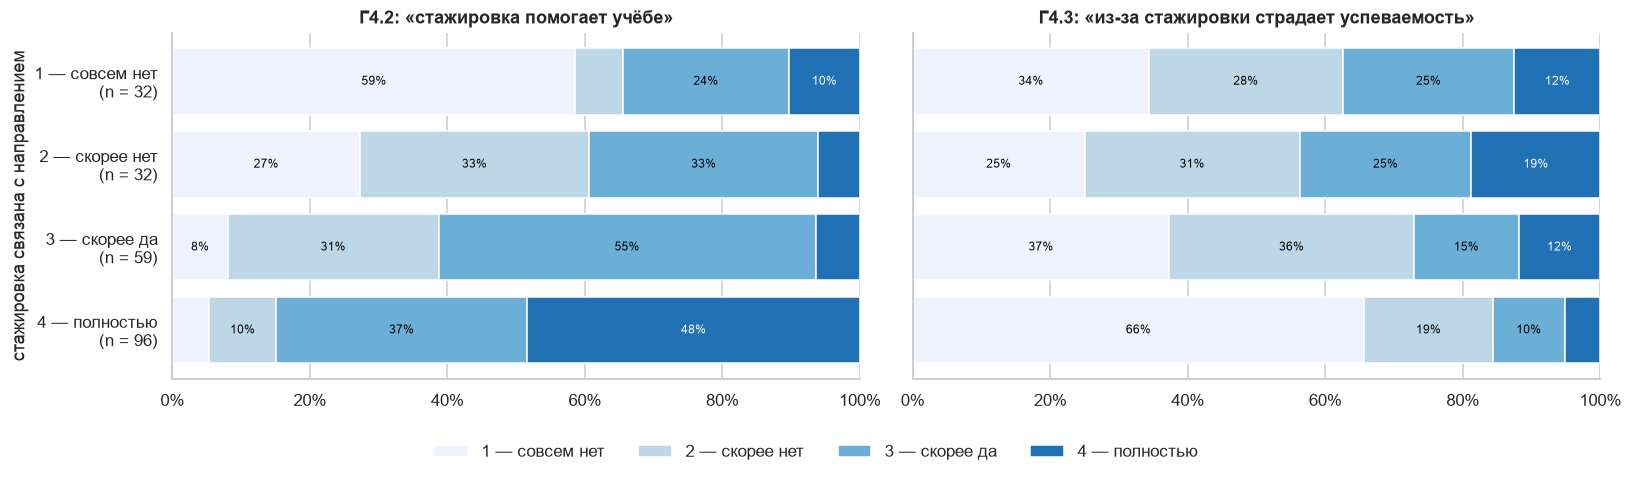

1 — совсем нет  2 — скорее нет  3 — скорее да  \
польза 1 — совсем нет           0.586           0.069          0.241   
       2 — скорее нет           0.273           0.333          0.333   
       3 — скорее да            0.081           0.306          0.548   
       4 — полностью            0.054           0.097          0.366   
ущерб  1 — совсем нет           0.344           0.281          0.250   
       2 — скорее нет           0.250           0.312          0.250   
       3 — скорее да            0.373           0.356          0.153   
       4 — полностью            0.656           0.188          0.104   

                       4 — полностью   n  
польза 1 — совсем нет          0.103  29  
       2 — скорее нет          0.061  33  
       3 — скорее да           0.065  62  
       4 — полностью           0.484  93  
ущерб  1 — совсем нет          0.125  32  
       2 — скорее нет          0.188  32  
       3 — скорее да           0.119  59  
       4 — полностью           0.052  96

In [30]:
interns = d[d['intern_3'].eq(1)]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), sharey=True)
t1 = stacked(axes[0], interns, 'intern_fit_3', 'intern_benefit_3', SCALE4, SCALE4, AGREE, title='Г4.2: «стажировка помогает учёбе»', legend=False)
t2 = stacked(axes[1], interns, 'intern_fit_3', 'intern_harm_3', SCALE4, SCALE4, AGREE, title='Г4.3: «из-за стажировки страдает успеваемость»', legend=False)
axes[0].set_ylabel('стажировка связана с направлением')
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.05))
plt.tight_layout(rect=(0, 0.05, 1, 1))
save(fig, 'H_G4.2-4.3_internship_fit')
plt.show()
pd.concat({'польза': t1, 'ущерб': t2})

При полном соответствии стажировки направлению обучения 48% студентов полностью согласны с тем, что она помогает усваивать учебный материал, тогда как при меньшем соответствии — 6–10% (Г4.2 подтверждается). Оценка ущерба успеваемости при полном соответствии также ниже: вариант «совсем не согласен» выбрали 66% против 25–37% (Г4.3 подтверждается). Группы с низким соответствием малочисленны (29–33 наблюдения).

#### Г4.4. Мотив стажировки и польза (3-я волна)

*Подтверждается в основном варианте:* OR = 2,13; в полных случаях не значимо.

Сохранено: figures/H_G4.4_benefit_by_intern_motive.png


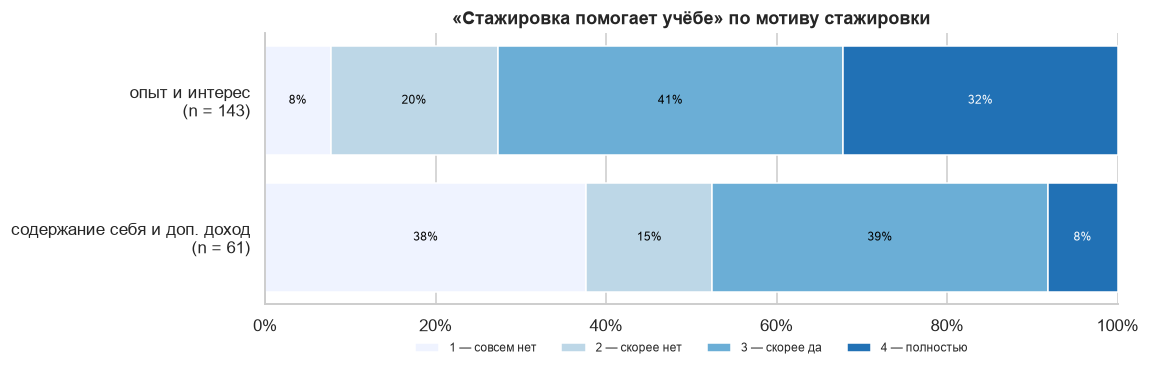

,1 — совсем нет,2 — скорее нет,3 — скорее да,4 — полностью,n
опыт и интерес,0.077,0.196,0.406,0.322,143
содержание себя и доп. доход,0.377,0.148,0.393,0.082,61


In [31]:
fig, ax = plt.subplots(figsize=(10, 3.2))
table = stacked(ax, interns, 'intern_motive_g44_3', 'intern_benefit_3', ['опыт и интерес', 'содержание себя и доп. доход'],
                SCALE4, AGREE, title='«Стажировка помогает учёбе» по мотиву стажировки')
save(fig, 'H_G4.4_benefit_by_intern_motive')
plt.show()
table

Студенты, выбравшие стажировку ради опыта или интереса к сфере, чаще отмечали её пользу для учёбы (73% согласных против 48% среди выбравших её ради дохода); среди последних 38% не видят пользы совсем. В основном варианте модели различие значимо (Г4.4), однако в анализе полных случаев не подтверждается, поэтому вывод следует считать неустойчивым.

#### З4.5. Оплачиваемые и неоплачиваемые стажировки

Сохранено: figures/H_Z4.5_paid_unpaid.png


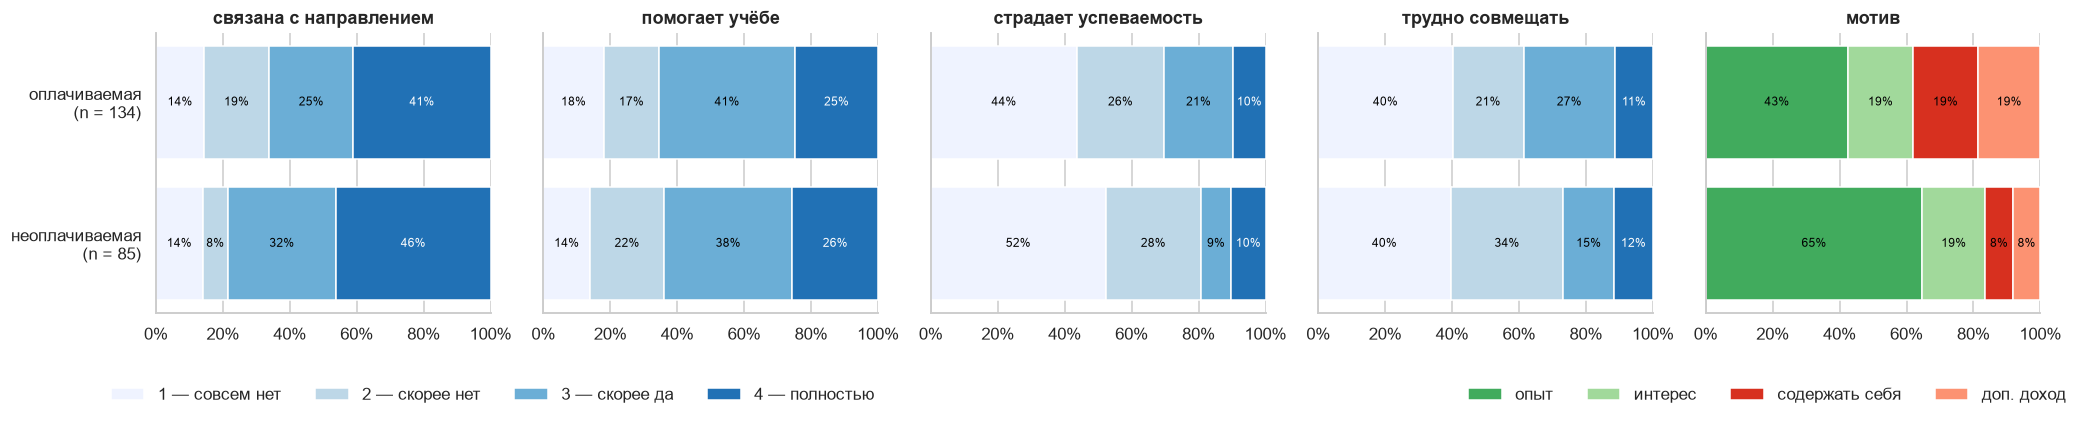

связана с направлением


,1 — совсем нет,2 — скорее нет,3 — скорее да,4 — полностью,n
оплачиваемая,0.144,0.194,0.252,0.410,139
неоплачиваемая,0.140,0.075,0.323,0.462,93


помогает учёбе


,1 — совсем нет,2 — скорее нет,3 — скорее да,4 — полностью,n
оплачиваемая,0.18,0.165,0.406,0.248,133
неоплачиваемая,0.14,0.221,0.384,0.256,86


страдает успеваемость


,1 — совсем нет,2 — скорее нет,3 — скорее да,4 — полностью,n
оплачиваемая,0.437,0.259,0.207,0.096,135
неоплачиваемая,0.523,0.284,0.091,0.102,88


трудно совмещать


,1 — совсем нет,2 — скорее нет,3 — скорее да,4 — полностью,n
оплачиваемая,0.402,0.212,0.273,0.114,132
неоплачиваемая,0.395,0.337,0.151,0.116,86


мотив


,опыт,интерес,содержать себя,доп. доход,n
оплачиваемая,0.425,0.194,0.194,0.187,134
неоплачиваемая,0.647,0.188,0.082,0.082,85


In [32]:
PAID = {1: 'оплачиваемая', 0: 'неоплачиваемая'}
fig, axes = plt.subplots(1, 5, figsize=(19, 3.6), sharey=True)
tables = {}
for ax, (var, label) in zip(axes, [('intern_fit_3', 'связана с направлением'), ('intern_benefit_3', 'помогает учёбе'),
                                   ('intern_harm_3', 'страдает успеваемость'), ('intern_difficulty_3', 'трудно совмещать')]):
    tables[label] = stacked(ax, interns, 'intern_paid_3', var, PAID, SCALE4, AGREE, title=label, legend=False)
tables['мотив'] = stacked(axes[4], interns, 'intern_paid_3', 'intern_motive_raw_3', PAID, ['опыт', 'интерес', 'содержать себя', 'доп. доход'],
                          ['#41ab5d', '#a1d99b', '#d7301f', '#fc9272'], title='мотив', legend=False)
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower left', ncol=4, frameon=False, bbox_to_anchor=(0.05, -0.08))
fig.legend(*axes[4].get_legend_handles_labels(), loc='lower right', ncol=4, frameon=False, bbox_to_anchor=(1, -0.08))
plt.tight_layout(rect=(0, 0.06, 1, 1))
save(fig, 'H_Z4.5_paid_unpaid')
plt.show()
show_tables(tables)

Оплачиваемые и неоплачиваемые стажировки оцениваются сходно по соответствию направлению и пользе для учёбы. Оплачиваемые несколько чаще сопровождаются трудностями совмещения (39% согласных против 27%). Различаются прежде всего мотивы: неоплачиваемые стажировки выбирают ради опыта (65% против 43%), оплачиваемые — чаще ради содержания себя и дохода (38% против 16%).

#### З4.6. Сочетания текущей работы и опыта стажировки

Сохранено: figures/H_Z4.6_work_internship.png


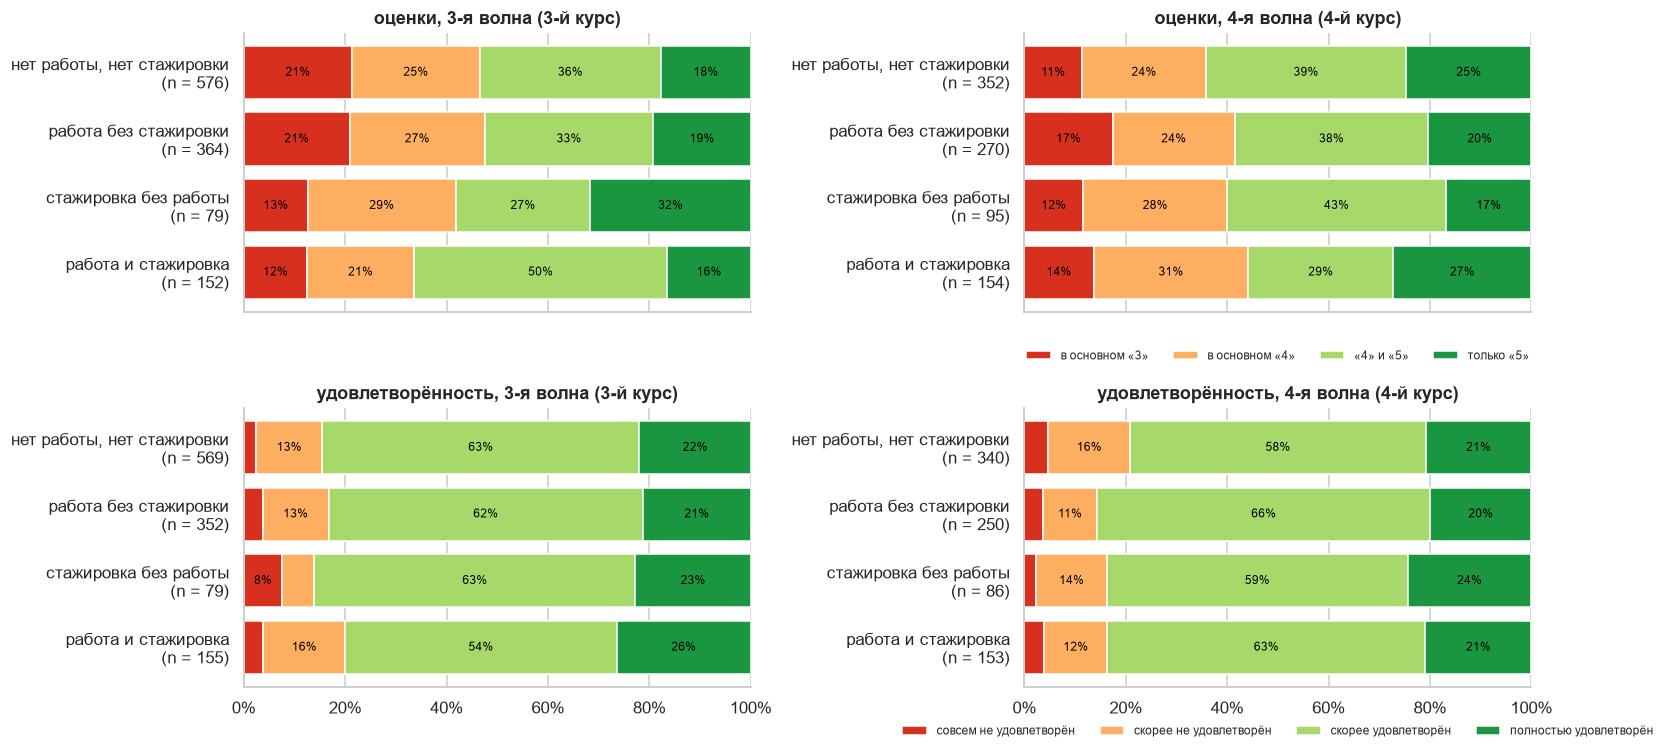

оценки


в основном «3»  \
3-я волна (3-й курс) нет работы, нет стажировки           0.214   
                     работа без стажировки                0.209   
                     стажировка без работы                0.127   
                     работа и стажировка                  0.125   
4-я волна (4-й курс) нет работы, нет стажировки           0.114   
                     работа без стажировки                0.174   
                     стажировка без работы                0.116   
                     работа и стажировка                  0.136   

                                                 в основном «4»  «4» и «5»  \
3-я волна (3-й курс) нет работы, нет стажировки           0.252      0.358   
                     работа без стажировки                0.266      0.332   
                     стажировка без работы                0.291      0.266   
                     работа и стажировка                  0.211      0.500   
4-я волна (4-й курс) нет работы, нет стажировки           0.244      0.395   
                     работа без стажировки                0.241      0.381   
                     стажировка без работы                0.284      0.432   
                     работа и стажировка                  0.305      0.286   

                                                 только «5»    n  
3-я волна (3-й курс) нет работы, нет стажировки       0.177  576  
                     работа без стажировки            0.192  364  
                     стажировка без работы            0.316   79  
                     работа и стажировка              0.164  152  
4-я волна (4-й курс) нет работы, нет стажировки       0.247  352  
                     работа без стажировки            0.204  270  
                     стажировка без работы            0.168   95  
                     работа и стажировка              0.273  154

удовлетворённость


совсем не удовлетворён  \
3-я волна (3-й курс) нет работы, нет стажировки                   0.025   
                     работа без стажировки                        0.037   
                     стажировка без работы                        0.076   
                     работа и стажировка                          0.039   
4-я волна (4-й курс) нет работы, нет стажировки                   0.047   
                     работа без стажировки                        0.036   
                     стажировка без работы                        0.023   
                     работа и стажировка                          0.039   

                                                 скорее не удовлетворён  \
3-я волна (3-й курс) нет работы, нет стажировки                   0.130   
                     работа без стажировки                        0.131   
                     стажировка без работы                        0.063   
                     работа и стажировка                          0.161   
4-я волна (4-й курс) нет работы, нет стажировки                   0.162   
                     работа без стажировки                        0.108   
                     стажировка без работы                        0.140   
                     работа и стажировка                          0.124   

                                                 скорее удовлетворён  \
3-я волна (3-й курс) нет работы, нет стажировки                0.626   
                     работа без стажировки                     0.619   
                     стажировка без работы                     0.633   
                     работа и стажировка                       0.535   
4-я волна (4-й курс) нет работы, нет стажировки                0.582   
                     работа без стажировки                     0.656   
                     стажировка без работы                     0.593   
                     работа и стажировка                       0.627   

                                                 полностью удовлетворён    n  
3-я волна (3-й курс) нет работы, нет стажировки                   0.220  569  
                     работа без стажировки                        0.213  352  
                     стажировка без работы                        0.228   79  
                     работа и стажировка                          0.265  155  
4-я волна (4-й курс) нет работы, нет стажировки                   0.209  340  
                     работа без стажировки                        0.200  250  
                     стажировка без работы                        0.244   86  
                     работа и стажировка                          0.209  153

In [33]:
WI = ['нет работы, нет стажировки', 'работа без стажировки', 'стажировка без работы', 'работа и стажировка']
fig, axes = plt.subplots(2, 2, figsize=(15, 7), sharex=True)
tables = {}
for row, (var, levels, label) in enumerate([('mark', MARKS, 'оценки'), ('sat', SAT, 'удовлетворённость')]):
    for col, w in enumerate(['3', '4']):
        tables[(label, WAVES[w])] = stacked(axes[row, col], in_wave[w], f'work_intern_{w}', f'{var}_{w}', WI, levels,
                                            RED_GREEN[4], title=f'{label}, {WAVES[w]}', legend=(col == 1))
plt.tight_layout()
save(fig, 'H_Z4.6_work_internship')
plt.show()
show_tables(tables)

На третьем курсе студенты, сочетающие работу и опыт стажировки, чаще получали хорошие и отличные оценки (50% против 27–36% в других группах) и реже — удовлетворительные (13% против 21%). На четвёртом курсе эти различия сглаживаются. Удовлетворённость обучением от сочетания работы и стажировки не зависит. Последовательность событий неизвестна: стажировка могла предшествовать текущей работе.

### ИВ5. Занятость и здоровье

#### Г5.1–Г5.2. Рабочие часы и сон

*Г5.1 частично подтверждается* (только 3-я волна, −0,15 ч на 10 часов, неустойчиво); *Г5.2 не подтверждается*.

Сохранено: figures/H_G5.1-5.2_sleep_by_hours.png


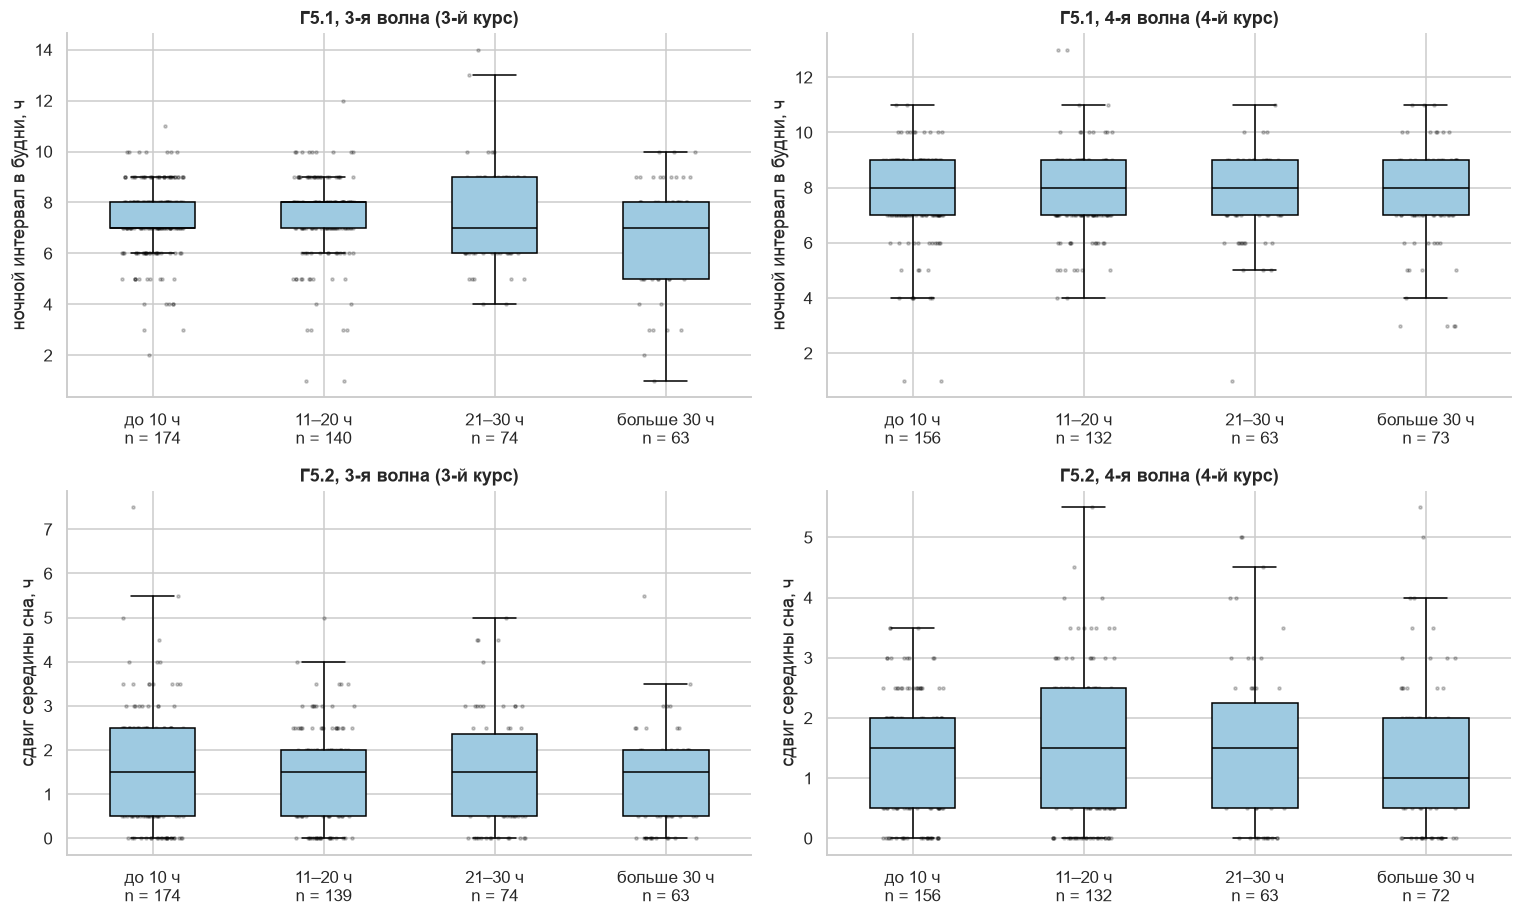

count  25%  50%  \
ночной интервал в будни, ч 3-я волна (3-й курс) до 10 ч      174.0  7.0  7.0   
                                                11–20 ч      140.0  7.0  8.0   
                                                21–30 ч       74.0  6.0  7.0   
                                                больше 30 ч   63.0  5.0  7.0   
                           4-я волна (4-й курс) до 10 ч      156.0  7.0  8.0   
                                                11–20 ч      132.0  7.0  8.0   
                                                21–30 ч       63.0  7.0  8.0   
                                                больше 30 ч   73.0  7.0  8.0   
сдвиг середины сна, ч      3-я волна (3-й курс) до 10 ч      174.0  0.5  1.5   
                                                11–20 ч      139.0  0.5  1.5   
                                                21–30 ч       74.0  0.5  1.5   
                                                больше 30 ч   63.0  0.5  1.5   
                           4-я волна (4-й курс) до 10 ч      156.0  0.5  1.5   
                                                11–20 ч      132.0  0.5  1.5   
                                                21–30 ч       63.0  0.5  1.5   
                                                больше 30 ч   72.0  0.5  1.0   

                                                              75%  
ночной интервал в будни, ч 3-я волна (3-й курс) до 10 ч      8.00  
                                                11–20 ч      8.00  
                                                21–30 ч      9.00  
                                                больше 30 ч  8.00  
                           4-я волна (4-й курс) до 10 ч      9.00  
                                                11–20 ч      9.00  
                                                21–30 ч      9.00  
                                                больше 30 ч  9.00  
сдвиг середины сна, ч      3-я волна (3-й курс) до 10 ч      2.50  
                                                11–20 ч      2.00  
                                                21–30 ч      2.38  
                                                больше 30 ч  2.00  
                           4-я волна (4-й курс) до 10 ч      2.00  
                                                11–20 ч      2.50  
                                                21–30 ч      2.25  
                                                больше 30 ч  2.00

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8.5))
tables = {}
for row, (var, label) in enumerate([('sleep_dur_wd', 'ночной интервал в будни, ч'), ('sjl', 'сдвиг середины сна, ч')]):
    for col, w in enumerate(['3', '4']):
        tables[(label, WAVES[w])] = boxes(axes[row, col], workers[w], 'hbin', f'{var}_{w}', HOURS_LABELS,
                                          title=f'{"Г5.1" if row == 0 else "Г5.2"}, {WAVES[w]}', ylabel=label)
plt.tight_layout()
save(fig, 'H_G5.1-5.2_sleep_by_hours')
plt.show()
pd.concat(tables)

На третьем курсе у работающих более 20 часов в неделю нижняя квартиль ночного интервала в будни составляет 5–6 часов против 7 часов при меньшей нагрузке; на четвёртом курсе распределения не различаются (медиана 8 часов). Связь часов с сокращением сна наблюдается, таким образом, лишь в одной волне и неустойчива к исключению сомнительных значений (Г5.1 подтверждается частично). Сдвиг середины сна между буднями и выходными от нагрузки не зависит: медиана составляет 1–1,5 часа во всех группах (Г5.2 не подтверждается).

#### Г5.3. Формат занятости и занятия спортом

*Не подтверждается:* в 4-й волне работающие полный день занимаются спортом чаще (OR = 1,75).

Сохранено: figures/H_G5.3_sport_by_format.png


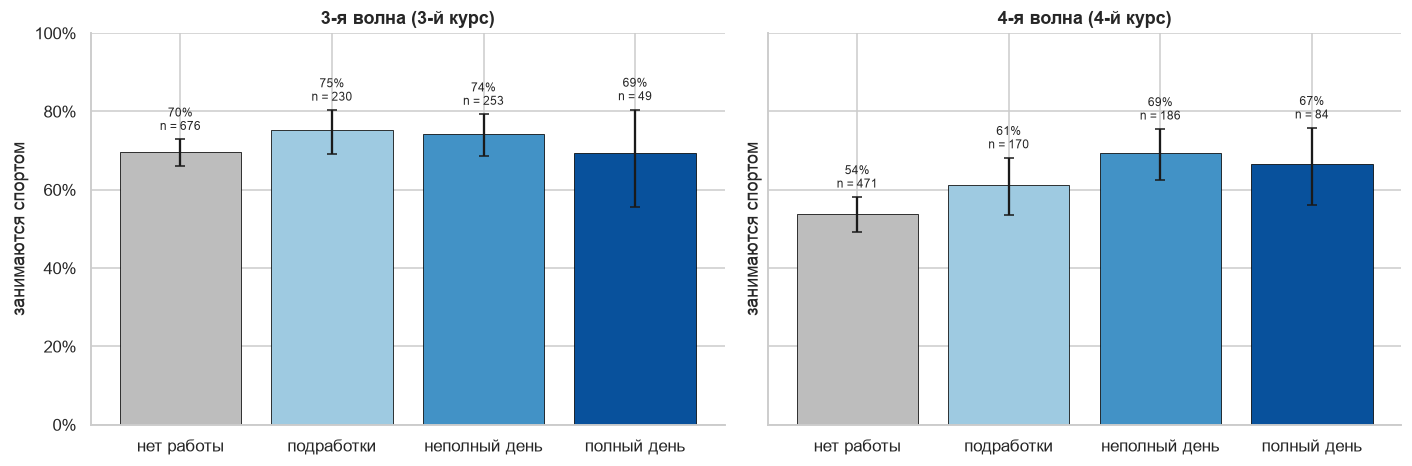

доля        от        до      n
3-я волна (3-й курс) нет работы     0.695266  0.659545  0.728781  676.0
                     подработки     0.752174  0.692539  0.803524  230.0
                     неполный день  0.743083  0.685888  0.793006  253.0
                     полный день    0.693878  0.554721  0.804845   49.0
4-я волна (4-й курс) нет работы     0.537155  0.492006  0.581703  471.0
                     подработки     0.611765  0.536807  0.681783  170.0
                     неполный день  0.693548  0.623935  0.755329  186.0
                     полный день    0.666667  0.560528  0.758228   84.0

In [35]:
fig, table = two_waves(lambda ax, w: bars(ax, in_wave[w], f'fmt_{w}', f'pe_{w}', FORMATS,
                                         colors=[FORMAT_COLORS[f] for f in FORMATS], ylabel='занимаются спортом', ymax=1))
save(fig, 'H_G5.3_sport_by_format')
plt.show()
table

Занятость не сопровождается снижением физической активности. На третьем курсе доли занимающихся спортом практически одинаковы (69–75%), на четвёртом работающие занимаются им чаще неработающих (61–69% против 54%), что противоположно Г5.3. От третьего к четвёртому курсу доля занимающихся спортом снижается во всех группах, но в наибольшей степени — среди неработающих (с 70% до 54%).

#### Г5.4. Рабочие часы и частота занятий спортом (3-я волна)

*Не подтверждается:* OR = 0,94.

Сохранено: figures/H_G5.4_sport_freq_by_hours.png


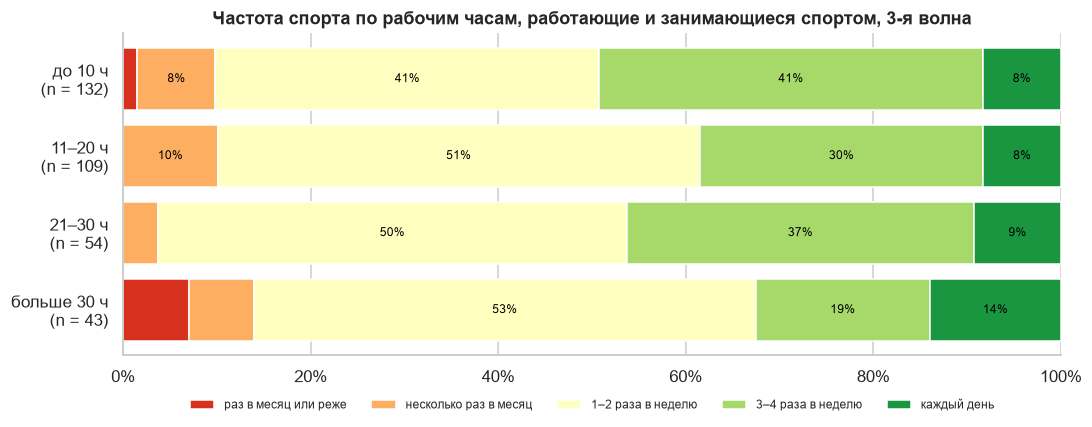

,раз в месяц или реже,несколько раз в месяц,1–2 раза в неделю,3–4 раза в неделю,каждый день,n
до 10 ч,0.015,0.083,0.409,0.409,0.083,132
11–20 ч,0.000,0.101,0.514,0.303,0.083,109
21–30 ч,0.000,0.037,0.500,0.370,0.093,54
больше 30 ч,0.070,0.070,0.535,0.186,0.140,43


In [36]:
fig, ax = plt.subplots(figsize=(11, 3.8))
table = stacked(ax, workers['3'][workers['3']['pe_3'].eq(1)], 'hbin', 'pe_freq_3', HOURS_LABELS, PE_FREQ, RED_GREEN[5],
                title='Частота спорта по рабочим часам, работающие и занимающиеся спортом, 3-я волна')
save(fig, 'H_G5.4_sport_freq_by_hours')
plt.show()
table

Среди работающих более 30 часов реже встречаются занятия спортом 3–4 раза в неделю (19% против 30–41%), но чаще — ежедневные (14% против 8–9%). Группа с наибольшей нагрузкой малочисленна (43 человека), и общей монотонной связи между нагрузкой и частотой занятий не выявлено (Г5.4 не подтверждается).

#### З5.5. Курение и алкоголь по формату занятости

Только ответы «да»/«нет».

Сохранено: figures/H_Z5.5_smoking_alcohol.png


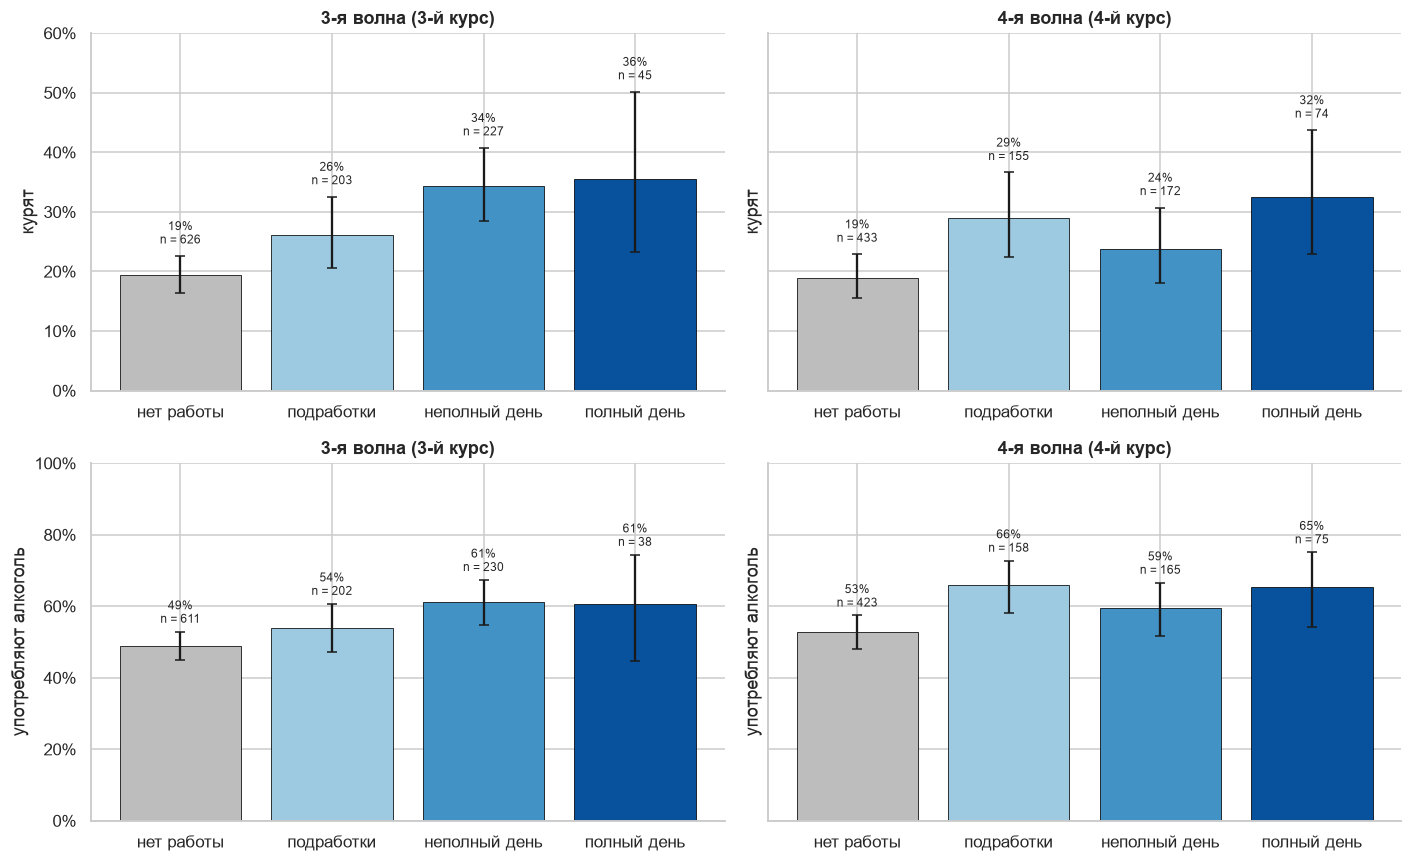

доля        от  \
курят                3-я волна (3-й курс) нет работы     0.193291  0.164266   
                                          подработки     0.261084  0.205499   
                                          неполный день  0.343612  0.284895   
                                          полный день    0.355556  0.232191   
                     4-я волна (4-й курс) нет работы     0.189376  0.155265   
                                          подработки     0.290323  0.224623   
                                          неполный день  0.238372  0.180851   
                                          полный день    0.324324  0.228641   
употребляют алкоголь 3-я волна (3-й курс) нет работы     0.489362  0.449915   
                                          подработки     0.539604  0.470771   
                                          неполный день  0.613043  0.548733   
                                          полный день    0.605263  0.447179   
                     4-я волна (4-й курс) нет работы     0.527187  0.479578   
                                          подработки     0.658228  0.581302   
                                          неполный день  0.593939  0.517696   
                                          полный день    0.653333  0.540547   

                                                               до      n  
курят                3-я волна (3-й курс) нет работы     0.226057  626.0  
                                          подработки     0.325542  203.0  
                                          неполный день  0.407534  227.0  
                                          полный день    0.501642   45.0  
                     4-я волна (4-й курс) нет работы     0.228951  433.0  
                                          подработки     0.366164  155.0  
                                          неполный день  0.307324  172.0  
                                          полный день    0.437347   74.0  
употребляют алкоголь 3-я волна (3-й курс) нет работы     0.528941  611.0  
                                          подработки     0.606959  202.0  
                                          неполный день  0.673640  230.0  
                                          полный день    0.744019   38.0  
                     4-я волна (4-й курс) нет работы     0.574306  423.0  
                                          подработки     0.727642  158.0  
                                          неполный день  0.665909  165.0  
                                          полный день    0.751177   75.0

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey='row')
tables = {}
for row, (var, label) in enumerate([('smoke', 'курят'), ('alco', 'употребляют алкоголь')]):
    for col, w in enumerate(['3', '4']):
        tables[(label, WAVES[w])] = bars(axes[row, col], in_wave[w], f'fmt_{w}', f'{var}_{w}', FORMATS,
                                         colors=[FORMAT_COLORS[f] for f in FORMATS], ylabel=label, title=WAVES[w],
                                         ymax=0.6 if var == 'smoke' else 1)
plt.tight_layout()
save(fig, 'H_Z5.5_smoking_alcohol')
plt.show()
pd.concat(tables)

Неработающие студенты курят реже работающих: 19% в обеих волнах против 24–36%. Употребление алкоголя также несколько чаще встречается среди работающих (54–66% против 49–53%). Различия между форматами занятости среди работающих непоследовательны между волнами. Полученные связи не позволяют судить о направлении влияния: студенты, выходящие на рынок труда, могут отличаться по образу жизни и до начала работы.

#### З5.6. Режим сна по формату занятости

Сохранено: figures/H_Z5.6_sleep_by_format.png


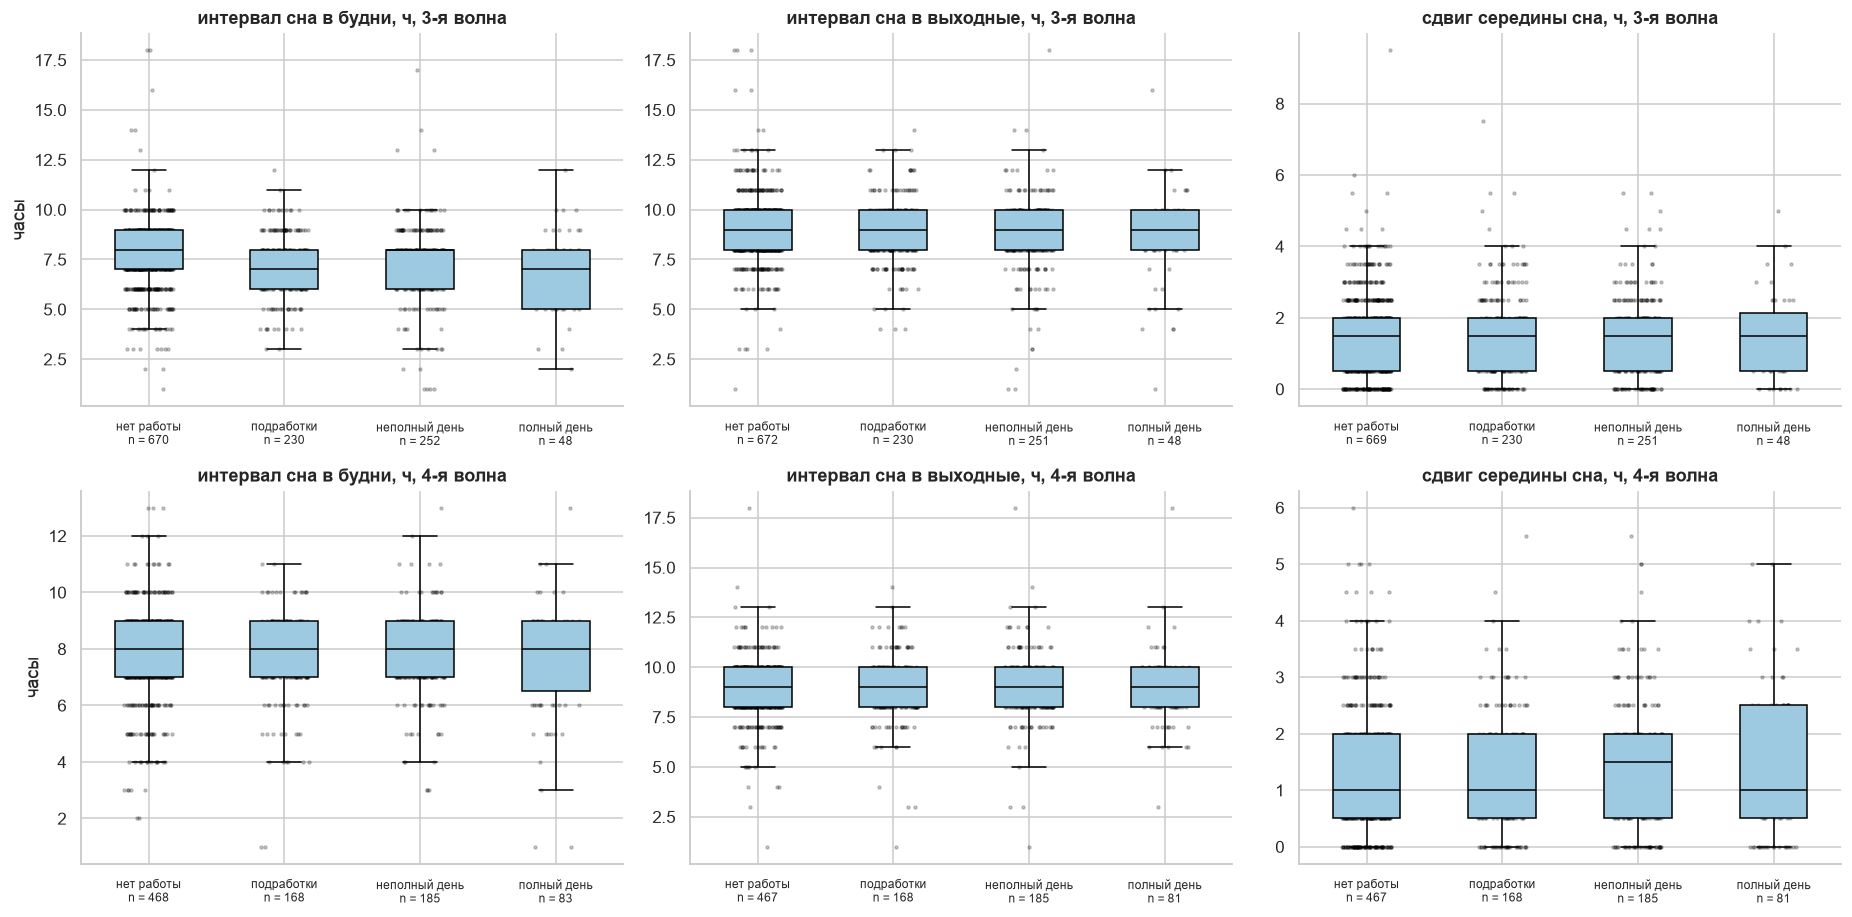

count  25%  \
3-я волна (3-й курс) интервал сна в будни, ч    нет работы     670.0  7.0   
                                                подработки     230.0  6.0   
                                                неполный день  252.0  6.0   
                                                полный день     48.0  5.0   
                     интервал сна в выходные, ч нет работы     672.0  8.0   
                                                подработки     230.0  8.0   
                                                неполный день  251.0  8.0   
                                                полный день     48.0  8.0   
                     сдвиг середины сна, ч      нет работы     669.0  0.5   
                                                подработки     230.0  0.5   
                                                неполный день  251.0  0.5   
                                                полный день     48.0  0.5   
4-я волна (4-й курс) интервал сна в будни, ч    нет работы     468.0  7.0   
                                                подработки     168.0  7.0   
                                                неполный день  185.0  7.0   
                                                полный день     83.0  6.5   
                     интервал сна в выходные, ч нет работы     467.0  8.0   
                                                подработки     168.0  8.0   
                                                неполный день  185.0  8.0   
                                                полный день     81.0  8.0   
                     сдвиг середины сна, ч      нет работы     467.0  0.5   
                                                подработки     168.0  0.5   
                                                неполный день  185.0  0.5   
                                                полный день     81.0  0.5   

                                                               50%    75%  
3-я волна (3-й курс) интервал сна в будни, ч    нет работы     8.0   9.00  
                                                подработки     7.0   8.00  
                                                неполный день  8.0   8.00  
                                                полный день    7.0   8.00  
                     интервал сна в выходные, ч нет работы     9.0  10.00  
                                                подработки     9.0  10.00  
                                                неполный день  9.0  10.00  
                                                полный день    9.0  10.00  
                     сдвиг середины сна, ч      нет работы     1.5   2.00  
                                                подработки     1.5   2.00  
                                                неполный день  1.5   2.00  
                                                полный день    1.5   2.12  
4-я волна (4-й курс) интервал сна в будни, ч    нет работы     8.0   9.00  
                                                подработки     8.0   9.00  
                                                неполный день  8.0   9.00  
                                                полный день    8.0   9.00  
                     интервал сна в выходные, ч нет работы     9.0  10.00  
                                                подработки     9.0  10.00  
                                                неполный день  9.0  10.00  
                                                полный день    9.0  10.00  
                     сдвиг середины сна, ч      нет работы     1.0   2.00  
                                                подработки     1.0   2.00  
                                                неполный день  1.5   2.00  
                                                полный день    1.0   2.50

In [38]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8.5))
tables = {}
for row, w in enumerate(['3', '4']):
    for col, (var, label) in enumerate([(f'sleep_dur_wd_{w}', 'интервал сна в будни, ч'),
                                        (f'sleep_dur_we_{w}', 'интервал сна в выходные, ч'), (f'sjl_{w}', 'сдвиг середины сна, ч')]):
        tables[(WAVES[w], label)] = boxes(axes[row, col], in_wave[w], f'fmt_{w}', var, FORMATS, title=f'{label}, {w}-я волна',
                                          ylabel='часы' if col == 0 else '')
        axes[row, col].tick_params(axis='x', labelsize=8)
plt.tight_layout()
save(fig, 'H_Z5.6_sleep_by_format')
plt.show()
pd.concat(tables)

На третьем курсе работающие полный день и подрабатывающие студенты спят в будни меньше неработающих (медиана 7 часов против 8; нижняя квартиль — 5–6 часов). Продолжительность сна в выходные (медиана 9 часов) и сдвиг середины сна по форматам не различаются. На четвёртом курсе различия по форматам практически отсутствуют.

### ИВ6. Планы распределения времени и трудоустройства

#### З6.1. Планируемая доля времени на работу по формату и мотиву (3-я волна)

Общее распределение — рисунок 6; рисунки для Г6.2 и Г6.3 — рисунок 5.

Сохранено: figures/H_Z6.1_work_share_by_group.png


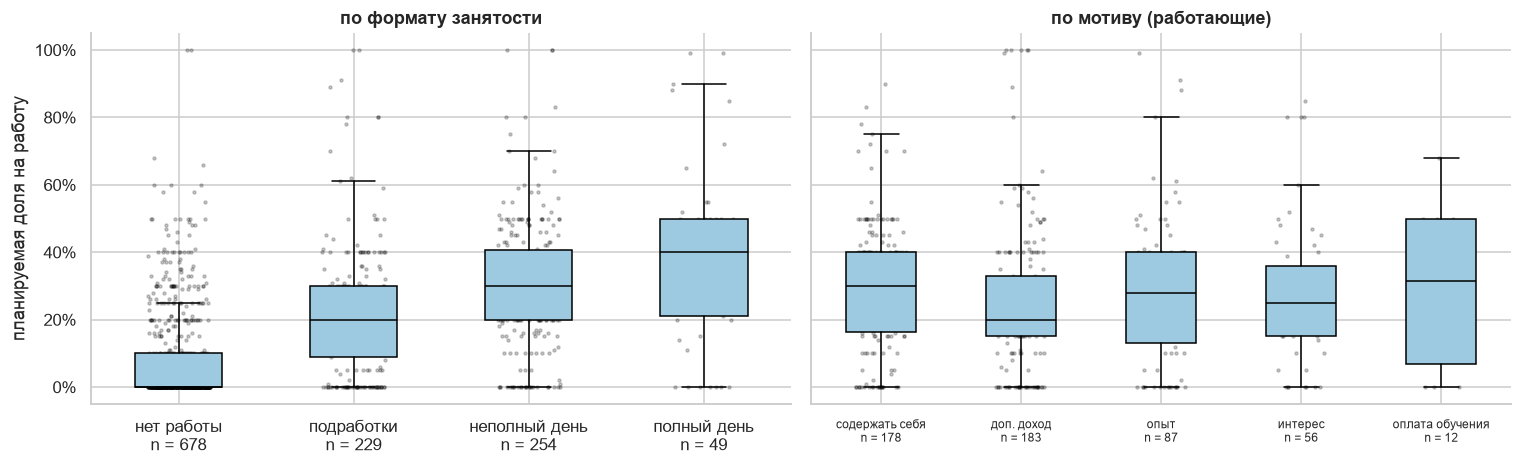

count   25%   50%   75%
формат нет работы       678.0  0.00  0.00  0.10
       подработки       229.0  0.09  0.20  0.30
       неполный день    254.0  0.20  0.30  0.41
       полный день       49.0  0.21  0.40  0.50
мотив  содержать себя   178.0  0.16  0.30  0.40
       доп. доход       183.0  0.15  0.20  0.33
       опыт              87.0  0.13  0.28  0.40
       интерес           56.0  0.15  0.25  0.36
       оплата обучения   12.0  0.07  0.32  0.50

In [39]:
alloc3 = d[d['hours_3w_1_st'].eq('VALID')]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
t1 = boxes(ax1, alloc3, 'fmt_3', 'alloc_работа_3', FORMATS, title='по формату занятости', ylabel='планируемая доля на работу')
t2 = boxes(ax2, alloc3[alloc3['emp_3'].eq(1)], 'motive_raw_3', 'alloc_работа_3', [m for m in MOTIVES if m != 'другое'], title='по мотиву (работающие)')
ax1.yaxis.set_major_formatter(percent)
ax2.tick_params(axis='x', labelsize=8)
plt.tight_layout()
save(fig, 'H_Z6.1_work_share_by_group')
plt.show()
pd.concat({'формат': t1, 'мотив': t2})

Планируемая доля времени на оплачиваемую работу последовательно возрастает с форматом фактической занятости: медиана составляет 0 у неработающих, 20% у подрабатывающих, 30% у работающих неполный день и 40% у работающих полный день. Планы, таким образом, согласуются с текущей занятостью в той же волне. По мотивам трудоустройства планируемая доля различается слабо (медианы 20–30%).

#### З6.4. Планируемая доля на работу и последующие оценки и удовлетворённость

Сохранено: figures/H_Z6.4_later_outcomes_by_plan.png


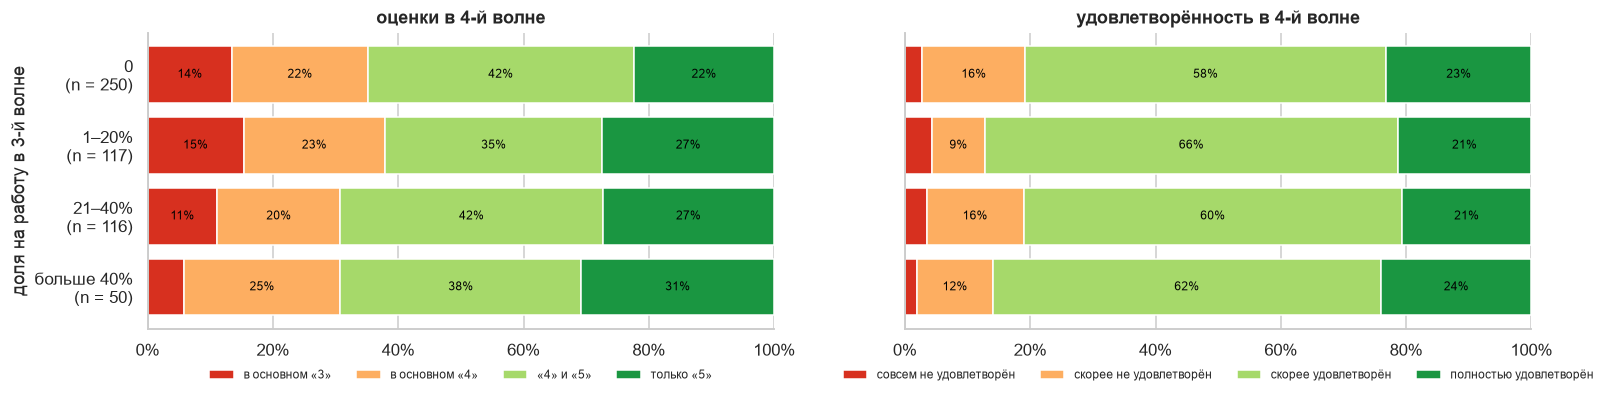

оценки


,в основном «3»,в основном «4»,«4» и «5»,только «5»,n
0,0.135,0.216,0.425,0.224,259
1–20%,0.153,0.226,0.347,0.274,124
21–40%,0.111,0.197,0.419,0.274,117
больше 40%,0.058,0.250,0.385,0.308,52


удовлетворённость


,совсем не удовлетворён,скорее не удовлетворён,скорее удовлетворён,полностью удовлетворён,n
0,0.028,0.164,0.576,0.232,250
1–20%,0.043,0.085,0.658,0.214,117
21–40%,0.034,0.155,0.603,0.207,116
больше 40%,0.020,0.120,0.620,0.240,50


In [40]:
panel = d[d['panel'] & d['hours_3w_1_st'].eq('VALID') & ~d['tech_4w']].assign(
    abin=lambda f: pd.cut(f['alloc_работа_3'], [-0.01, 0, 0.2, 0.4, 1], labels=['0', '1–20%', '21–40%', 'больше 40%']))
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), sharey=True)
t1 = stacked(axes[0], panel, 'abin', 'mark_4', ['0', '1–20%', '21–40%', 'больше 40%'], MARKS, RED_GREEN[4], title='оценки в 4-й волне')
t2 = stacked(axes[1], panel, 'abin', 'sat_4', ['0', '1–20%', '21–40%', 'больше 40%'], SAT, RED_GREEN[4], title='удовлетворённость в 4-й волне')
axes[0].set_ylabel('доля на работу в 3-й волне')
plt.tight_layout()
save(fig, 'H_Z6.4_later_outcomes_by_plan')
plt.show()
show_tables({'оценки': t1, 'удовлетворённость': t2})

Студенты, планировавшие на третьем курсе уделять работе более 40% времени, на четвёртом курсе реже получали в основном удовлетворительные оценки (6% против 11–15%) и чаще — только отличные (31% против 22–27%). Эта группа немногочисленна (52 человека), и с учётом исходной успеваемости связь не подтверждается. Удовлетворённость обучением от планов распределения времени не зависит.

### ИВ7. Изменения между волнами

#### Г7.2–Г7.3. Начало работы, удовлетворённость и оценки: до и после

Среди не работавших в 3-й волне. *Обе не подтверждаются:* OR = 1,13 и 0,93.

Сохранено: figures/H_G7.2-7.3_before_after.png


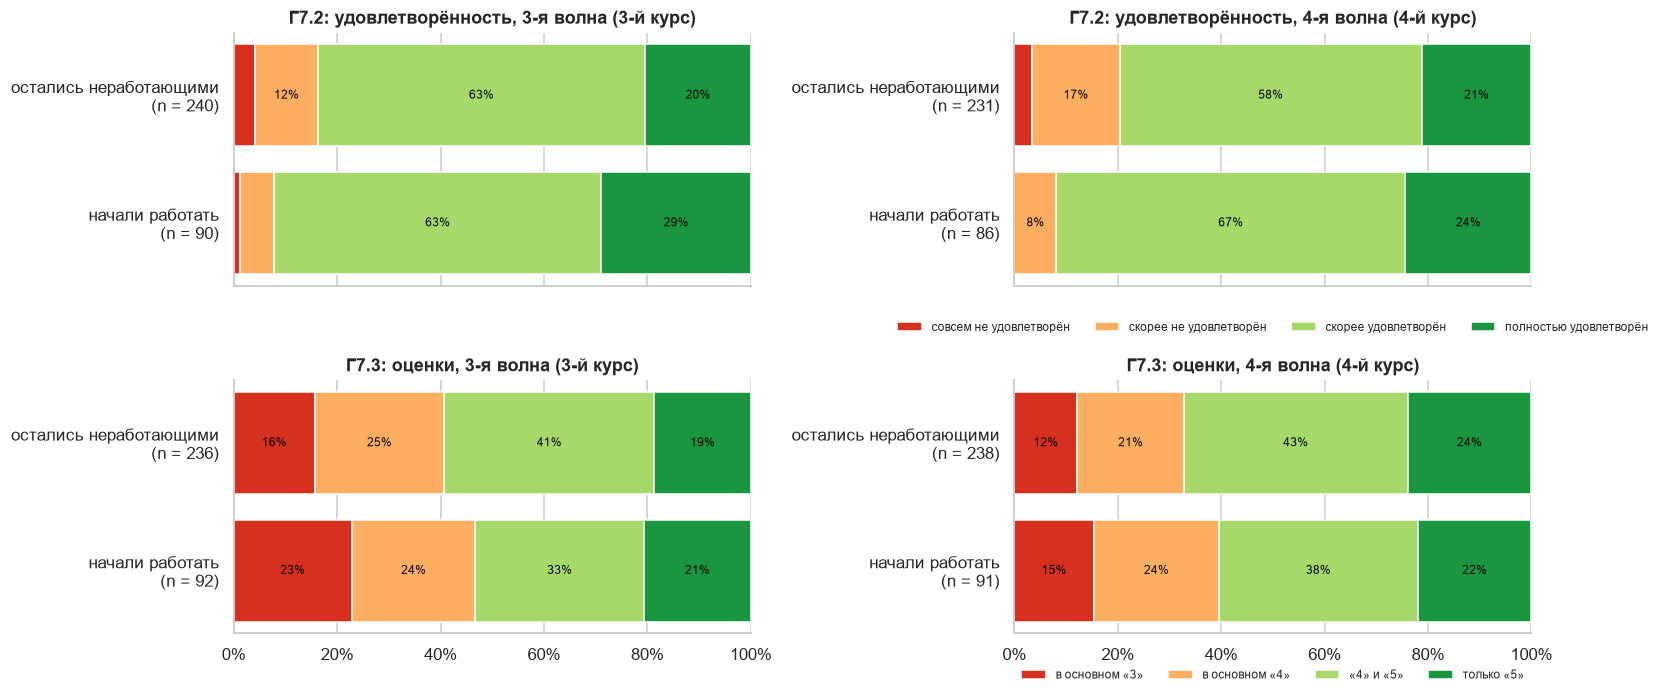

Г7.2: удовлетворённость


совсем не удовлетворён  \
3-я волна (3-й курс) остались неработающими                   0.042   
                     начали работать                          0.011   
4-я волна (4-й курс) остались неработающими                   0.035   
                     начали работать                          0.000   

                                             скорее не удовлетворён  \
3-я волна (3-й курс) остались неработающими                   0.121   
                     начали работать                          0.067   
4-я волна (4-й курс) остались неработающими                   0.169   
                     начали работать                          0.081   

                                             скорее удовлетворён  \
3-я волна (3-й курс) остались неработающими                0.633   
                     начали работать                       0.633   
4-я волна (4-й курс) остались неработающими                0.584   
                     начали работать                       0.674   

                                             полностью удовлетворён    n  
3-я волна (3-й курс) остались неработающими                   0.204  240  
                     начали работать                          0.289   90  
4-я волна (4-й курс) остались неработающими                   0.212  231  
                     начали работать                          0.244   86

Г7.3: оценки


в основном «3»  в основном «4»  \
3-я волна (3-й курс) остались неработающими           0.157           0.250   
                     начали работать                  0.228           0.239   
4-я волна (4-й курс) остались неработающими           0.122           0.206   
                     начали работать                  0.154           0.242   

                                             «4» и «5»  только «5»    n  
3-я волна (3-й курс) остались неработающими      0.407       0.186  236  
                     начали работать             0.326       0.207   92  
4-я волна (4-й курс) остались неработающими      0.433       0.239  238  
                     начали работать             0.385       0.220   91

In [41]:
nw = d[d['start_work'].notna()]
START = {0: 'остались неработающими', 1: 'начали работать'}
fig, axes = plt.subplots(2, 2, figsize=(15, 6.5), sharex=True)
tables = {}
for row, (var, levels, label) in enumerate([('sat', SAT, 'Г7.2: удовлетворённость'), ('mark', MARKS, 'Г7.3: оценки')]):
    for col, w in enumerate(['3', '4']):
        tables[(label, WAVES[w])] = stacked(axes[row, col], nw, 'start_work', f'{var}_{w}', START, levels, RED_GREEN[4],
                                            title=f'{label}, {WAVES[w]}', legend=(col == 1))
plt.tight_layout()
save(fig, 'H_G7.2-7.3_before_after')
plt.show()
show_tables(tables)

Студенты, начавшие работать к четвёртому курсу, уже на третьем курсе были удовлетворены обучением в большей степени, чем оставшиеся неработающими (полностью удовлетворены 29% против 20%); на четвёртом курсе различие сохраняется (24% против 21%), снижения удовлетворённости не наблюдается (Г7.2 не подтверждается). По успеваемости начавшие работать на третьем курсе несколько уступали остальным (удовлетворительные оценки у 23% против 16%), к четвёртому курсу различие сократилось (15% против 12%; Г7.3 не подтверждается). Исходные различия между группами показывают, что сравнение только по четвёртой волне было бы смещённым; в моделях учитывается показатель третьей волны.

#### Г7.4. Изменение рабочих часов и сна

Работавшие в обеих волнах. *Не подтверждается:* b = 0,03 ч на 10 часов. Линия — сглаживание LOWESS.

Сохранено: figures/H_G7.4_change_hours_sleep.png


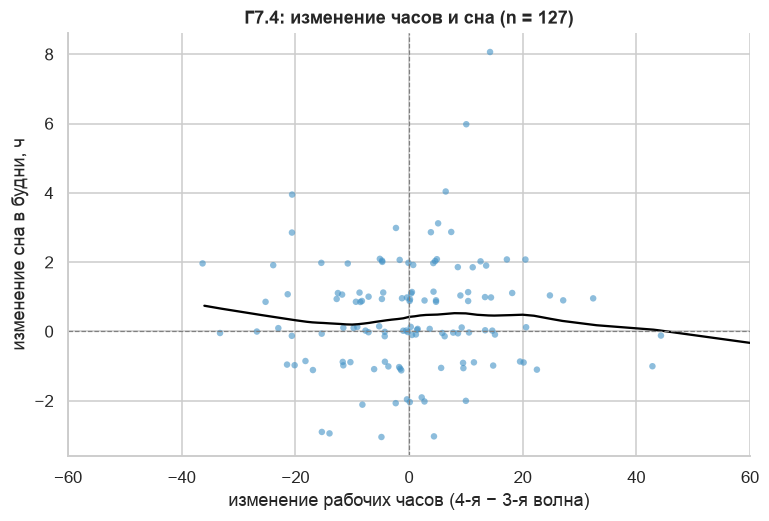

,count,mean,std,min,25%,50%,75%,max
d_hours,127.0,1.40,16.49,-36.0,-8.5,0.0,10.0,85.0
d_sleep_wd,127.0,0.45,1.66,-3.0,-1.0,0.0,1.0,8.0


In [42]:
both = d[d['trans4'].eq('работал в обеих')].dropna(subset=['d_hours', 'd_sleep_wd'])
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(both['d_hours'] + rng.uniform(-0.8, 0.8, len(both)), both['d_sleep_wd'] + rng.uniform(-0.15, 0.15, len(both)),
           s=18, color='#4292c6', alpha=0.6, edgecolor='none')
sns.regplot(data=both, x='d_hours', y='d_sleep_wd', lowess=True, scatter=False, ax=ax, color='black', line_kws={'lw': 1.5})
ax.axhline(0, color='grey', lw=0.8, ls='--')
ax.axvline(0, color='grey', lw=0.8, ls='--')
ax.set(xlabel='изменение рабочих часов (4-я − 3-я волна)', ylabel='изменение сна в будни, ч',
       title=f'Г7.4: изменение часов и сна (n = {len(both)})', xlim=(-60, 60))
save(fig, 'H_G7.4_change_hours_sleep')
plt.show()
both[['d_hours', 'd_sleep_wd']].describe().T.round(2)

Среди работавших в обеих волнах изменение рабочих часов (медиана 0, размах от −36 до +85 часов) не связано с изменением ночного интервала сна в будни (медиана 0): линия сглаживания практически горизонтальна (Г7.4 не подтверждается). Вывод ограничен малой численностью выборки (127 человек) и небольшой изменчивостью нагрузки.

#### Г7.5. Опыт стажировки и выход на работу

*Не подтверждается:* OR = 0,93.

Сохранено: figures/H_G7.5_start_by_internship.png


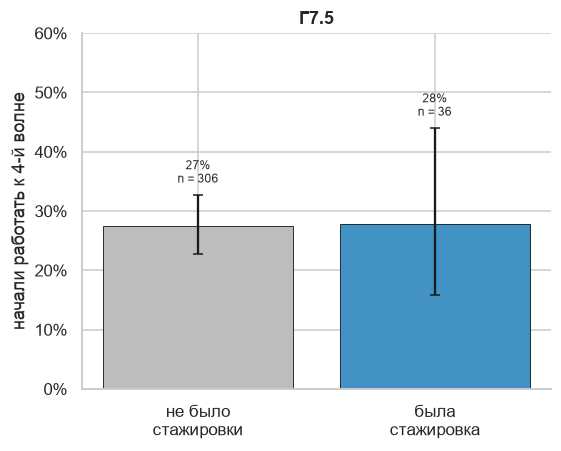

,доля,от,до,n
не было\nстажировки,0.274510,0.227536,0.327075,306.0
была\nстажировка,0.277778,0.158483,0.439925,36.0


In [43]:
fig, ax = plt.subplots(figsize=(5.5, 4.2))
table = bars(ax, nw, 'intern_3', 'start_work', {0: 'не было\nстажировки', 1: 'была\nстажировка'}, colors=GREY_BLUE,
             ylabel='начали работать к 4-й волне', title='Г7.5', ymax=0.6)
save(fig, 'H_G7.5_start_by_internship')
plt.show()
table

Доля начавших работать к четвёртому курсу практически одинакова среди не проходивших (27%) и проходивших стажировку (28%) (Г7.5 не подтверждается). Число стажировавшихся среди не работавших на третьем курсе невелико (36 человек), что обусловливает широкий доверительный интервал (16–44%).

#### З7.6. Изменения здоровья и образования при разных переходах занятости

Курение, алкоголь и спорт — только по содержательным ответам в обеих волнах.

Сохранено: figures/H_Z7.6_health_changes.png


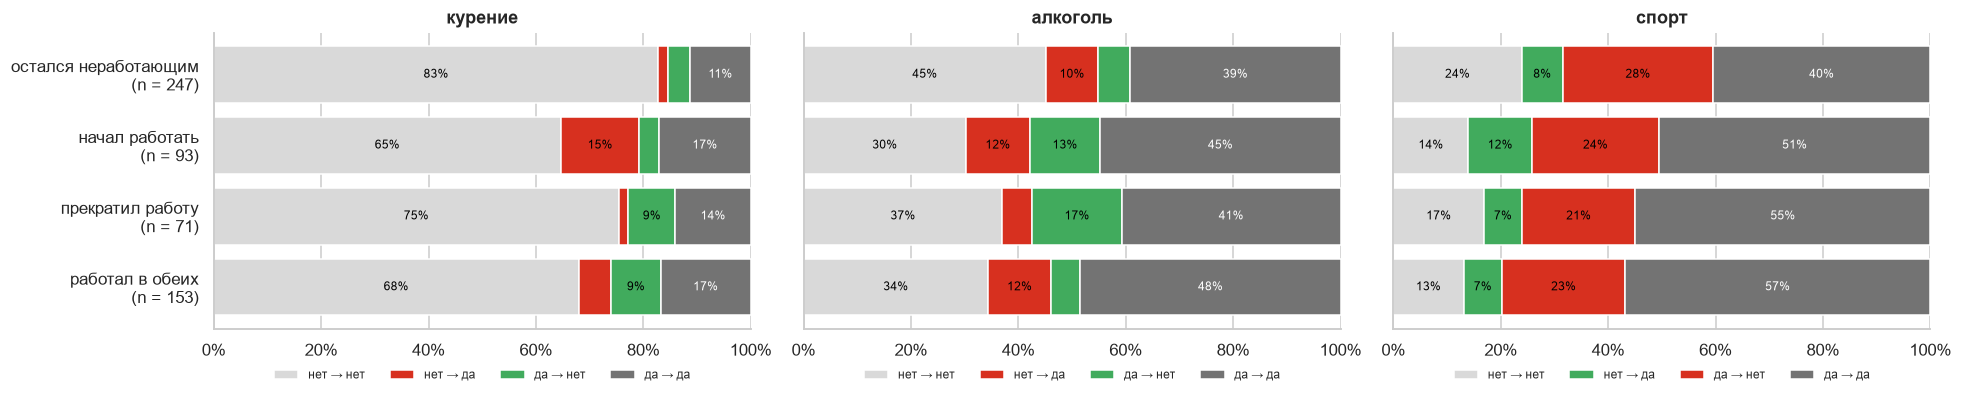

нет → нет  нет → да  да → нет  да → да    n
курение  остался неработающим      0.828     0.018     0.041    0.113  221
         начал работать            0.646     0.146     0.037    0.171   82
         прекратил работу          0.754     0.018     0.088    0.140   57
         работал в обеих           0.679     0.061     0.092    0.168  131
алкоголь остался неработающим      0.452     0.097     0.060    0.392  217
         начал работать            0.303     0.118     0.132    0.447   76
         прекратил работу          0.370     0.056     0.167    0.407   54
         работал в обеих           0.344     0.117     0.055    0.484  128
спорт    остался неработающим      0.239     0.077     0.279    0.405  247
         начал работать            0.140     0.118     0.237    0.505   93
         прекратил работу          0.169     0.070     0.211    0.549   71
         работал в обеих           0.131     0.072     0.229    0.569  153

In [44]:
TRANS = ['остался неработающим', 'начал работать', 'прекратил работу', 'работал в обеих']
CHANGE = {'0→0': 'нет → нет', '0→1': 'нет → да', '1→0': 'да → нет', '1→1': 'да → да'}
CHANGE_COLORS = ['#d9d9d9', '#d7301f', '#41ab5d', '#737373']
fig, axes = plt.subplots(1, 3, figsize=(18, 3.8), sharey=True)
tables = {}
for ax, (var, label) in zip(axes, [('smoke_change', 'курение'), ('alco_change', 'алкоголь'), ('pe_change', 'спорт')]):
    colors = CHANGE_COLORS if var != 'pe_change' else ['#d9d9d9', '#41ab5d', '#d7301f', '#737373']
    tables[label] = stacked(ax, d, 'trans4', var, TRANS, CHANGE, colors, title=label, legend=True)
plt.tight_layout()
save(fig, 'H_Z7.6_health_changes')
plt.show()
pd.concat(tables)

Среди начавших работать к четвёртому курсу 15% начали курить против 2% среди оставшихся неработающими и прекративших работу. Прекращение занятий спортом встречается во всех группах (21–28%); при этом среди оставшихся неработающими занимаются спортом в обеих волнах наименьшая доля студентов (41% против 51–57%). Изменения в употреблении алкоголя невелики и сходны между группами. Связь начала работы с началом курения является разведочным результатом и требует проверки на независимых данных.

Сохранено: figures/H_Z7.6_dropout_edu_changes.png


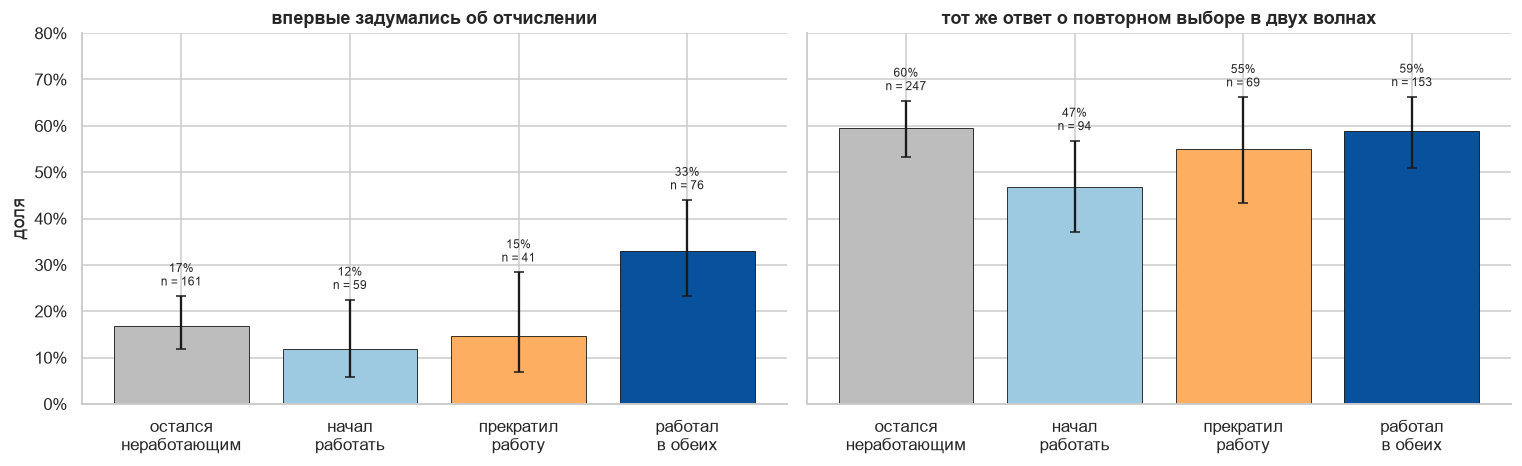

доля        от        до  \
впервые об отчислении  остался\nнеработающим  0.167702  0.117890  0.233002   
                       начал\nработать        0.118644  0.058676  0.225236   
                       прекратил\nработу      0.146341  0.068842  0.284435   
                       работал\nв обеих       0.328947  0.233793  0.440562   
тот же повторный выбор остался\nнеработающим  0.595142  0.532922  0.654447   
                       начал\nработать        0.468085  0.370459  0.568217   
                       прекратил\nработу      0.550725  0.433788  0.662311   
                       работал\nв обеих       0.588235  0.509021  0.663127   

                                                  n  
впервые об отчислении  остался\nнеработающим  161.0  
                       начал\nработать         59.0  
                       прекратил\nработу       41.0  
                       работал\nв обеих        76.0  
тот же повторный выбор остался\nнеработающим  247.0  
                       начал\nработать         94.0  
                       прекратил\nработу       69.0  
                       работал\nв обеих       153.0

In [45]:
trans = d[d['trans4'].notna()].assign(same_edu=lambda f: (f['edu3_3'].astype(object) == f['edu3_4'].astype(object))
                                      .astype(float).where(f['edu3_3'].notna() & f['edu3_4'].notna()))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
colors = ['#bdbdbd', '#9ecae1', '#fdae61', '#08519c']
t1 = bars(ax1, trans, 'trans4', 'new_drop_4', {t: t.replace(' ', '\n', 1) for t in TRANS}, colors=colors, ymax=0.8,
          title='впервые задумались об отчислении', ylabel='доля')
t2 = bars(ax2, trans, 'trans4', 'same_edu', {t: t.replace(' ', '\n', 1) for t in TRANS}, colors=colors, ymax=0.8,
          title='тот же ответ о повторном выборе в двух волнах')
plt.tight_layout()
save(fig, 'H_Z7.6_dropout_edu_changes')
plt.show()
pd.concat({'впервые об отчислении': t1, 'тот же повторный выбор': t2})

Мысли об отчислении впервые возникли у 33% студентов, работавших в обеих волнах, против 12–17% в остальных группах. Ответ о повторном выборе образования совпал в двух волнах у 47–60% студентов; реже всего — у начавших работать (47%), однако различия между группами незначимы.

## 10. Распределения всех аналитических переменных

Каждая переменная — по волнам; частично заполненные анкеты (профили A/B) исключены только из показателей 4-й волны. Шкалы 1–4 работы и удовлетворённость — рисунок П1, сферы — рисунок П2.

### П3. Бинарные показатели: доли «да» с 95% ДИ

Сохранено: figures/V_binary.png


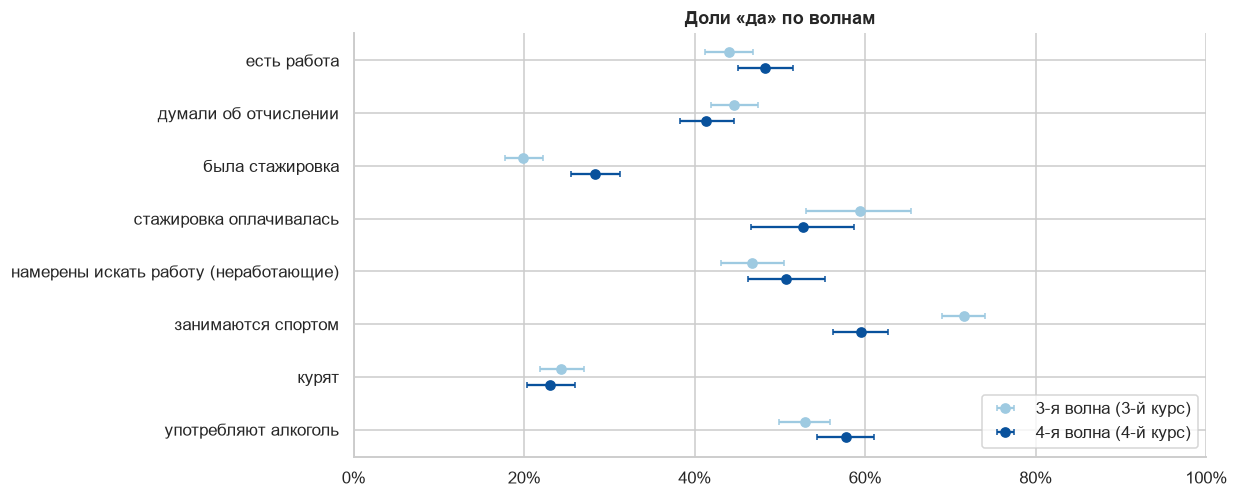

доля     от  \
3-я волна (3-й курс) есть работа                            0.440  0.412   
                     думали об отчислении                   0.446  0.419   
                     была стажировка                        0.199  0.177   
                     стажировка оплачивалась                0.593  0.530   
                     намерены искать работу (неработающие)  0.468  0.430   
                     занимаются спортом                     0.716  0.690   
                     курят                                  0.243  0.219   
                     употребляют алкоголь                   0.529  0.499   
4-я волна (4-й курс) есть работа                            0.482  0.450   
                     думали об отчислении                   0.414  0.383   
                     была стажировка                        0.283  0.254   
                     стажировка оплачивалась                0.527  0.466   
                     намерены искать работу (неработающие)  0.507  0.462   
                     занимаются спортом                     0.595  0.563   
                     курят                                  0.230  0.203   
                     употребляют алкоголь                   0.577  0.543   

                                                               до       n  
3-я волна (3-й курс) есть работа                            0.468  1211.0  
                     думали об отчислении                   0.474  1223.0  
                     была стажировка                        0.222  1211.0  
                     стажировка оплачивалась                0.653   241.0  
                     намерены искать работу (неработающие)  0.505   678.0  
                     занимаются спортом                     0.741  1208.0  
                     курят                                  0.270  1101.0  
                     употребляют алкоголь                   0.559  1081.0  
4-я волна (4-й курс) есть работа                            0.515   914.0  
                     думали об отчислении                   0.445   938.0  
                     была стажировка                        0.313   913.0  
                     стажировка оплачивалась                0.587   258.0  
                     намерены искать работу (неработающие)  0.552   473.0  
                     занимаются спортом                     0.626   911.0  
                     курят                                  0.260   834.0  
                     употребляют алкоголь                   0.611   821.0

In [46]:
BINARY = {'emp': 'есть работа', 'drop_any': 'думали об отчислении', 'intern': 'была стажировка', 'intern_paid': 'стажировка оплачивалась',
          'intent': 'намерены искать работу (неработающие)', 'pe': 'занимаются спортом', 'smoke': 'курят', 'alco': 'употребляют алкоголь'}
table = pd.concat({WAVES[w]: pd.DataFrame({label: share_ci(wave_values(v, w)) for v, label in BINARY.items()}).T
                   for w in ['3', '4']})
fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(BINARY))
for dy, w, color in [(-0.15, '3', '#9ecae1'), (0.15, '4', '#08519c')]:
    t = table.loc[WAVES[w]]
    ax.errorbar(t['доля'], y + dy, xerr=[t['доля'] - t['от'], t['до'] - t['доля']], fmt='o', color=color, capsize=2, label=WAVES[w])
ax.set_yticks(y, list(BINARY.values()))
ax.invert_yaxis()
ax.xaxis.set_major_formatter(percent)
ax.set(xlim=(0, 1), title='Доли «да» по волнам')
ax.legend(loc='lower right')
save(fig, 'V_binary')
plt.show()
table.round(3)

От третьего к четвёртому курсу возрастают доли работающих (с 44% до 48%) и имеющих опыт стажировки (с 20% до 28%), тогда как доля занимающихся спортом снижается (с 72% до 60%). Доли курящих (24% и 23%), употребляющих алкоголь (53% и 58%) и задумывавшихся об отчислении (45% и 41%) изменяются незначительно.

### П4. Категориальные переменные

Сохранено: figures/V_categorical.png


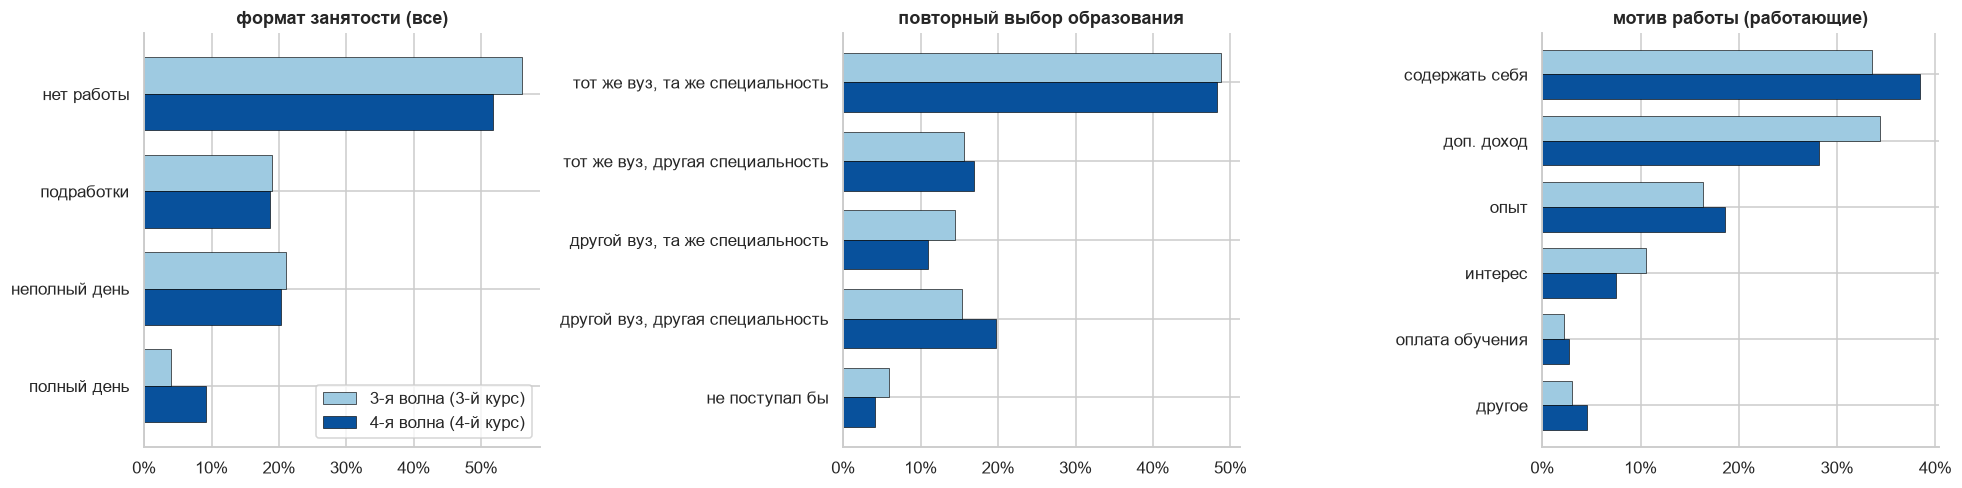

3-я волна (3-й курс)  \
формат занятости (все)      нет работы                                       0.560   
                            подработки                                       0.190   
                            неполный день                                    0.210   
                            полный день                                      0.040   
повторный выбор образования тот же вуз, та же специальность                  0.487   
                            тот же вуз, другая специальность                 0.155   
                            другой вуз, та же специальность                  0.144   
                            другой вуз, другая специальность                 0.154   
                            не поступал бы                                   0.060   
мотив работы (работающие)   содержать себя                                   0.336   
                            доп. доход                                       0.343   
                            опыт                                             0.163   
                            интерес                                          0.105   
                            оплата обучения                                  0.023   
                            другое                                           0.030   

                                                              4-я волна (4-й курс)  
формат занятости (все)      нет работы                                       0.518  
                            подработки                                       0.187  
                            неполный день                                    0.204  
                            полный день                                      0.092  
повторный выбор образования тот же вуз, та же специальность                  0.483  
                            тот же вуз, другая специальность                 0.169  
                            другой вуз, та же специальность                  0.109  
                            другой вуз, другая специальность                 0.198  
                            не поступал бы                                   0.042  
мотив работы (работающие)   содержать себя                                   0.384  
                            доп. доход                                       0.282  
                            опыт                                             0.186  
                            интерес                                          0.075  
                            оплата обучения                                  0.027  
                            другое                                           0.045

In [47]:
CATS = [('fmt', FORMATS, 'формат занятости (все)'), ('edu3', EDU3, 'повторный выбор образования'),
        ('motive_raw', MOTIVES, 'мотив работы (работающие)')]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
tables = {}
for ax, (var, cats, label) in zip(axes, CATS):
    t = pd.DataFrame({WAVES[w]: wave_values(var, w).astype(object).value_counts(normalize=True).reindex(cats, fill_value=0)
                      for w in ['3', '4']})
    t.plot.barh(ax=ax, color=['#9ecae1', '#08519c'], edgecolor='black', linewidth=0.4, width=0.75, legend=(ax is axes[0]))
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(percent)
    ax.set(title=label)
    tables[label] = t
plt.tight_layout()
save(fig, 'V_categorical')
plt.show()
pd.concat(tables).round(3)

Около половины студентов выбрали бы тот же вуз и ту же специальность (50% и 48%); не поступали бы в вуз 4–6%. Структура мотивов трудоустройства и форматов занятости в двух волнах близка; единственное заметное изменение — рост доли работающих полный день (с 4% до 9%).

Сохранено: figures/V_social.png


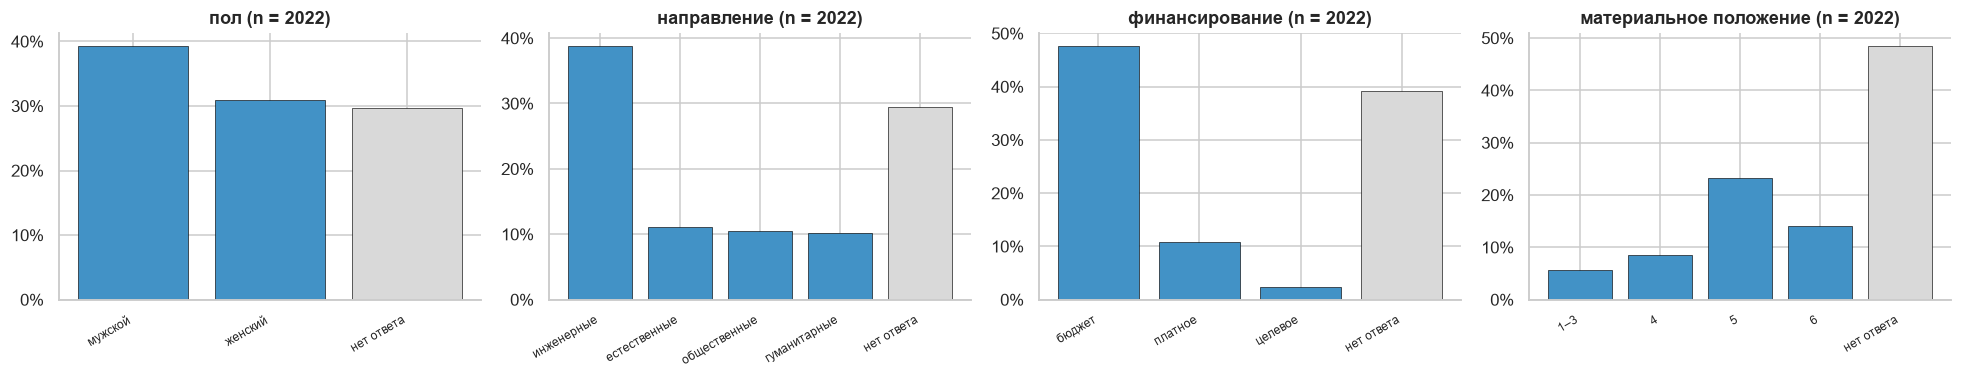

n
пол                    мужской       795
                       женский       626
                       нет ответа    601
направление            инженерные    785
                       естественные  224
                       общественные  212
                       гуманитарные  206
                       нет ответа    595
финансирование         бюджет        964
                       платное       218
                       целевое        48
                       нет ответа    792
материальное положение 1–3           115
                       4             173
                       5             470
                       6             283
                       нет ответа    981

In [48]:
# Социальные характеристики (рабочий массив, без восстановления)
SOCIAL_VARS = [('sex_c', 'пол'), ('major_c', 'направление'), ('funding_c', 'финансирование'), ('ses4', 'материальное положение')]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
tables = {}
for ax, (var, label) in zip(axes, SOCIAL_VARS):
    t = d[var].astype(object).fillna('нет ответа').value_counts()
    t = t.reindex([c for c in list(d[var].cat.categories) + ['нет ответа'] if c in t.index])
    ax.bar(range(len(t)), t / t.sum(), color=['#4292c6'] * (len(t) - 1) + ['#d9d9d9'], edgecolor='black', linewidth=0.4)
    ax.set_xticks(range(len(t)), t.index, rotation=30, ha='right', fontsize=8)
    ax.yaxis.set_major_formatter(percent)
    ax.set(title=f'{label} (n = {t.sum()})')
    tables[label] = t
plt.tight_layout()
save(fig, 'V_social')
plt.show()
pd.concat(tables).to_frame('n')

Социальные характеристики пропущены у значительной части рабочего массива: пол и направление подготовки — около 30%, форма финансирования — 39%, материальное положение семьи — 49%. В основном это участники только четвёртой волны. В основном анализе эти пропуски восстановлены методом множественного восстановления. Среди ответивших преобладают студенты инженерных направлений (55%), обучающиеся на бюджетной основе (78%) и представители материально обеспеченных семей (уровни 5–6 — 72%).

### П5. Непрерывные показатели

Сохранено: figures/V_continuous.png


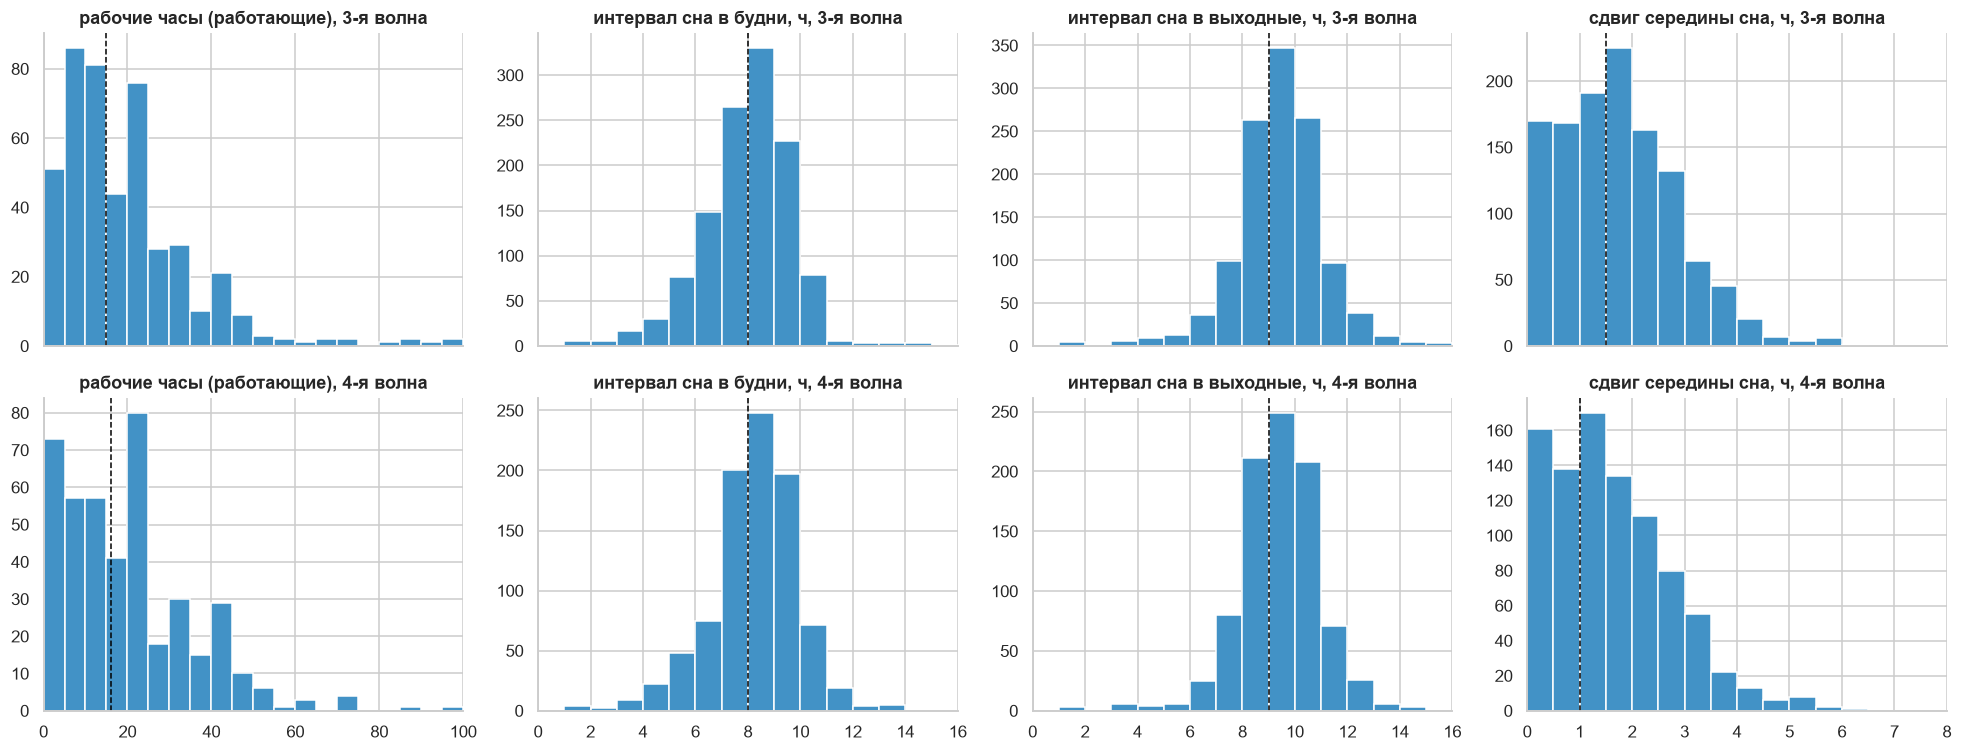

count   mean  25%   50%  \
рабочие часы (работающие)  3-я волна (3-й курс)   454.0  19.21  8.0  15.0   
                           4-я волна (4-й курс)   427.0  19.01  7.0  16.0   
интервал сна в будни, ч    3-я волна (3-й курс)  1200.0   7.52  7.0   8.0   
                           4-я волна (4-й курс)   904.0   7.75  7.0   8.0   
интервал сна в выходные, ч 3-я волна (3-й курс)  1201.0   8.97  8.0   9.0   
                           4-я волна (4-й курс)   901.0   8.94  8.0   9.0   
сдвиг середины сна, ч      3-я волна (3-й курс)  1198.0   1.51  0.5   1.5   
                           4-я волна (4-й курс)   901.0   1.38  0.5   1.0   

                                                  75%    max  
рабочие часы (работающие)  3-я волна (3-й курс)  25.0  168.0  
                           4-я волна (4-й курс)  26.0  168.0  
интервал сна в будни, ч    3-я волна (3-й курс)   9.0   18.0  
                           4-я волна (4-й курс)   9.0   13.0  
интервал сна в выходные, ч 3-я волна (3-й курс)  10.0   18.0  
                           4-я волна (4-й курс)  10.0   18.0  
сдвиг середины сна, ч      3-я волна (3-й курс)   2.0    9.5  
                           4-я волна (4-й курс)   2.0    6.0

In [49]:
CONT = [('hours', 'рабочие часы (работающие)', (0, 100), 5), ('sleep_dur_wd', 'интервал сна в будни, ч', (0, 16), 1),
        ('sleep_dur_we', 'интервал сна в выходные, ч', (0, 16), 1), ('sjl', 'сдвиг середины сна, ч', (0, 8), 0.5)]
fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharex='col')
tables = {}
for col, (var, label, xlim, step) in enumerate(CONT):
    for row, w in enumerate(['3', '4']):
        s = wave_values(var, w).dropna()
        axes[row, col].hist(s, bins=np.arange(xlim[0], xlim[1] + step, step), color='#4292c6', edgecolor='white')
        axes[row, col].axvline(s.median(), color='black', ls='--', lw=1)
        axes[row, col].set(title=f'{label}, {w}-я волна', xlim=xlim)
        tables[(label, WAVES[w])] = s.describe()[['count', 'mean', '25%', '50%', '75%', 'max']]
plt.tight_layout()
save(fig, 'V_continuous')
plt.show()
pd.DataFrame(tables).T.round(2)

Медиана рабочих часов составляет 15–16 часов в неделю при длинном правом хвосте распределения (значения более 100 часов отмечены как сомнительные). Типичный ночной интервал составляет 8 часов в будни и 9 часов в выходные, сдвиг середины сна — около 1–1,5 часа. Распределения в двух волнах практически совпадают.

Сохранено: figures/V_internship_scales.png


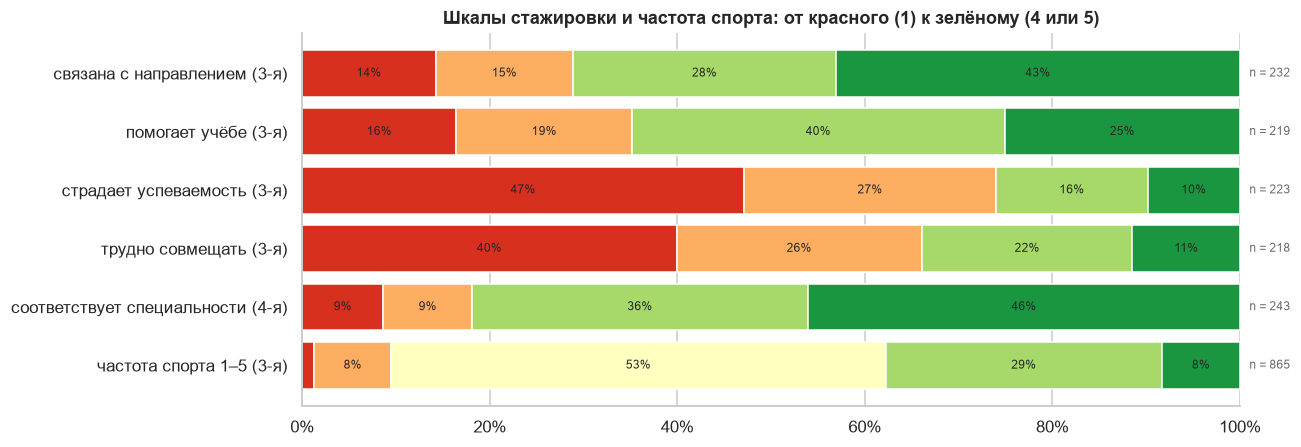

,1,2,3,4,5
связана с направлением (3-я),0.142,0.147,0.280,0.431,NaN
помогает учёбе (3-я),0.164,0.187,0.397,0.251,NaN
страдает успеваемость (3-я),0.471,0.269,0.161,0.099,NaN
трудно совмещать (3-я),0.399,0.261,0.225,0.115,NaN
соответствует специальности (4-я),0.086,0.095,0.358,0.461,NaN
частота спорта 1–5 (3-я),0.013,0.082,0.527,0.295,0.083


In [50]:
# Оценки стажировки (3-я волна) и соответствие стажировки (4-я волна)
INTERN_SCALES = {'intern_fit_3': 'связана с направлением (3-я)', 'intern_benefit_3': 'помогает учёбе (3-я)',
                 'intern_harm_3': 'страдает успеваемость (3-я)', 'intern_difficulty_3': 'трудно совмещать (3-я)',
                 'intern_fit_4': 'соответствует специальности (4-я)', 'pe_freq_3': 'частота спорта 1–5 (3-я)'}
fig, ax = plt.subplots(figsize=(11, 4.4))
tables = {}
for i, (var, label) in enumerate(INTERN_SCALES.items()):
    values = d[var].dropna()
    k = 5 if var == 'pe_freq_3' else 4
    shares = values.value_counts(normalize=True).reindex(range(1, k + 1), fill_value=0)
    left = 0
    for v, color in zip(shares, RED_GREEN[k]):
        ax.barh(i, v, left=left, color=color, edgecolor='white')
        if v > 0.07:
            ax.text(left + v / 2, i, f'{v:.0%}', ha='center', va='center', fontsize=8)
        left += v
    ax.text(1.01, i, f'n = {len(values)}', va='center', fontsize=8, color='dimgray', transform=ax.get_yaxis_transform())
    tables[label] = shares
ax.set_yticks(range(len(INTERN_SCALES)), list(INTERN_SCALES.values()))
ax.invert_yaxis()
ax.xaxis.set_major_formatter(percent)
ax.set(xlim=(0, 1), title='Шкалы стажировки и частота спорта: от красного (1) к зелёному (4 или 5)')
save(fig, 'V_internship_scales')
plt.show()
pd.DataFrame(tables).T.round(3)

Стажировки в целом оцениваются положительно: 71% студентов считают их связанными с направлением обучения, 65% — полезными для учёбы, ущерб успеваемости признают 26%, трудности совмещения — 34%. В четвёртой волне соответствие стажировки специальности оценивается ещё выше (82%). Большинство занимающихся спортом делают это один-два раза в неделю (53%).